# AXXEL CAPITAL · Kronos SFT verificado
**Modelo:** NeoQuasar/Kronos-small + Kronos-Tokenizer-base. Este cuaderno reemplaza la preparación incompleta basada en Chronos, en una copia independiente.

Ejecuta las celdas 1–8 en orden. Se verifican 30 Parquet, se construyen ventanas M5/M15, se prueban máscaras y causalidad y se realizan **3 actualizaciones de entrenamiento por temporalidad**.
Los ZIP y Parquet originales se leen sin modificarlos. Cada ejecución genera una carpeta nueva con código, índices, resultados y checkpoints. El entrenamiento completo tiene una celda separada desactivada por defecto, como se acordó.

**Límites:** la prueba corta verifica funcionamiento, no ventaja predictiva. Test 2023–2024 se reserva. Los ticks 2024–2026 permanecen excluidos hasta resolver cobertura, escalas y volumen. Su sesión aislada no alcanza para los contextos actuales.

## 1. Dependencias y entorno

In [ ]:
import sys, subprocess, importlib.metadata as metadata
# Se conserva el PyTorch del runtime; su versión y dispositivo se registran y prueban.
requirements = ['einops==0.8.2','safetensors==0.6.2','huggingface_hub==1.4.0',
                'numpy==2.2.6','pandas==2.3.3','pyarrow==23.0.0','tqdm==4.67.1']
subprocess.run([sys.executable,'-m','pip','install','-q',*requirements],check=True)
import torch
assert hasattr(torch.nn.functional,'scaled_dot_product_attention'), 'PyTorch incompatible'
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4,__import__('os').cpu_count() or 1))
print('Dispositivo:',DEVICE,'| PyTorch:',torch.__version__)
if DEVICE.type=='cuda': print(torch.cuda.get_device_name(),torch.cuda.get_device_properties(0).total_memory)
print('Precisión inicial: float32; batch de prueba: 1. No se fuerza bfloat16.')


Dispositivo: cpu | PyTorch: 2.14.1+cpu
Precisión inicial: float32; batch de prueba: 1. No se fuerza bfloat16.


## 2. Drive y carpeta nueva de ejecución

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import uuid, json, hashlib, platform
from google.colab import drive
if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')
BASE=Path('/content/drive/MyDrive/AXXEL_CAPITAL')
SOURCE=BASE/'datasets/processed/kronos_ohlcv_v1'
assert SOURCE.is_dir(), f'No se encontró {SOURCE}'
RUN_ID=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:6]
WORK=BASE/'Kronos_SFT_verificado_20261107'/'ejecuciones'/RUN_ID
WORK.mkdir(parents=True,exist_ok=False)
OUTPUT=WORK/'resultados'
print('Origen de solo lectura:',SOURCE)
print('Nueva ejecución:',WORK)


Mounted at /content/drive
Origen de solo lectura: /content/drive/MyDrive/AXXEL_CAPITAL/datasets/processed/kronos_ohlcv_v1
Nueva ejecución: /content/drive/MyDrive/AXXEL_CAPITAL/Kronos_SFT_verificado_20261107/ejecuciones/20261114T123309Z_907b42


## 3. Implementación reproducible incluida en el cuaderno

In [ ]:
import base64, io, zipfile
# Código incluido para que el cuaderno no dependa de archivos locales de ChatGPT.
PACKAGE_B64='...'
raw=base64.b64decode(PACKAGE_B64)
assert hashlib.sha256(raw).hexdigest()=='ef9091d20bcffe5921b467b78c1319bba0e716040536d68fd824055b635e245e'
with zipfile.ZipFile(io.BytesIO(raw)) as archive:
    for name in archive.namelist():
        target=(WORK/name).resolve()
        assert WORK.resolve() in target.parents
    archive.extractall(WORK)
sys.path.insert(0,str(WORK))
import kronos_pipeline as kp
assert Path(kp.__file__).resolve()==WORK/'kronos_pipeline.py', 'Reinicia el runtime para otra versión'
kp.seed_all()
print('Código:',WORK/'kronos_pipeline.py')
print('Commit oficial:',kp.COMMIT)


Código: /content/drive/MyDrive/AXXEL_CAPITAL/Kronos_SFT_verificado_20261107/ejecuciones/20261112T022707Z_55c83b/kronos_pipeline.py
Commit oficial: 67b630e67f6a18c9e9be918d9b4337c960db1e9a


## 4. Verificación de fuentes e índice de ventanas

In [ ]:
reference=json.loads((WORK/'reference_sources.json').read_text())
frames,indices,preparation,source_manifest=kp.prepare(SOURCE,OUTPUT,reference)
import pandas as pd
table=[]
for tf,v in preparation.items():
    for split,count in v['windows'].items():
        table.append({'temporalidad':tf,'partición':split,'ventanas':count,
                      'contexto':v['context'],'horizonte':v['horizon'],
                      'ventanas NY':v['ny_windows'][split]})
display(pd.DataFrame(table))
print('Fuentes verificadas:',len(source_manifest),'| Índices guardados:',OUTPUT)


,temporalidad,partición,ventanas,contexto,horizonte,ventanas NY
0,M5,train,308635,128,12,100081
1,M5,validation,102155,128,12,32534
2,M5,test,60354,128,12,19426
3,M15,train,51606,64,4,17851
4,M15,validation,18168,64,4,6565
5,M15,test,10522,64,4,3661


Fuentes verificadas: 30 | Índices guardados: /content/drive/MyDrive/AXXEL_CAPITAL/Kronos_SFT_verificado_20261107/ejecuciones/20261112T022707Z_55c83b/resultados


## 6. Máscaras, causalidad y prueba corta de entrenamiento
M5 activa objetivos desplazados 127–138; M15 activa 63–66 (índices desde cero). No hay padding: los huecos se excluyen mediante segmentos antes de tokenizar. El adaptador aplica causalidad a la atención cruzada también en evaluación. Las pruebas comprueban invariancia al futuro de normalización, tokenizer, predictor y generación.

Se actualizan pesos durante 3 pasos por temporalidad, se verifica que el tokenizer no cambie y se comprueba la recarga del checkpoint. La validación usa **dos ventanas** como prueba funcional; no permite estimar ventaja ni seleccionar una estrategia.

In [ ]:
WEIGHTS = '/content/kronos_weights_pinned'
RESULTS={}
for tf in ['M5','M15']:
    kp.seed_all()
    model,tokenizer=kp.load_models(WEIGHTS,DEVICE)
    train_ds=kp.WindowDataset(frames[tf],indices[tf],tf,'train')
    val_ds=kp.WindowDataset(frames[tf],indices[tf],tf,'validation')
    checks=kp.contract_tests(model,tokenizer,train_ds,DEVICE)
    kp.write_json(OUTPUT/f'tests_{tf}.json',checks)
    result=kp.train(model,tokenizer,train_ds,val_ds,DEVICE,OUTPUT/tf,steps=3,batch_size=1)
    RESULTS[tf]={'tests':checks,'training':result}
    print(tf, 'PRUEBA CORTA SUPERADA',json.dumps(result))
    del model,tokenizer,train_ds,val_ds
    if DEVICE.type=='cuda': torch.cuda.empty_cache()

Loading weights from local directory
Loading weights from local directory
{"step": 1, "epoch": 0, "batch": 0, "loss": 4.49772310256958, "gradient_norm": 3.6004652976989746, "seconds": 1.5648808479309082}
{"step": 2, "epoch": 0, "batch": 1, "loss": 2.9700028896331787, "gradient_norm": 2.4596803188323975, "seconds": 2.2629764080047607}
{"step": 3, "epoch": 0, "batch": 2, "loss": 3.027783155441284, "gradient_norm": 4.159491539001465, "seconds": 2.9662463665008545}
M5 PRUEBA CORTA SUPERADA {"steps": 3, "weights_changed": true, "tokenizer_unchanged": true, "checkpoint_reload_identical": true, "validation": {"teacher_forced_loss": 2.034981369972229, "rollout_close_mae": 1.3561299641927083, "persistence_close_mae": 1.2236582438151042, "examples": 2, "split": "validation", "selection": "evenly_spaced_fixed_subset", "decoding": "greedy"}, "seconds": 25.392582178115845}
Loading weights from local directory
Loading weights from local directory
{"step": 1, "epoch": 0, "batch": 0, "loss": 2.0155012

## 7. Estado verificable y conservación de las fuentes

In [ ]:
for item in source_manifest:
    assert kp.sha(SOURCE/item['file'])==item['sha256'], 'Fuente modificada durante la ejecución'
STATUS={'data_verified':True,'windows_prepared':True,'model_loaded':True,
        'smoke_passed':True,'full_training_done':False,'test_evaluated':False,
        'sources_unchanged':True,'runtime':'Google Colab','device':str(DEVICE),
        'run_id':RUN_ID,'preparation':preparation,'experiments':RESULTS,
        'pending':['Entrenamiento completo y evaluación amplia no ejecutados',
                   '30 bloques de ticks pendientes; equivalencia del ZIP remoto no certificada',
                   'Escalas y unidades de ticks; procedencia del volumen',
                   'Posible solapamiento con preentrenamiento del checkpoint']}
kp.write_json(OUTPUT/'status.json',STATUS)
print(json.dumps(STATUS,indent=2))
print('RESULTADOS Y CHECKPOINTS:',OUTPUT)


{
  "data_verified": true,
  "windows_prepared": true,
  "model_loaded": true,
  "smoke_passed": true,
  "full_training_done": false,
  "test_evaluated": false,
  "sources_unchanged": true,
  "runtime": "Google Colab",
  "device": "cpu",
  "run_id": "20261112T022707Z_55c83b",
  "preparation": {
    "M5": {
      "rows": 1046748,
      "windows": {
        "train": 308635,
        "validation": 102155,
        "test": 60354
      },
      "segments": 7182,
      "ny_windows": {
        "test": 19426,
        "train": 100081,
        "validation": 32534
      },
      "context": 128,
      "horizon": 12,
      "last_timestamp": "2024-10-18 20:55:00+00:00"
    },
    "M15": {
      "rows": 346565,
      "windows": {
        "train": 51606,
        "validation": 18168,
        "test": 10522
      },
      "segments": 6027,
      "ny_windows": {
        "test": 3661,
        "train": 17851,
        "validation": 6565
      },
      "context": 64,
      "horizon": 4,
      "last_timestamp": 

## 8. Entrenamiento completo, separado de la prueba corta
Esta celda queda preparada y desactivada para que «Ejecutar todas» complete la verificación sin lanzar una sesión larga. Cuando se active, comienza desde los pesos preentrenados y usa únicamente train y validation. M5 y M15 son experimentos separados. La evaluación de selección sigue siendo una muestra fija de validación y debe ampliarse antes de extraer conclusiones. Test queda reservado.

In [ ]:
RUN_FULL=False
TIMEFRAME='M5'
EPOCHS=1
BATCH_SIZE=8 if DEVICE.type=='cuda' else 1
if RUN_FULL:
    full_output=WORK/f'full_{TIMEFRAME}'
    command=[sys.executable,str(WORK/'kronos_pipeline.py'),'--source',str(SOURCE),
             '--output',str(full_output),'--weights',str(WEIGHTS),'--reference',str(WORK/'reference_sources.json'),
             '--mode','full','--timeframe',TIMEFRAME,'--epochs',str(EPOCHS),'--batch-size',str(BATCH_SIZE)]
    subprocess.run(command,check=True)
else:
    print('Entrenamiento completo NO iniciado. Prueba corta y resultados anteriores conservados.')


## 9. Reanudación
`last.pt` incluye modelo, optimizador, paso, posición del muestreador, RNG, configuración y referencia de fuentes. Para reanudar usa el mismo timeframe y batch size. La prueba local compara cuatro pasos continuos con tres pasos más recarga más un paso; su informe se entrega por separado.

In [ ]:
RESUME=False
RESUME_CHECKPOINT=OUTPUT/'M5'/'last.pt'
if RESUME:
    # Ejemplo acotado: continuar la prueba M5 del paso 3 al paso 4.
    subprocess.run([sys.executable,str(WORK/'kronos_pipeline.py'),'--source',str(SOURCE),
                    '--output',str(WORK/'resume_M5'),'--weights',str(WEIGHTS),
                    '--reference',str(WORK/'reference_sources.json'),'--mode','smoke',
                    '--timeframe','M5','--steps','4','--batch-size','1','--resume',str(RESUME_CHECKPOINT)],check=True)
else: print('Reanudación preparada; no ejecutada por esta celda.')


Reanudación preparada; no ejecutada por esta celda.


In [ ]:
import torch
import kronos_pipeline as kp

# Cargamos el modelo temporalmente para inspeccionar su arquitectura
temp_model, _ = kp.load_models(WEIGHTS, DEVICE)

print("--- ARQUITECTURA DEL MODELO ---")
print(temp_model)

print("\n--- CONFIGURACIN INTERNA ---")
if hasattr(temp_model, 'config'):
    print(temp_model.config)
else:
    print("El modelo no cuenta con un atributo 'config' explcito.")

# Liberamos la memoria del modelo temporal
del temp_model
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

Loading weights from local directory
Loading weights from local directory
--- ARQUITECTURA DEL MODELO ---
Kronos(
  (token_drop): Dropout(p=0.1, inplace=False)
  (embedding): HierarchicalEmbedding(
    (emb_s1): Embedding(1024, 512)
    (emb_s2): Embedding(1024, 512)
    (fusion_proj): Linear(in_features=1024, out_features=512, bias=True)
  )
  (time_emb): TemporalEmbedding(
    (minute_embed): Embedding(60, 512)
    (hour_embed): Embedding(24, 512)
    (weekday_embed): Embedding(7, 512)
    (day_embed): Embedding(32, 512)
    (month_embed): Embedding(13, 512)
  )
  (transformer): ModuleList(
    (0-7): 8 x TransformerBlock(
      (norm1): RMSNorm()
      (self_attn): MultiHeadAttentionWithRoPE(
        (q_proj): Linear(in_features=512, out_features=512, bias=True)
        (k_proj): Linear(in_features=512, out_features=512, bias=True)
        (v_proj): Linear(in_features=512, out_features=512, bias=True)
        (out_proj): Linear(in_features=512, out_features=512, bias=True)
        (

In [ ]:
#@title MISIÓN 04 · 1. Estado real, respaldo y hardware
import os, sys, json, time, hashlib, platform, inspect, random, copy, math, gc
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as md
import numpy as np
import pandas as pd
import torch
import psutil
from IPython.display import display, Markdown
M4_BASE=Path('/content/drive/MyDrive/AXXEL_CAPITAL')
assert M4_BASE.is_dir(), 'Drive debe estar montado'
M4_RUN=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+__import__('uuid').uuid4().hex[:6]
M4_DIR=M4_BASE/'MISION04_LORA'/M4_RUN
for folder in ['auditoria','checkpoints','metricas','graficas','informes']:
    (M4_DIR/folder).mkdir(parents=True,exist_ok=False)
M4_DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4,os.cpu_count() or 1))
M4_HW={'device':str(M4_DEVICE),'python':platform.python_version(),'torch':torch.__version__,'cpu_threads':torch.get_num_threads(),'ram_total_GiB':psutil.virtual_memory().total/2**30,'ram_available_GiB':psutil.virtual_memory().available/2**30,'process_RSS_GiB':psutil.Process().memory_info().rss/2**30,'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,'gpu_total_GiB':torch.cuda.get_device_properties(0).total_memory/2**30 if torch.cuda.is_available() else None}
def m4_json(path,obj):
    Path(path).write_text(json.dumps(obj,indent=2,ensure_ascii=False,default=str),encoding='utf-8')
def m4_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(2**20),b''): h.update(b)
    return h.hexdigest()
M4_BACKUP='https://colab.research.google.com/drive/12247HRxRoitH1eD8HEdKPqC_rAhvd6Eq'
m4_json(M4_DIR/'auditoria/hardware_inicial.json',M4_HW)
m4_json(M4_DIR/'auditoria/respaldo.json',{'url':M4_BACKUP,'created_before_edits':True})
display(Markdown('''# AXXEL CAPITAL — MISIÓN 04
Laboratorio LoRA · Investigación exclusivamente

Respaldo anterior a modificaciones: '''+M4_BACKUP))
display(pd.DataFrame([M4_HW]))
print('RUN:',M4_DIR)
print('Variables previas:',{k:str(globals().get(k,'NO DISPONIBLE')) for k in ['WORK','OUTPUT','WEIGHTS','DEVICE']})
print('Módulo previo:',getattr(globals().get('kp'), '__file__',None))
print('Pesos:',[str(p) for p in Path('/content').glob('kronos_weights*')])
print('Checkpoints históricos:',[str(p) for p in (M4_BASE/'Kronos_SFT_verificado_20261107/ejecuciones').glob('*/resultados/M15/last.pt')])
print('Versiones:',{p:md.version(p) for p in ['torch','numpy','pandas','einops','huggingface_hub','safetensors','pyarrow']})
print('RESEARCH_ONLY=True; ORDERS_DISABLED=True; RUN_FULL=False')

# AXXEL CAPITAL — MISIÓN 04
Laboratorio LoRA · Investigación exclusivamente

Respaldo anterior a modificaciones: https://colab.research.google.com/drive/12247HRxRoitH1eD8HEdKPqC_rAhvd6Eq

,device,python,torch,cpu_threads,ram_total_GiB,ram_available_GiB,process_RSS_GiB,gpu,gpu_total_GiB
0,cpu,3.13.18,2.14.1+cpu,2,12.671406,9.572063,1.283539,None,None


RUN: /content/drive/MyDrive/AXXEL_CAPITAL/MISION04_LORA/20261112T024524Z_6f6ef2
Variables previas: {'WORK': '/content/drive/MyDrive/AXXEL_CAPITAL/Kronos_SFT_verificado_20261107/ejecuciones/20261112T022707Z_55c83b', 'OUTPUT': '/content/drive/MyDrive/AXXEL_CAPITAL/Kronos_SFT_verificado_20261107/ejecuciones/20261112T022707Z_55c83b/resultados', 'WEIGHTS': '/content/kronos_weights_pinned', 'DEVICE': 'cpu'}
Módulo previo: /content/drive/MyDrive/AXXEL_CAPITAL/Kronos_SFT_verificado_20261107/ejecuciones/20261112T022707Z_55c83b/kronos_pipeline.py
Pesos: ['/content/kronos_weights_pinned']
Checkpoints históricos: ['/content/drive/MyDrive/AXXEL_CAPITAL/Kronos_SFT_verificado_20261107/ejecuciones/20261108T023311Z_942ce0/resultados/M15/last.pt', '/content/drive/MyDrive/AXXEL_CAPITAL/Kronos_SFT_verificado_20261107/ejecuciones/20261109T221927Z_ff323a/resultados/M15/last.pt', '/content/drive/MyDrive/AXXEL_CAPITAL/Kronos_SFT_verificado_20261107/ejecuciones/20261109T235309Z_9e4b39/resultados/M15/last.pt', 

In [ ]:
#@title MISIÓN 04 · 2. Arquitectura, versiones y checkpoint recuperable
import requests, shutil
# Dependencia histórica fijada: se conserva una copia en cada ejecución.
M4_HIST=M4_BASE/'Kronos_SFT_verificado_20261107/ejecuciones/20261112T022707Z_55c83b'
assert (M4_HIST/'kronos_pipeline.py').exists()
sys.path.insert(0,str(M4_HIST))
import kronos_pipeline as kp
M4_COMMIT='67b630e67f6a18c9e9be918d9b4337c960db1e9a'
assert kp.COMMIT==M4_COMMIT
M4_CODE=M4_DIR/'auditoria/codigo_base'
shutil.copytree(M4_HIST/'vendor',M4_CODE/'vendor',dirs_exist_ok=True)
shutil.copy2(M4_HIST/'kronos_pipeline.py',M4_CODE/'kronos_pipeline.py')
shutil.copy2(M4_HIST/'reference_sources.json',M4_CODE/'reference_sources.json')
M4_SOURCE_AUDIT=[]
for rel in ['model/kronos.py','model/module.py','model/__init__.py']:
    local=M4_HIST/'vendor'/rel
    url=f'https://raw.githubusercontent.com/shiyu-coder/Kronos/{M4_COMMIT}/{rel}'
    response=requests.get(url,timeout=30); response.raise_for_status()
    remote_hash=hashlib.sha256(response.content).hexdigest()
    M4_SOURCE_AUDIT.append({'file':rel,'local_sha256':m4_sha(local),'official_sha256':remote_hash,'identical':m4_sha(local)==remote_hash,'url':url})
assert all(r['identical'] for r in M4_SOURCE_AUDIT), 'Diferencia de fuente: revisar antes de entrenar'
M4_WEIGHTS=Path('/content/kronos_weights_pinned')
from huggingface_hub import snapshot_download
for repo,rev in kp.REVISIONS.items():
    if not (M4_WEIGHTS/repo/'model.safetensors').exists():
        snapshot_download('NeoQuasar/'+repo,revision=rev,local_dir=str(M4_WEIGHTS/repo),allow_patterns=['config.json','model.safetensors'])
M4_WEIGHT_MANIFEST=[{'file':str(p),'sha256':m4_sha(p),'bytes':p.stat().st_size} for repo in kp.REVISIONS for p in sorted((M4_WEIGHTS/repo).glob('*')) if p.is_file()]
m4_model,m4_tokenizer=kp.load_models(M4_WEIGHTS,M4_DEVICE)
assert type(m4_model).__name__=='Kronos' and len(m4_model.transformer)==8
M4_BASE_STATE={k:v.detach().cpu().clone() for k,v in m4_model.state_dict().items()}
M4_OLD_PATH=M4_HIST/'resultados/M15/last.pt'
old=torch.load(M4_OLD_PATH,map_location='cpu',weights_only=False)
m4_model.load_state_dict(old['model'],strict=True)
M4_OLD={'path':str(M4_OLD_PATH),'sha256':m4_sha(M4_OLD_PATH),'step':old.get('step'),'L':old.get('L'),'H':old.get('H'),'strict_load_ok':True,'optimizer_present':'optimizer' in old,'used_as_lora_base':False}
m4_model.load_state_dict(M4_BASE_STATE,strict=True)
del old; gc.collect()
m4_model.requires_grad_(False).eval(); m4_tokenizer.requires_grad_(False).eval()
M4_LAYERS=[]
for origin,network in [('predictor',m4_model),('tokenizer',m4_tokenizer)]:
    for name,module in network.named_modules():
        own=sum(p.numel() for p in module.parameters(recurse=False))
        if own:
            M4_LAYERS.append({'network':origin,'module':name,'class':type(module).__name__,'shape':str([(n,tuple(p.shape)) for n,p in module.named_parameters(recurse=False)]),'parameters':own,'LoRA_compatible':isinstance(module,torch.nn.Linear)})
M4_LAYERS=pd.DataFrame(M4_LAYERS)
M4_LAYERS.to_csv(M4_DIR/'auditoria/capas.csv',index=False)
M4_MODEL_CONFIG=json.loads((M4_WEIGHTS/'Kronos-small/config.json').read_text())
M4_TOK_CONFIG=json.loads((M4_WEIGHTS/'Kronos-Tokenizer-base/config.json').read_text())
M4_ARCH={'commit':M4_COMMIT,'weight_revisions':kp.REVISIONS,'predictor':M4_MODEL_CONFIG,'tokenizer':M4_TOK_CONFIG,'runtime_modification':'kp.causal_cross: cross attention causal in train AND eval; greedy aligned s1 rollout; not official sampled KronosPredictor','pipeline_sha256':m4_sha(Path(kp.__file__))}
m4_json(M4_DIR/'auditoria/arquitectura.json',M4_ARCH)
m4_json(M4_DIR/'auditoria/fuentes_oficiales.json',M4_SOURCE_AUDIT)
m4_json(M4_DIR/'auditoria/pesos_base.json',M4_WEIGHT_MANIFEST)
m4_json(M4_DIR/'auditoria/checkpoint_historico.json',M4_OLD)
(M4_DIR/'auditoria/arquitectura.txt').write_text(str(m4_model)+'\nTOKENIZER\n'+str(m4_tokenizer))
display(Markdown('## Arquitectura real y procedencia'))
print(json.dumps(M4_ARCH,indent=2)); print('CHECKPOINT:',M4_OLD)
display(pd.DataFrame(M4_SOURCE_AUDIT)[['file','identical']])
display(M4_LAYERS[M4_LAYERS.network=='predictor'])
print('TOKENIZER:',m4_tokenizer)
print('ATENCION OFICIAL:',inspect.getsource(type(m4_model.dep_layer.cross_attn).forward))
print('MODIFICACION ACTIVA:',inspect.getsource(kp.causal_cross))
print('PARAMETROS:',M4_LAYERS.groupby('network').parameters.sum().to_dict())

Loading weights from local directory
Loading weights from local directory


## Arquitectura real y procedencia

{
  "commit": "67b630e67f6a18c9e9be918d9b4337c960db1e9a",
  "weight_revisions": {
    "Kronos-small": "901c26c1332695a2a8f243eb2f37243a37bea320",
    "Kronos-Tokenizer-base": "0e0117387f39004a9016484a186a908917e22426"
  },
  "predictor": {
    "attn_dropout_p": 0.1,
    "d_model": 512,
    "ff_dim": 1024,
    "ffn_dropout_p": 0.25,
    "learn_te": true,
    "n_heads": 8,
    "n_layers": 8,
    "resid_dropout_p": 0.25,
    "s1_bits": 10,
    "s2_bits": 10,
    "token_dropout_p": 0.1
  },
  "tokenizer": {
    "attn_dropout_p": 0.0,
    "beta": 0.05,
    "d_in": 6,
    "d_model": 256,
    "ff_dim": 512,
    "ffn_dropout_p": 0.0,
    "gamma": 1.1,
    "gamma0": 1.0,
    "group_size": 4,
    "n_dec_layers": 4,
    "n_enc_layers": 4,
    "n_heads": 4,
    "resid_dropout_p": 0.0,
    "s1_bits": 10,
    "s2_bits": 10,
    "zeta": 0.05
  },
  "runtime_modification": "kp.causal_cross: cross attention causal in train AND eval; greedy aligned s1 rollout; not official sampled KronosPredictor",
  "p

,file,identical
0,model/kronos.py,True
1,model/module.py,True
2,model/__init__.py,True


,network,module,class,shape,parameters,LoRA_compatible
0,predictor,embedding.emb_s1,Embedding,"[('weight', (1024, 512))]",524288,False
1,predictor,embedding.emb_s2,Embedding,"[('weight', (1024, 512))]",524288,False
2,predictor,embedding.fusion_proj,Linear,"[('weight', (512, 1024)), ('bias', (512,))]",524800,True
3,predictor,time_emb.minute_embed,Embedding,"[('weight', (60, 512))]",30720,False
4,predictor,time_emb.hour_embed,Embedding,"[('weight', (24, 512))]",12288,False
...,...,...,...,...,...,...
83,predictor,dep_layer.cross_attn.v_proj,Linear,"[('weight', (512, 512)), ('bias', (512,))]",262656,True
84,predictor,dep_layer.cross_attn.out_proj,Linear,"[('weight', (512, 512)), ('bias', (512,))]",262656,True
85,predictor,dep_layer.norm,RMSNorm,"[('weight', (512,))]",512,False
86,predictor,head.proj_s1,Linear,"[('weight', (1024, 512)), ('bias', (1024,))]",525312,True


TOKENIZER: KronosTokenizer(
  (embed): Linear(in_features=6, out_features=256, bias=True)
  (head): Linear(in_features=256, out_features=6, bias=True)
  (encoder): ModuleList(
    (0-2): 3 x TransformerBlock(
      (norm1): RMSNorm()
      (self_attn): MultiHeadAttentionWithRoPE(
        (q_proj): Linear(in_features=256, out_features=256, bias=True)
        (k_proj): Linear(in_features=256, out_features=256, bias=True)
        (v_proj): Linear(in_features=256, out_features=256, bias=True)
        (out_proj): Linear(in_features=256, out_features=256, bias=True)
        (rotary): RotaryPositionalEmbedding()
        (resid_dropout): Dropout(p=0.0, inplace=False)
      )
      (norm2): RMSNorm()
      (ffn): FeedForward(
        (w1): Linear(in_features=256, out_features=512, bias=False)
        (w3): Linear(in_features=256, out_features=512, bias=False)
        (w2): Linear(in_features=512, out_features=256, bias=False)
        (ffn_dropout): Dropout(p=0.0, inplace=False)
      )
    )
  

In [ ]:
#@title MISIÓN 04 · 3. Datos reales, L=56/H=4, DST y protocolo cerrado
M4_CFG={'seed':271828,'L':56,'H':4,'rank':8,'alpha':16,'dropout':0.10,'lr':0.0001,'optimizer':'AdamW','weight_decay':0.01,'batch_size':1,'steps':3,'grad_clip':1.0,'dtype':'float32','train_years':[2010,2019],'validation_years':[2020,2022],'test_reserved':[2023,2024],'anchors_ny':['08:30','09:30','10:30','11:30'],'validation_per_year_anchor':2,'decoding':'greedy_causal_aligned','selection':'fixed_quantiles_0.10_0.60_plus_anchor_index_times_0.06','normalization':'context_only_zscore_float32_eps1e-5_clip5','amount':'zero_missing_not_observed','trading_enabled':False}
kp.seed_all(M4_CFG['seed'])
M4_SOURCE=M4_BASE/'datasets/processed/kronos_ohlcv_v1'
refs={r['file']:r['sha256'] for r in json.loads((M4_HIST/'reference_sources.json').read_text())['files']}
parts=[]; M4_MANIFEST=[]
for year in range(2010,2023):
    p=M4_SOURCE/f'XAUUSD_M15_BID_{year}.parquet'
    digest=m4_sha(p); assert digest==refs[p.name]
    d=pd.read_parquet(p); d['timestamp_utc']=pd.to_datetime(d.timestamp_utc,utc=True)
    assert d.timestamp_utc.dt.year.eq(year).all()
    assert d.m1_candles.eq(15).all() and not d.isna().any().any()
    assert np.isfinite(d[['open','high','low','close','volume']]).all().all()
    assert (d.volume>=0).all() and (d.low>0).all()
    assert (d.low<=d[['open','close']].min(axis=1)).all() and (d.high>=d[['open','close']].max(axis=1)).all()
    d['source_file']=p.name; parts.append(d)
    M4_MANIFEST.append({'file':p.name,'sha256':digest,'rows':len(d)})
m4_df=pd.concat(parts,ignore_index=True); del parts,d
assert m4_df.timestamp_utc.is_monotonic_increasing and not m4_df.timestamp_utc.duplicated().any()
assert ((m4_df.timestamp_utc.astype('int64')%(15*60*10**9))==0).all()
m4_df['split']=np.where(m4_df.timestamp_utc.dt.year<=2019,'train','validation')
m4_df['segment_id']=(m4_df.timestamp_utc.diff().ne(pd.Timedelta(minutes=15))|m4_df.split.ne(m4_df.split.shift())).cumsum()
windows=[]; L,H=56,4
for seg,g in m4_df.groupby('segment_id',sort=False):
    start,end=int(g.index[0]),int(g.index[-1])
    for s in range(start,end-L-H+2):
        decision=m4_df.timestamp_utc.iloc[s+L]; ny=decision.tz_convert('America/New_York')
        anchor=ny.strftime('%H:%M')
        if anchor not in M4_CFG['anchors_ny']: continue
        windows.append({'start_row':s,'split':g.split.iloc[0],'decision_utc':decision,'decision_ny':str(ny),'year':ny.year,'ny_hour':anchor,'ny_date':ny.strftime('%Y-%m-%d'),'context_start':m4_df.timestamp_utc.iloc[s],'target_end':m4_df.timestamp_utc.iloc[s+L+H-1]+pd.Timedelta(minutes=15),'segment':int(seg)})
m4_ix=pd.DataFrame(windows).sort_values('decision_utc').reset_index(drop=True)
assert (m4_ix[m4_ix.split=='train'].target_end.max()<m4_ix[m4_ix.split=='validation'].context_start.min())
train_ix=m4_ix[m4_ix.split=='train'].reset_index(drop=True)
val_ix=m4_ix[m4_ix.split=='validation'].reset_index(drop=True)
selected=[]
for (year,anchor),g in val_ix.groupby(['year','ny_hour'],sort=True):
    quantiles=np.array([0.10,0.60])+M4_CFG['anchors_ny'].index(anchor)*0.06
    selected.extend(g.iloc[(quantiles*(len(g)-1)).astype(int)].index.tolist())
m4_eval_ix=val_ix.loc[sorted(selected)].reset_index(drop=True)
assert len(m4_eval_ix)==24 and m4_eval_ix.decision_utc.is_unique
assert (m4_eval_ix.decision_utc.iloc[1:].reset_index(drop=True)>=m4_eval_ix.target_end.iloc[:-1].reset_index(drop=True)).all()
class M4Dataset(torch.utils.data.Dataset):
    def __init__(self,df,index):
        self.L,self.H=56,4; self.index=index.reset_index(drop=True)
        self.starts=self.index.start_row.to_numpy(dtype=np.int64)
        self.values=np.column_stack([df[['open','high','low','close','volume']].to_numpy(np.float32),np.zeros(len(df),np.float32)])
        t=df.timestamp_utc.dt
        self.stamp=np.column_stack([t.minute,t.hour,t.weekday,t.day,t.month]).astype(np.float32)
    def __len__(self): return len(self.starts)
    def __getitem__(self,i):
        s=int(self.starts[i]); raw=self.values[s:s+60].copy()
        x,mean,scale=kp.normalize(raw,56)
        return {'x':torch.from_numpy(x),'stamp':torch.from_numpy(self.stamp[s:s+60].copy()),'loss_mask':torch.from_numpy(np.arange(59)>=55),'mean':torch.from_numpy(mean),'scale':torch.from_numpy(scale),'truth':torch.from_numpy(raw[56:].copy()),'last_close':torch.tensor(raw[55,3])}
m4_train=M4Dataset(m4_df,train_ix); m4_eval=M4Dataset(m4_df,m4_eval_ix)
M4_TRAIN_IDS=np.random.default_rng(M4_CFG['seed']).choice(len(m4_train),3,replace=False).tolist()
M4_CFG['train_ids']=M4_TRAIN_IDS
m4_ix.to_parquet(M4_DIR/'auditoria/ventanas_l56_h4.parquet',index=False)
m4_eval_ix.to_csv(M4_DIR/'auditoria/evaluacion_fijada.csv',index=False)
train_ix.iloc[M4_TRAIN_IDS].to_csv(M4_DIR/'auditoria/pasos_train_fijados.csv',index=False)
m4_json(M4_DIR/'auditoria/protocolo.json',M4_CFG); m4_json(M4_DIR/'auditoria/datasets.json',M4_MANIFEST)
M4_CHECKS_BASE=kp.contract_tests(m4_model,m4_tokenizer,m4_train,M4_DEVICE)
m4_json(M4_DIR/'auditoria/pruebas_causales_base.json',M4_CHECKS_BASE)
display(Markdown('## Protocolo fijado antes de entrenar\nTrain 2010–2019; validación 2020–2022; test 2023–2024 sin leer en Misión 04. Objetivos completos y continuos; cuatro anclas NY con DST. Las horas del embedding permanecen UTC. Amount ausente se representa por cero; volumen de procedencia pendiente.'))
display(m4_ix.groupby(['split','ny_hour']).size().unstack())
display(m4_eval_ix[['decision_utc','decision_ny','ny_hour']])
print('PRUEBAS BASE:',M4_CHECKS_BASE)
print('PASOS TRAIN:',M4_TRAIN_IDS,'| VALIDACION:',len(m4_eval),'ventanas /',len(m4_eval)*4,'cierres por modelo')

## Protocolo fijado antes de entrenar
Train 2010–2019; validación 2020–2022; test 2023–2024 sin leer en Misión 04. Objetivos completos y continuos; cuatro anclas NY con DST. Las horas del embedding permanecen UTC. Amount ausente se representa por cero; volumen de procedencia pendiente.

ny_hour,08:30,09:30,10:30,11:30
split,,,,
train,1867,2141,2206,2214
validation,724,745,750,751


,decision_utc,decision_ny,ny_hour
0,2020-02-10 13:30:00+00:00,2020-02-10 08:30:00-05:00,08:30
1,2020-03-02 14:30:00+00:00,2020-03-02 09:30:00-05:00,09:30
2,2020-03-23 14:30:00+00:00,2020-03-23 10:30:00-04:00,10:30
3,2020-04-16 15:30:00+00:00,2020-04-16 11:30:00-04:00,11:30
4,2020-08-11 12:30:00+00:00,2020-08-11 08:30:00-04:00,08:30
5,2020-08-28 13:30:00+00:00,2020-08-28 09:30:00-04:00,09:30
6,2020-09-18 14:30:00+00:00,2020-09-18 10:30:00-04:00,10:30
7,2020-10-08 15:30:00+00:00,2020-10-08 11:30:00-04:00,11:30
8,2021-02-05 13:30:00+00:00,2021-02-05 08:30:00-05:00,08:30
9,2021-03-01 14:30:00+00:00,2021-03-01 09:30:00-05:00,09:30


PRUEBAS BASE: {'loss_active_indices': [55, 56, 57, 58], 'normalization_future_invariant': True, 'tokenizer_future_and_prefix_invariant': True, 'predictor_causal_eval': [0.0, 0.0], 'predictor_causal_train': [0.0, 0.0], 'rollout_future_invariant': True, 'tokenizer_frozen': True}
PASOS TRAIN: [6543, 7949, 4984] | VALIDACION: 24 ventanas / 96 cierres por modelo


## Panel A — Arquitectura y adaptadores
LoRA: W(x) + (alpha/r) B A Dropout(x). B=0 al inicio; A aleatoria. Se adaptan Q y V en los 8 bloques y la atención de dependencia; embeddings, K, O, FFN, normalizaciones y cabezales permanecen congelados.

,grupo,parametros
0,Predictor congelado,24741376
1,Tokenizador congelado,3958042
2,LoRA entrenable,147456


,modulo_LoRA,entrada,salida,rank,parametros_adaptador
0,transformer.0.self_attn.q_proj,512,512,8,8192
1,transformer.0.self_attn.v_proj,512,512,8,8192
2,transformer.1.self_attn.q_proj,512,512,8,8192
3,transformer.1.self_attn.v_proj,512,512,8,8192
4,transformer.2.self_attn.q_proj,512,512,8,8192
5,transformer.2.self_attn.v_proj,512,512,8,8192
6,transformer.3.self_attn.q_proj,512,512,8,8192
7,transformer.3.self_attn.v_proj,512,512,8,8192
8,transformer.4.self_attn.q_proj,512,512,8,8192
9,transformer.4.self_attn.v_proj,512,512,8,8192


Total predictor+LoRA: 24,888,832; entrenable: 0.5925%
Tokenizador real: 3 bloques encoder y 3 decoder. Config n_enc_layers=4/n_dec_layers=4; implementación oficial construye n-1.


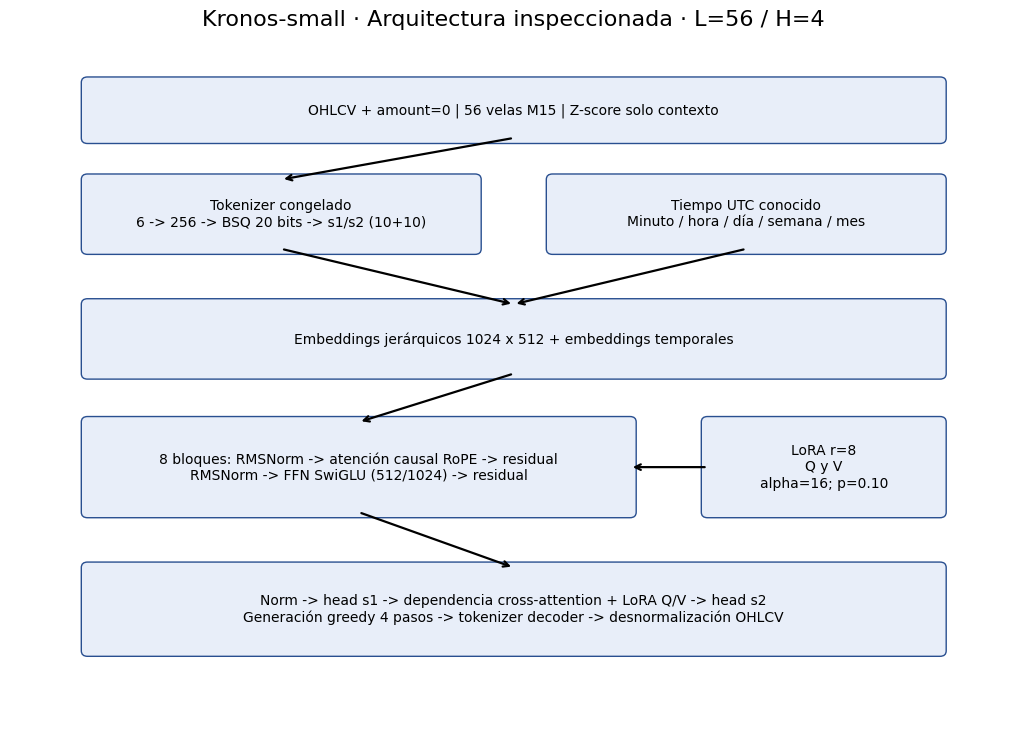

LORA_INTEGRATION_OK | inicial neutro | pesos congelados idénticos


In [ ]:
#@title MISIÓN 04 · 4. LoRA nativo, integridad y Panel A
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
try:
    import plotly.express as px
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
except ImportError:
    import subprocess
    subprocess.run([sys.executable,'-m','pip','install','plotly'],check=True)
    import plotly.express as px
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
import plotly.io as pio
pio.renderers.default='colab'
def m4_plot(fig,name):
    fig.update_layout(template='plotly_white',font_size=13)
    fig.write_html(str(M4_DIR/'graficas'/f'{name}.html'),include_plotlyjs=True)
    fig.show()
def m4_state_hash(module,exclude_lora=False):
    h=hashlib.sha256()
    for k,v in sorted(module.state_dict().items()):
        if exclude_lora and ('.lora_A' in k or '.lora_B' in k): continue
        key=k.replace('.base.','.') if exclude_lora else k
        h.update(key.encode()); h.update(str(tuple(v.shape)).encode()); h.update(v.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()
M4_BASE_HASH=m4_state_hash(m4_model)
M4_TOKEN_HASH=m4_state_hash(m4_tokenizer)
class M4LoRALinear(nn.Module):
    def __init__(self,base,rank=8,alpha=16,dropout=0.1):
        super().__init__(); assert isinstance(base,nn.Linear)
        self.base=base.requires_grad_(False); self.scale=alpha/rank
        self.lora_A=nn.Parameter(torch.empty(rank,base.in_features,device=base.weight.device,dtype=base.weight.dtype))
        self.lora_B=nn.Parameter(torch.zeros(base.out_features,rank,device=base.weight.device,dtype=base.weight.dtype))
        nn.init.kaiming_uniform_(self.lora_A,a=math.sqrt(5))
        self.dropout=nn.Dropout(dropout); self.enabled=True
    def forward(self,x):
        y=self.base(x)
        return y+F.linear(F.linear(self.dropout(x),self.lora_A),self.lora_B)*self.scale if self.enabled else y
# Selección fundada en tipos y atributos inspeccionados; Q y V en autoatención y dependencia.
M4_TARGETS=[]
for name,module in list(m4_model.named_modules()):
    if type(module).__name__ in ['MultiHeadAttentionWithRoPE','MultiHeadCrossAttentionWithRoPE']:
        for projection in ['q_proj','v_proj']:
            layer=getattr(module,projection)
            assert isinstance(layer,nn.Linear) and layer.in_features==512 and layer.out_features==512
            M4_TARGETS.append(name+'.'+projection)
assert len(M4_TARGETS)==18
m4_probe=kp.to_device(next(iter(torch.utils.data.DataLoader(torch.utils.data.Subset(m4_train,[M4_TRAIN_IDS[0]]),batch_size=1))),M4_DEVICE)
m4_model.eval()
with torch.no_grad(): m4_zero_reference=kp.rollout(m4_model,m4_tokenizer,m4_probe,56,4).clone()
kp.seed_all(M4_CFG['seed'])
for name in M4_TARGETS:
    parent,leaf=name.rsplit('.',1); module=m4_model.get_submodule(parent)
    setattr(module,leaf,M4LoRALinear(getattr(module,leaf),M4_CFG['rank'],M4_CFG['alpha'],M4_CFG['dropout']))
m4_model.eval()
with torch.no_grad(): m4_zero=kp.rollout(m4_model,m4_tokenizer,m4_probe,56,4)
assert torch.equal(m4_zero_reference,m4_zero), 'LoRA inicial debe ser exactamente neutro'
assert m4_state_hash(m4_model,True)==M4_BASE_HASH
M4_ADAPTER_INITIAL={n:p.detach().cpu().clone() for n,p in m4_model.named_parameters() if p.requires_grad}
assert all('lora_' in n for n in M4_ADAPTER_INITIAL)
M4_N_BASE=sum(p.numel() for p in m4_model.parameters() if not p.requires_grad)
M4_N_TRAIN=sum(p.numel() for p in m4_model.parameters() if p.requires_grad)
M4_N_TOK=sum(p.numel() for p in m4_tokenizer.parameters())
assert M4_N_TRAIN==18*8*(512+512)
M4_CFG['target_modules']=M4_TARGETS; M4_CFG['trainable_parameters']=M4_N_TRAIN
m4_json(M4_DIR/'auditoria/protocolo.json',M4_CFG)
torch.save(M4_ADAPTER_INITIAL,M4_DIR/'checkpoints/adapter_initial.pt')
M4_COUNTS=pd.DataFrame({'grupo':['Predictor congelado','Tokenizador congelado','LoRA entrenable'],'parametros':[M4_N_BASE,M4_N_TOK,M4_N_TRAIN]})
display(Markdown('## Panel A — Arquitectura y adaptadores\nLoRA: W(x) + (alpha/r) B A Dropout(x). B=0 al inicio; A aleatoria. Se adaptan Q y V en los 8 bloques y la atención de dependencia; embeddings, K, O, FFN, normalizaciones y cabezales permanecen congelados.'))
display(M4_COUNTS); display(pd.DataFrame({'modulo_LoRA':M4_TARGETS,'entrada':512,'salida':512,'rank':8,'parametros_adaptador':8192}))
print(f'Total predictor+LoRA: {M4_N_BASE+M4_N_TRAIN:,}; entrenable: {100*M4_N_TRAIN/(M4_N_BASE+M4_N_TRAIN):.4f}%')
print('Tokenizador real:',len(m4_tokenizer.encoder),'bloques encoder y',len(m4_tokenizer.decoder),'decoder. Config n_enc_layers=4/n_dec_layers=4; implementación oficial construye n-1.')
fig,ax=plt.subplots(figsize=(13,9)); ax.set(xlim=(0,13),ylim=(0,10)); ax.axis('off')
boxes=[(1,8.5,11,0.8,'OHLCV + amount=0 | 56 velas M15 | Z-score solo contexto'),(1,6.9,5,1,'Tokenizer congelado\n6 -> 256 -> BSQ 20 bits -> s1/s2 (10+10)'),(7,6.9,5,1,'Tiempo UTC conocido\nMinuto / hora / día / semana / mes'),(1,5.1,11,1,'Embeddings jerárquicos 1024 x 512 + embeddings temporales'),(1,3.1,7,1.3,'8 bloques: RMSNorm -> atención causal RoPE -> residual\nRMSNorm -> FFN SwiGLU (512/1024) -> residual'),(9,3.1,3,1.3,'LoRA r=8\nQ y V\nalpha=16; p=0.10'),(1,1.1,11,1.2,'Norm -> head s1 -> dependencia cross-attention + LoRA Q/V -> head s2\nGeneración greedy 4 pasos -> tokenizer decoder -> desnormalización OHLCV')]
for x,y,w,h,text in boxes:
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.08',facecolor='#e8eef9',edgecolor='#294f90'))
    ax.text(x+w/2,y+h/2,text,ha='center',va='center',fontsize=10)
for start,end in [((6.5,8.5),(3.5,7.9)),((3.5,6.9),(6.5,6.1)),((9.5,6.9),(6.5,6.1)),((6.5,5.1),(4.5,4.4)),((9,3.75),(8,3.75)),((4.5,3.1),(6.5,2.3))]:
    ax.annotate('',xy=end,xytext=start,arrowprops=dict(arrowstyle='->',lw=1.6))
ax.set_title('Kronos-small · Arquitectura inspeccionada · L=56 / H=4',fontsize=16)
fig.savefig(M4_DIR/'graficas/arquitectura.png',dpi=180,bbox_inches='tight'); plt.show()
m4_plot(px.bar(M4_COUNTS,x='grupo',y='parametros',color='grupo',log_y=True,title='Parámetros congelados y entrenables (escala log)'), 'parametros')
module_counts=pd.DataFrame([{'modulo':n.split('.')[0],'parametros':p.numel(),'estado':'LoRA' if p.requires_grad else 'Congelado'} for n,p in m4_model.named_parameters()]).groupby(['modulo','estado'],as_index=False).parametros.sum()
m4_plot(px.bar(module_counts,x='modulo',y='parametros',color='estado',log_y=True,title='Distribución de parámetros por módulo'),'modulos')
print('LORA_INTEGRATION_OK | inicial neutro | pesos congelados idénticos')

In [ ]:
#@title MISIÓN 04 · 5. Tres pasos LoRA, integridad, checkpoint y Panel B
import threading, resource
# Esta celda siempre restaura el mismo punto inicial; no acumula pasos al repetirla.
for n,p in m4_model.named_parameters():
    if p.requires_grad: p.data.copy_(M4_ADAPTER_INITIAL[n].to(p.device))
kp.seed_all(M4_CFG['seed'])
m4_optimizer=torch.optim.AdamW([p for p in m4_model.parameters() if p.requires_grad],lr=M4_CFG['lr'],weight_decay=M4_CFG['weight_decay'])
M4_HISTORY=[]; M4_GRADS=[]
def m4_sync():
    if M4_DEVICE.type=='cuda': torch.cuda.synchronize()
def m4_adapter_state():
    return {n:p.detach().cpu().clone() for n,p in m4_model.named_parameters() if p.requires_grad}
def m4_fixed_loss():
    m4_model.eval()
    with torch.no_grad(): return float(kp.loss_for_batch(m4_model,m4_tokenizer,m4_probe))
M4_LOSS_BEFORE=m4_fixed_loss()
m4_started=time.perf_counter()
for step,idx in enumerate(M4_TRAIN_IDS,1):
    batch=kp.to_device(next(iter(torch.utils.data.DataLoader(torch.utils.data.Subset(m4_train,[idx]),batch_size=1))),M4_DEVICE)
    m4_model.train(); m4_tokenizer.eval()
    m4_optimizer.zero_grad(set_to_none=True)
    if M4_DEVICE.type=='cuda': torch.cuda.reset_peak_memory_stats()
    stop=threading.Event(); rss_samples=[psutil.Process().memory_info().rss]
    def sample_rss():
        while not stop.wait(0.01): rss_samples.append(psutil.Process().memory_info().rss)
    monitor=threading.Thread(target=sample_rss,daemon=True); monitor.start()
    m4_sync(); t0=time.perf_counter()
    try:
        loss=kp.loss_for_batch(m4_model,m4_tokenizer,batch)
        assert torch.isfinite(loss)
        loss.backward()
        for name,p in m4_model.named_parameters():
            if p.requires_grad:
                assert p.grad is not None and torch.isfinite(p.grad).all(), name
                M4_GRADS.append({'step':step,'parameter':name,'grad_norm':float(p.grad.norm())})
            else: assert p.grad is None, 'Peso base recibió gradiente: '+name
        assert all(p.grad is None for p in m4_tokenizer.parameters())
        grad=torch.nn.utils.clip_grad_norm_([p for p in m4_model.parameters() if p.requires_grad],M4_CFG['grad_clip'])
        assert torch.isfinite(grad) and float(grad)>0
        m4_optimizer.step(); m4_sync()
        elapsed=time.perf_counter()-t0
        assert all(torch.isfinite(p).all() for p in m4_model.parameters() if p.requires_grad)
    finally:
        stop.set(); monitor.join(); rss_samples.append(psutil.Process().memory_info().rss)
    row={'step':step,'train_id':idx,'decision_utc':str(train_ix.iloc[idx].decision_utc),'loss':float(loss.detach()),'lr':m4_optimizer.param_groups[0]['lr'],'gradient_norm_pre_clip':float(grad),'seconds':elapsed,'rss_peak_sampled_GiB':max(rss_samples)/2**30,'gpu_peak_allocated_GiB':torch.cuda.max_memory_allocated()/2**30 if M4_DEVICE.type=='cuda' else None,'gpu_peak_reserved_GiB':torch.cuda.max_memory_reserved()/2**30 if M4_DEVICE.type=='cuda' else None}
    M4_HISTORY.append(row); print(json.dumps(row),flush=True)
    m4_json(M4_DIR/'metricas/pasos.json',M4_HISTORY)
M4_TRAIN_SECONDS=time.perf_counter()-m4_started
m4_model.eval()
M4_LOSS_AFTER=m4_fixed_loss()
M4_FROZEN_OK=m4_state_hash(m4_model,True)==M4_BASE_HASH
M4_TOKEN_OK=m4_state_hash(m4_tokenizer)==M4_TOKEN_HASH
assert M4_FROZEN_OK and M4_TOKEN_OK
M4_DELTAS=pd.DataFrame([{'parameter':n,'delta_L2':float((p.detach().cpu()-M4_ADAPTER_INITIAL[n]).norm()),'norm_initial':float(M4_ADAPTER_INITIAL[n].norm()),'norm_final':float(p.detach().norm())} for n,p in m4_model.named_parameters() if p.requires_grad])
assert (M4_DELTAS.delta_L2>0).all()
M4_CHECKS_LORA=kp.contract_tests(m4_model,m4_tokenizer,m4_train,M4_DEVICE)
m4_model.eval()
with torch.no_grad(): expected_reload=kp.rollout(m4_model,m4_tokenizer,m4_probe,56,4).clone()
M4_CHECKPOINT=M4_DIR/'checkpoints/lora_step003.pt'
checkpoint={'adapter':m4_adapter_state(),'optimizer':m4_optimizer.state_dict(),'step':3,'config':M4_CFG,'base_hash':M4_BASE_HASH,'tokenizer_hash':M4_TOKEN_HASH,'commit':M4_COMMIT,'revisions':kp.REVISIONS,'train_ids':M4_TRAIN_IDS,'history':M4_HISTORY,'python_rng':random.getstate(),'numpy_rng':np.random.get_state(),'torch_rng':torch.get_rng_state(),'cuda_rng':torch.cuda.get_rng_state_all() if M4_DEVICE.type=='cuda' else None}
torch.save(checkpoint,M4_CHECKPOINT)
reloaded=torch.load(M4_CHECKPOINT,map_location='cpu',weights_only=False)
for name,p in m4_model.named_parameters():
    if p.requires_grad: p.data.zero_()
for name,p in m4_model.named_parameters():
    if p.requires_grad: p.data.copy_(reloaded['adapter'][name].to(p.device))
with torch.no_grad(): actual_reload=kp.rollout(m4_model,m4_tokenizer,m4_probe,56,4)
M4_RELOAD_OK=torch.equal(expected_reload,actual_reload)
assert M4_RELOAD_OK
M4_INTEGRITY={'frozen_all_tensors_identical':M4_FROZEN_OK,'tokenizer_all_tensors_identical':M4_TOKEN_OK,'all_adapters_changed':bool((M4_DELTAS.delta_L2>0).all()),'reload_prediction_identical':M4_RELOAD_OK,'loss_same_probe_eval_before':M4_LOSS_BEFORE,'loss_same_probe_eval_after':M4_LOSS_AFTER,'training_seconds':M4_TRAIN_SECONDS,'checkpoint_sha256':m4_sha(M4_CHECKPOINT),'causal_tests':M4_CHECKS_LORA}
m4_json(M4_DIR/'auditoria/integridad_piloto.json',M4_INTEGRITY)
pd.DataFrame(M4_HISTORY).to_csv(M4_DIR/'metricas/pasos.csv',index=False)
pd.DataFrame(M4_GRADS).to_csv(M4_DIR/'metricas/gradientes_por_parametro.csv',index=False)
M4_DELTAS.to_csv(M4_DIR/'metricas/cambios_adaptadores.csv',index=False)
display(Markdown('## Panel B — Piloto funcional de tres pasos\nCada paso usa una ventana de train distinta. La curva de tres pérdidas no mide convergencia ni capacidad predictiva. Gradiente A=0 en el primer paso es esperado porque B empieza en cero.'))
display(pd.DataFrame(M4_HISTORY)); display(M4_DELTAS)
fig=make_subplots(rows=3,cols=2,subplot_titles=['Pérdida por paso (ventanas distintas)','Learning rate','Norma gradiente antes de clipping','RAM del proceso: pico muestreado cada 10 ms','Tiempo por paso (segundos)','Memoria GPU'])
for (col,label),row,column in [(('loss','Pérdida'),1,1),(('lr','LR'),1,2),(('gradient_norm_pre_clip','Gradiente'),2,1),(('rss_peak_sampled_GiB','RAM GiB'),2,2),(('seconds','Segundos'),3,1)]:
    fig.add_trace(go.Scatter(x=[r['step'] for r in M4_HISTORY],y=[r[col] for r in M4_HISTORY],mode='lines+markers',name=label),row=row,col=column)
if M4_DEVICE.type=='cuda':
    fig.add_trace(go.Scatter(x=[r['step'] for r in M4_HISTORY],y=[r['gpu_peak_allocated_GiB'] for r in M4_HISTORY],name='GPU GiB'),row=3,col=2)
else: fig.add_annotation(text='GPU no disponible: N/A (CPU)',xref='x6 domain',yref='y6 domain',x=.5,y=.5,showarrow=False)
fig.update_layout(height=850,title='Kronos-small LoRA | Tres optimizaciones reales')
m4_plot(fig,'panel_entrenamiento')
print('PILOTO_LORA_OK:',json.dumps(M4_INTEGRITY,indent=2))

{"step": 1, "train_id": 6543, "decision_utc": "2017-08-30 14:30:00+00:00", "loss": 3.707210063934326, "lr": 0.0001, "gradient_norm_pre_clip": 0.15160879492759705, "seconds": 1.0881421150006645, "rss_peak_sampled_GiB": 1.4411506652832031, "gpu_peak_allocated_GiB": null, "gpu_peak_reserved_GiB": null}
{"step": 2, "train_id": 7949, "decision_utc": "2019-04-16 13:30:00+00:00", "loss": 4.1416754722595215, "lr": 0.0001, "gradient_norm_pre_clip": 0.255513459444046, "seconds": 0.23225621600067825, "rss_peak_sampled_GiB": 1.4411506652832031, "gpu_peak_allocated_GiB": null, "gpu_peak_reserved_GiB": null}
{"step": 3, "train_id": 4984, "decision_utc": "2016-02-16 14:30:00+00:00", "loss": 5.363853454589844, "lr": 0.0001, "gradient_norm_pre_clip": 0.17511478066444397, "seconds": 0.22946355800013407, "rss_peak_sampled_GiB": 1.4411506652832031, "gpu_peak_allocated_GiB": null, "gpu_peak_reserved_GiB": null}


## Panel B — Piloto funcional de tres pasos
Cada paso usa una ventana de train distinta. La curva de tres pérdidas no mide convergencia ni capacidad predictiva. Gradiente A=0 en el primer paso es esperado porque B empieza en cero.

,step,train_id,decision_utc,loss,lr,gradient_norm_pre_clip,seconds,rss_peak_sampled_GiB,gpu_peak_allocated_GiB,gpu_peak_reserved_GiB
0,1,6543,2017-08-30 14:30:00+00:00,3.707210,0.0001,0.151609,1.088142,1.441151,None,None
1,2,7949,2019-04-16 13:30:00+00:00,4.141675,0.0001,0.255513,0.232256,1.441151,None,None
2,3,4984,2016-02-16 14:30:00+00:00,5.363853,0.0001,0.175115,0.229464,1.441151,None,None


,parameter,delta_L2,norm_initial,norm_final
0,transformer.0.self_attn.q_proj.lora_A,0.006916,1.640254,1.640166
1,transformer.0.self_attn.q_proj.lora_B,0.011820,0.000000,0.011820
2,transformer.0.self_attn.v_proj.lora_A,0.006758,1.656128,1.656058
3,transformer.0.self_attn.v_proj.lora_B,0.011605,0.000000,0.011605
4,transformer.1.self_attn.q_proj.lora_A,0.007007,1.631458,1.631547
5,transformer.1.self_attn.q_proj.lora_B,0.012074,0.000000,0.012074
6,transformer.1.self_attn.v_proj.lora_A,0.007182,1.614001,1.614115
7,transformer.1.self_attn.v_proj.lora_B,0.012263,0.000000,0.012263
8,transformer.2.self_attn.q_proj.lora_A,0.007661,1.636459,1.636526
9,transformer.2.self_attn.q_proj.lora_B,0.012675,0.000000,0.012675


PILOTO_LORA_OK: {
  "frozen_all_tensors_identical": true,
  "tokenizer_all_tensors_identical": true,
  "all_adapters_changed": true,
  "reload_prediction_identical": true,
  "loss_same_probe_eval_before": 3.8602333068847656,
  "loss_same_probe_eval_after": 3.8574347496032715,
  "training_seconds": 1.6305914420008776,
  "checkpoint_sha256": "dfc7d40f58e69a900c4972a645af6978820f8b1a820608dbb3331cb770376dfd",
  "causal_tests": {
    "loss_active_indices": [
      55,
      56,
      57,
      58
    ],
    "normalization_future_invariant": true,
    "tokenizer_future_and_prefix_invariant": true,
    "predictor_causal_eval": [
      0.0,
      0.0
    ],
    "predictor_causal_train": [
      0.0,
      0.0
    ],
    "rollout_future_invariant": true,
    "tokenizer_frozen": true
  }
}


In [ ]:
#@title MISIÓN 04 · 6. Evaluación de validación y paneles C/D
assert M4_FROZEN_OK and M4_TOKEN_OK and M4_RELOAD_OK
m4_predictions=[]; M4_EVAL_TIMES={}
m4_model.eval(); m4_tokenizer.eval()
for label,enabled in [('Kronos base (causal greedy)',False),('Kronos LoRA (3 pasos)',True)]:
    for module in m4_model.modules():
        if isinstance(module,M4LoRALinear): module.enabled=enabled
    m4_sync(); t0=time.perf_counter()
    with torch.no_grad():
        for i in range(len(m4_eval)):
            batch=kp.to_device(next(iter(torch.utils.data.DataLoader(torch.utils.data.Subset(m4_eval,[i]),batch_size=1))),M4_DEVICE)
            pred=kp.rollout(m4_model,m4_tokenizer,batch,56,4)[0,:,3].cpu().numpy()
            truth=batch['truth'][0,:,3].cpu().numpy(); last=float(batch['last_close'][0])
            assert np.isfinite(pred).all()
            meta=m4_eval_ix.iloc[i]
            for h in range(4):
                m4_predictions.append({'model':label,'window':i,'horizon':h+1,'decision_utc':meta.decision_utc,'ny_date':meta.ny_date,'ny_hour':meta.ny_hour,'year':int(meta.year),'target_close_utc':meta.decision_utc+pd.Timedelta(minutes=15*(h+1)),'last_close':last,'truth':float(truth[h]),'prediction':float(pred[h])})
    m4_sync(); M4_EVAL_TIMES[label]=time.perf_counter()-t0
    print(label,':',len(m4_eval),'ventanas completadas',flush=True)
for module in m4_model.modules():
    if isinstance(module,M4LoRALinear): module.enabled=True
m4_pred=pd.DataFrame(m4_predictions)
persistence=m4_pred[m4_pred.model=='Kronos base (causal greedy)'].copy()
persistence['model']='Persistencia'; persistence['prediction']=persistence.last_close
m4_pred=pd.concat([m4_pred,persistence],ignore_index=True)
m4_pred['error']=m4_pred.prediction-m4_pred.truth
m4_pred['abs_error']=m4_pred.error.abs()
m4_pred['true_direction']=np.sign(m4_pred.truth-m4_pred.last_close)
m4_pred['pred_direction']=np.sign(m4_pred.prediction-m4_pred.last_close)
assert m4_pred.groupby('model').size().eq(96).all()
assert not m4_pred[['model','window','horizon']].duplicated().any()
for _,g in m4_pred.groupby(['window','horizon']): assert g.truth.nunique()==1 and g.last_close.nunique()==1
m4_pred.to_parquet(M4_DIR/'metricas/predicciones.parquet',index=False)
m4_pred.to_csv(M4_DIR/'metricas/predicciones.csv',index=False)
def m4_metrics(g):
    moving=g.true_direction.ne(0); issued=g.pred_direction.ne(0)
    denom=moving & issued
    return pd.Series({'MAE':g.abs_error.mean(),'RMSE':np.sqrt(np.mean(g.error**2)),'direction_accuracy_nonflat_pct':100*(g.loc[moving,'true_direction']==g.loc[moving,'pred_direction']).mean(),'direction_coverage_pct':100*issued.mean(),'direction_accuracy_issued_pct':100*(g.loc[denom,'true_direction']==g.loc[denom,'pred_direction']).mean() if denom.any() else np.nan,'n_predictions':len(g),'n_windows':g.window.nunique(),'n_days':g.ny_date.nunique(),'n_nonflat':int(moving.sum())})
M4_METRICS=m4_pred.groupby('model').apply(m4_metrics,include_groups=False).reset_index()
M4_BY_H=m4_pred.groupby(['model','horizon']).apply(m4_metrics,include_groups=False).reset_index()
M4_BY_NY=m4_pred.groupby(['model','ny_hour']).apply(m4_metrics,include_groups=False).reset_index()
M4_BY_YEAR=m4_pred.groupby(['model','year']).apply(m4_metrics,include_groups=False).reset_index()
for name,table in [('comparacion',M4_METRICS),('por_horizonte',M4_BY_H),('por_horario_NY',M4_BY_NY),('por_ano',M4_BY_YEAR)]: table.to_csv(M4_DIR/'metricas'/f'{name}.csv',index=False)
m4_json(M4_DIR/'metricas/tiempos_evaluacion.json',M4_EVAL_TIMES)
assert m4_state_hash(m4_model,True)==M4_BASE_HASH and m4_state_hash(m4_tokenizer)==M4_TOKEN_HASH
for item in M4_MANIFEST: assert m4_sha(M4_SOURCE/item['file'])==item['sha256']
display(Markdown('## Panel C — Predicciones reales sobre validación\nMismas 24 ventanas, 96 cierres por modelo; selección anterior al piloto. Cada objetivo queda fuera de train, pero esta muestra pequeña no es un test final. Preentrenamiento externo: solapamiento desconocido.'))
fig=go.Figure(); buttons=[]
models=['Kronos base (causal greedy)','Kronos LoRA (3 pasos)','Persistencia']; colors=['#3465a4','#e67e22','#888888']
for i in range(len(m4_eval)):
    meta=m4_eval_ix.iloc[i]; s=int(meta.start_row)
    close_times=(m4_df.timestamp_utc.iloc[s:s+60]+pd.Timedelta(minutes=15)).dt.tz_convert('America/New_York').dt.tz_localize(None)
    fig.add_trace(go.Scatter(x=close_times,y=m4_df.close.iloc[s:s+60],name='Cierre real (56+4)',line=dict(color='#202020'),visible=i==0))
    for model,color in zip(models,colors):
        g=m4_pred[(m4_pred.window==i)&(m4_pred.model==model)].sort_values('horizon')
        fig.add_trace(go.Scatter(x=close_times.iloc[55:],y=np.r_[g.last_close.iloc[0],g.prediction],name=model,mode='lines+markers',line=dict(color=color),visible=i==0))
    decision=meta.decision_utc.tz_convert('America/New_York').tz_localize(None)
    end=(meta.decision_utc+pd.Timedelta(hours=1)).tz_convert('America/New_York').tz_localize(None)
    shapes=[dict(type='rect',xref='x',yref='paper',x0=str(decision),x1=str(end),y0=0,y1=1,fillcolor='rgba(70,120,220,0.12)',line_width=0),dict(type='line',xref='x',yref='paper',x0=str(decision),x1=str(decision),y0=0,y1=1,line=dict(dash='dash',color='#3465a4'))]
    buttons.append(dict(label=f'{i:02d} | {meta.ny_date} {meta.ny_hour} NY',method='update',args=[{'visible':[j//4==i for j in range(len(m4_eval)*4)]},{'title':f'XAUUSD M15 | {meta.ny_date} {meta.ny_hour} NY | sombra = horizonte futuro','shapes':shapes}]))
fig.update_layout(height=570,title='XAUUSD M15 | Contexto 56 + horizonte 4 | horas Nueva York',xaxis_title='Hora del cierre (America/New_York)',yaxis_title='Precio XAUUSD, unidades del dataset BID',updatemenus=[dict(buttons=buttons,x=0,y=1.18)],shapes=buttons[0]['args'][1]['shapes'],legend=dict(orientation='h',y=-.25))
fig.update_xaxes(rangeslider_visible=True)
m4_plot(fig,'predicciones_24_ventanas')
m4_plot(px.line(M4_BY_H,x='horizon',y='MAE',color='model',markers=True,title='MAE por horizonte: 24 observaciones por punto'),'error_horizonte')
m4_plot(px.histogram(m4_pred,x='error',color='model',barmode='overlay',opacity=.55,nbins=25,title='Distribución de errores (predicción − cierre real)'), 'distribucion_errores')
display(Markdown('## Panel D — Comparación justa\nBase = pesos originales sin LoRA bajo el mismo rollout causal greedy. No es una comparación contra el muestreador oficial KronosPredictor. Dirección = signo(predicción − último cierre); se excluyen verdades planas. Persistencia emite dirección 0: cobertura direccional 0%, acierto condicionado N/A.'))
display(M4_METRICS); display(M4_BY_NY); display(M4_BY_YEAR)
m4_plot(px.bar(M4_METRICS.melt(id_vars='model',value_vars=['MAE','RMSE'],var_name='metrica',value_name='error'),x='model',y='error',color='metrica',barmode='group',title='MAE y RMSE sobre las mismas observaciones'),'comparacion_mae_rmse')
m4_plot(px.bar(M4_METRICS,x='model',y='direction_accuracy_nonflat_pct',color='model',title='Precisión direccional: ceros cuentan como ausencia de acierto'),'comparacion_direccion')
m4_plot(px.bar(M4_BY_NY,x='ny_hour',y='MAE',color='model',barmode='group',title='MAE por ancla de Nueva York (6 ventanas por horario)'),'comparacion_horario_NY')
M4_EVAL_OK=True
print('EVALUACION_VALIDA_FUNCIONAL:',M4_METRICS.to_json(orient='records'))
print('TIEMPOS:',M4_EVAL_TIMES)
print('FUENTES_ORIGINALES_INTACTAS=True | TEST_2023_2024_NO_LEIDO=True')

Kronos base (causal greedy) : 24 ventanas completadas
Kronos LoRA (3 pasos) : 24 ventanas completadas


## Panel C — Predicciones reales sobre validación
Mismas 24 ventanas, 96 cierres por modelo; selección anterior al piloto. Cada objetivo queda fuera de train, pero esta muestra pequeña no es un test final. Preentrenamiento externo: solapamiento desconocido.

## Panel D — Comparación justa
Base = pesos originales sin LoRA bajo el mismo rollout causal greedy. No es una comparación contra el muestreador oficial KronosPredictor. Dirección = signo(predicción − último cierre); se excluyen verdades planas. Persistencia emite dirección 0: cobertura direccional 0%, acierto condicionado N/A.

,model,MAE,RMSE,direction_accuracy_nonflat_pct,direction_coverage_pct,direction_accuracy_issued_pct,n_predictions,n_windows,n_days,n_nonflat
0,Kronos LoRA (3 pasos),3.808634,6.24950,45.833333,100.0,45.833333,96.0,24.0,24.0,96.0
1,Kronos base (causal greedy),3.808634,6.24950,45.833333,100.0,45.833333,96.0,24.0,24.0,96.0
2,Persistencia,3.560291,6.20043,0.000000,0.0,NaN,96.0,24.0,24.0,96.0


,model,ny_hour,MAE,RMSE,direction_accuracy_nonflat_pct,direction_coverage_pct,direction_accuracy_issued_pct,n_predictions,n_windows,n_days,n_nonflat
0,Kronos LoRA (3 pasos),08:30,7.038177,10.296081,62.500000,100.0,62.500000,24.0,6.0,6.0,24.0
1,Kronos LoRA (3 pasos),09:30,2.842173,3.743832,50.000000,100.0,50.000000,24.0,6.0,6.0,24.0
2,Kronos LoRA (3 pasos),10:30,3.013936,5.169051,29.166667,100.0,29.166667,24.0,6.0,6.0,24.0
3,Kronos LoRA (3 pasos),11:30,2.340251,3.079018,41.666667,100.0,41.666667,24.0,6.0,6.0,24.0
4,Kronos base (causal greedy),08:30,7.038177,10.296081,62.500000,100.0,62.500000,24.0,6.0,6.0,24.0
5,Kronos base (causal greedy),09:30,2.842173,3.743832,50.000000,100.0,50.000000,24.0,6.0,6.0,24.0
6,Kronos base (causal greedy),10:30,3.013936,5.169051,29.166667,100.0,29.166667,24.0,6.0,6.0,24.0
7,Kronos base (causal greedy),11:30,2.340251,3.079018,41.666667,100.0,41.666667,24.0,6.0,6.0,24.0
8,Persistencia,08:30,6.892746,10.700657,0.000000,0.0,NaN,24.0,6.0,6.0,24.0
9,Persistencia,09:30,2.613475,3.225067,0.000000,0.0,NaN,24.0,6.0,6.0,24.0


,model,year,MAE,RMSE,direction_accuracy_nonflat_pct,direction_coverage_pct,direction_accuracy_issued_pct,n_predictions,n_windows,n_days,n_nonflat
0,Kronos LoRA (3 pasos),2020,5.634789,8.764208,31.25,100.0,31.25,32.0,8.0,8.0,32.0
1,Kronos LoRA (3 pasos),2021,2.154720,2.938140,50.00,100.0,50.00,32.0,8.0,8.0,32.0
2,Kronos LoRA (3 pasos),2022,3.636395,5.632472,56.25,100.0,56.25,32.0,8.0,8.0,32.0
3,Kronos base (causal greedy),2020,5.634789,8.764208,31.25,100.0,31.25,32.0,8.0,8.0,32.0
4,Kronos base (causal greedy),2021,2.154720,2.938140,50.00,100.0,50.00,32.0,8.0,8.0,32.0
5,Kronos base (causal greedy),2022,3.636395,5.632472,56.25,100.0,56.25,32.0,8.0,8.0,32.0
6,Persistencia,2020,5.313976,8.849651,0.00,0.0,NaN,32.0,8.0,8.0,32.0
7,Persistencia,2021,1.943428,2.403988,0.00,0.0,NaN,32.0,8.0,8.0,32.0
8,Persistencia,2022,3.423470,5.589322,0.00,0.0,NaN,32.0,8.0,8.0,32.0


EVALUACION_VALIDA_FUNCIONAL: [{"model":"Kronos LoRA (3 pasos)","MAE":3.8086344401,"RMSE":6.2494999777,"direction_accuracy_nonflat_pct":45.8333333333,"direction_coverage_pct":100.0,"direction_accuracy_issued_pct":45.8333333333,"n_predictions":96.0,"n_windows":24.0,"n_days":24.0,"n_nonflat":96.0},{"model":"Kronos base (causal greedy)","MAE":3.8086344401,"RMSE":6.2494999777,"direction_accuracy_nonflat_pct":45.8333333333,"direction_coverage_pct":100.0,"direction_accuracy_issued_pct":45.8333333333,"n_predictions":96.0,"n_windows":24.0,"n_days":24.0,"n_nonflat":96.0},{"model":"Persistencia","MAE":3.5602912903,"RMSE":6.2004301255,"direction_accuracy_nonflat_pct":0.0,"direction_coverage_pct":0.0,"direction_accuracy_issued_pct":null,"n_predictions":96.0,"n_windows":24.0,"n_days":24.0,"n_nonflat":96.0}]
TIEMPOS: {'Kronos base (causal greedy)': 13.602291448001779, 'Kronos LoRA (3 pasos)': 12.396199586000876}
FUENTES_ORIGINALES_INTACTAS=True | TEST_2023_2024_NO_LEIDO=True


## Diagnóstico computacional final

,device,python,torch,cpu_threads,ram_total_GiB,ram_available_GiB,process_RSS_GiB,gpu,gpu_total_GiB,pilot_seconds,step_seconds_mean,process_RSS_peak_sampled_GiB,process_lifetime_max_RSS_GiB,evaluation_seconds,static_parameters_plus_lora_grads_adam_MiB,static_budget_excludes
0,cpu,3.13.18,2.14.1+cpu,2,12.671406,9.572063,1.283539,None,None,1.630591,0.516621,1.441151,1.7486,{'Kronos base (causal greedy)': 13.60229144800...,111.729591,"activaciones, temporales, CUDA context, RAM de..."


,hardware,memoria_referencia,estado,uso
0,CPU actual,12.67 GiB RAM,"MEDIDO: viable, batch 1 / FP32",Piloto y evaluación acotada; no se probó una m...
1,T4,16 GB GPU,"CANDIDATO, no medido","Primera GPU a probar; batch 1, luego 2/4/8 si ..."
2,L4,24 GB GPU,"CANDIDATO, no medido",Escalar si el tiempo medido de T4 excede el pr...
3,A100,40/80 GB GPU según variante,No necesario para este piloto,Justificar con perfiles de lotes/contextos may...
4,H100,80 GB GPU (variante H100 de referencia),No necesario para este piloto,Solo si experimentos amplios justifican rendim...


GPU: no se asignó ninguna; consumo GPU=N/A. No se afirma haber medido T4/L4/A100/H100.
Referencias de capacidades: https://docs.cloud.google.com/compute/docs/gpus ; https://www.nvidia.com/es-la/data-center/tesla-t4/ ; https://www.nvidia.com/es-es/data-center/l4/


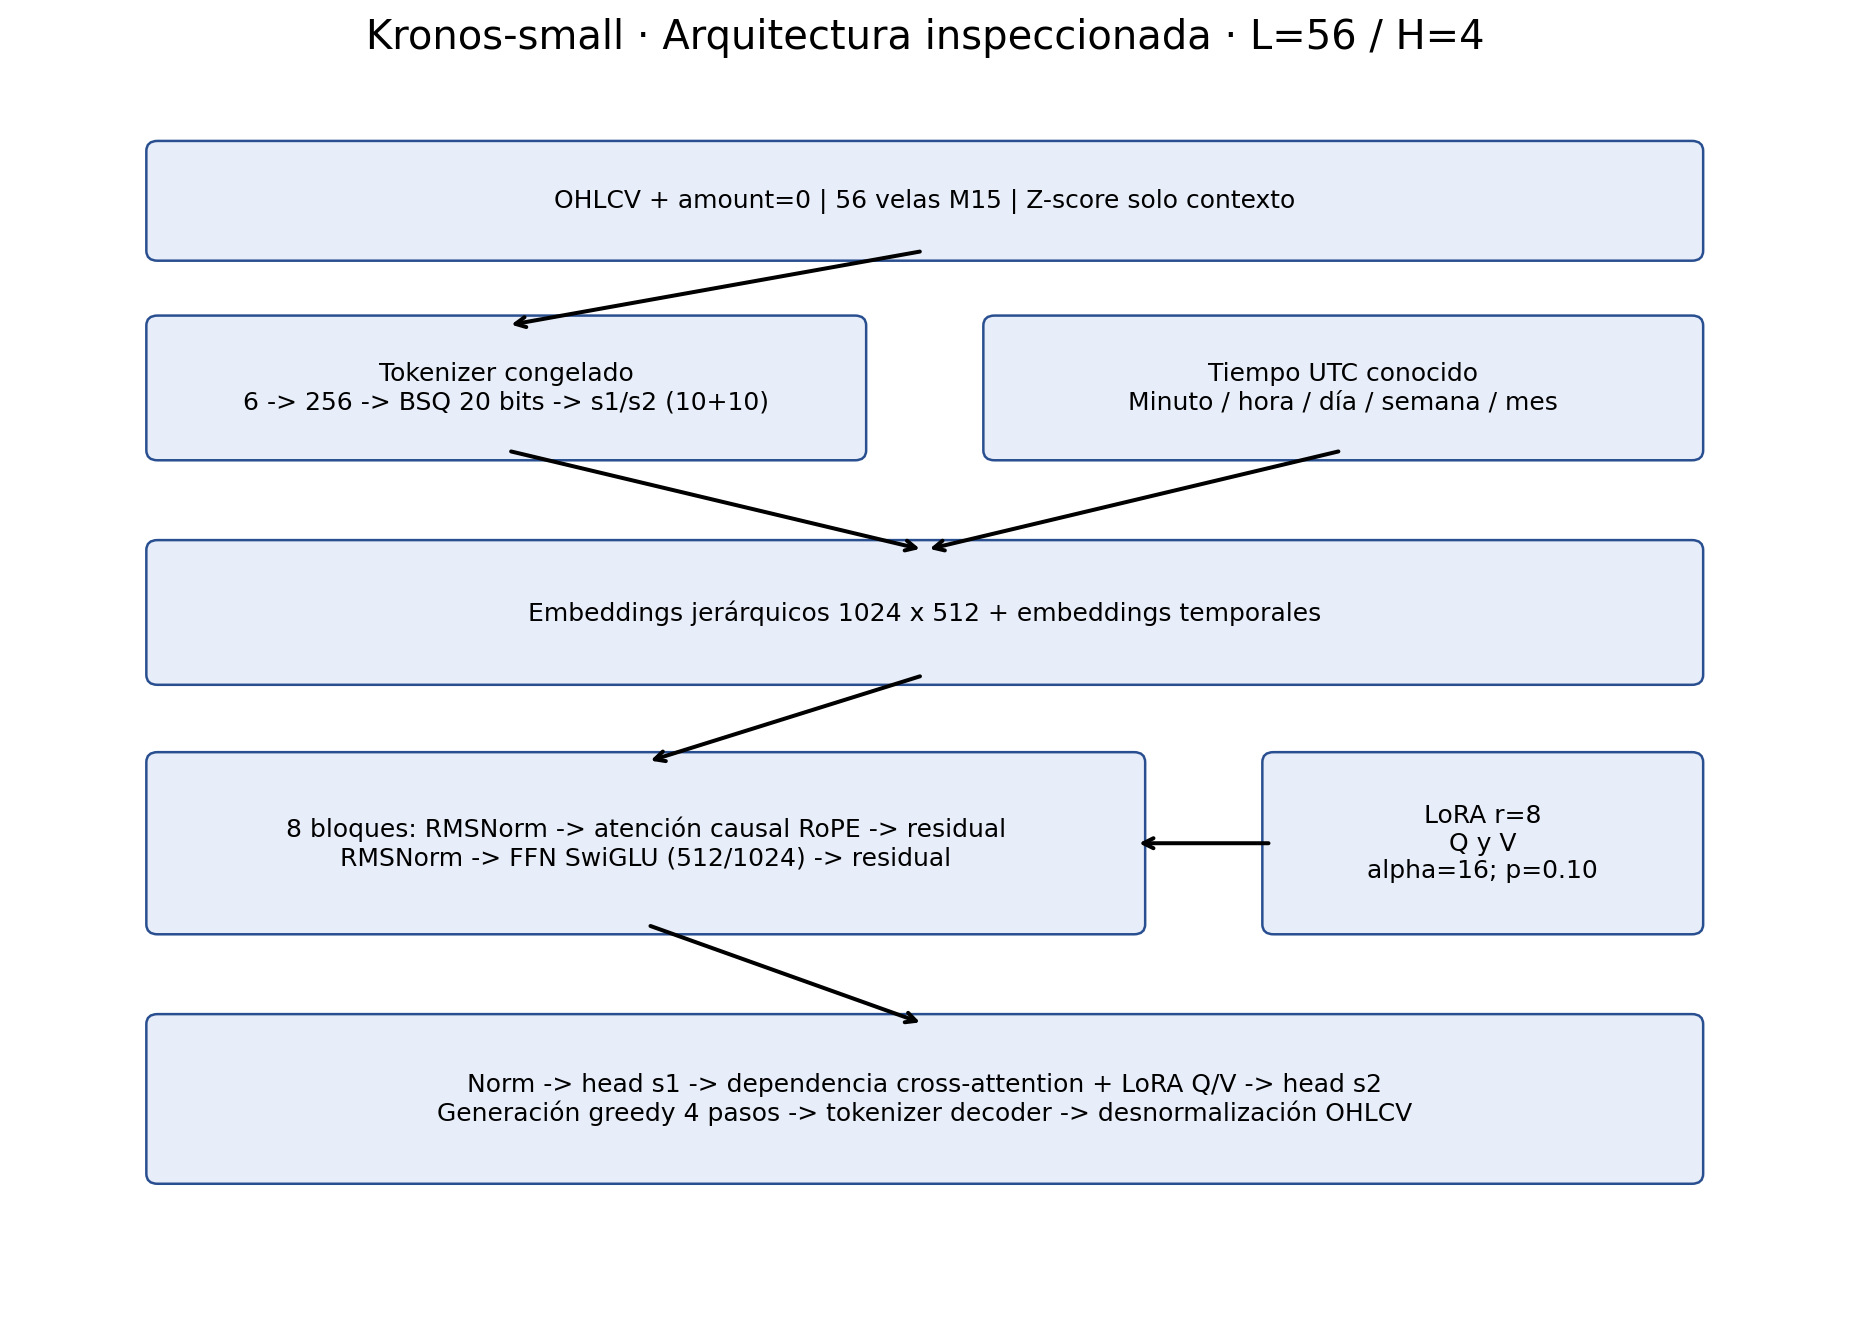

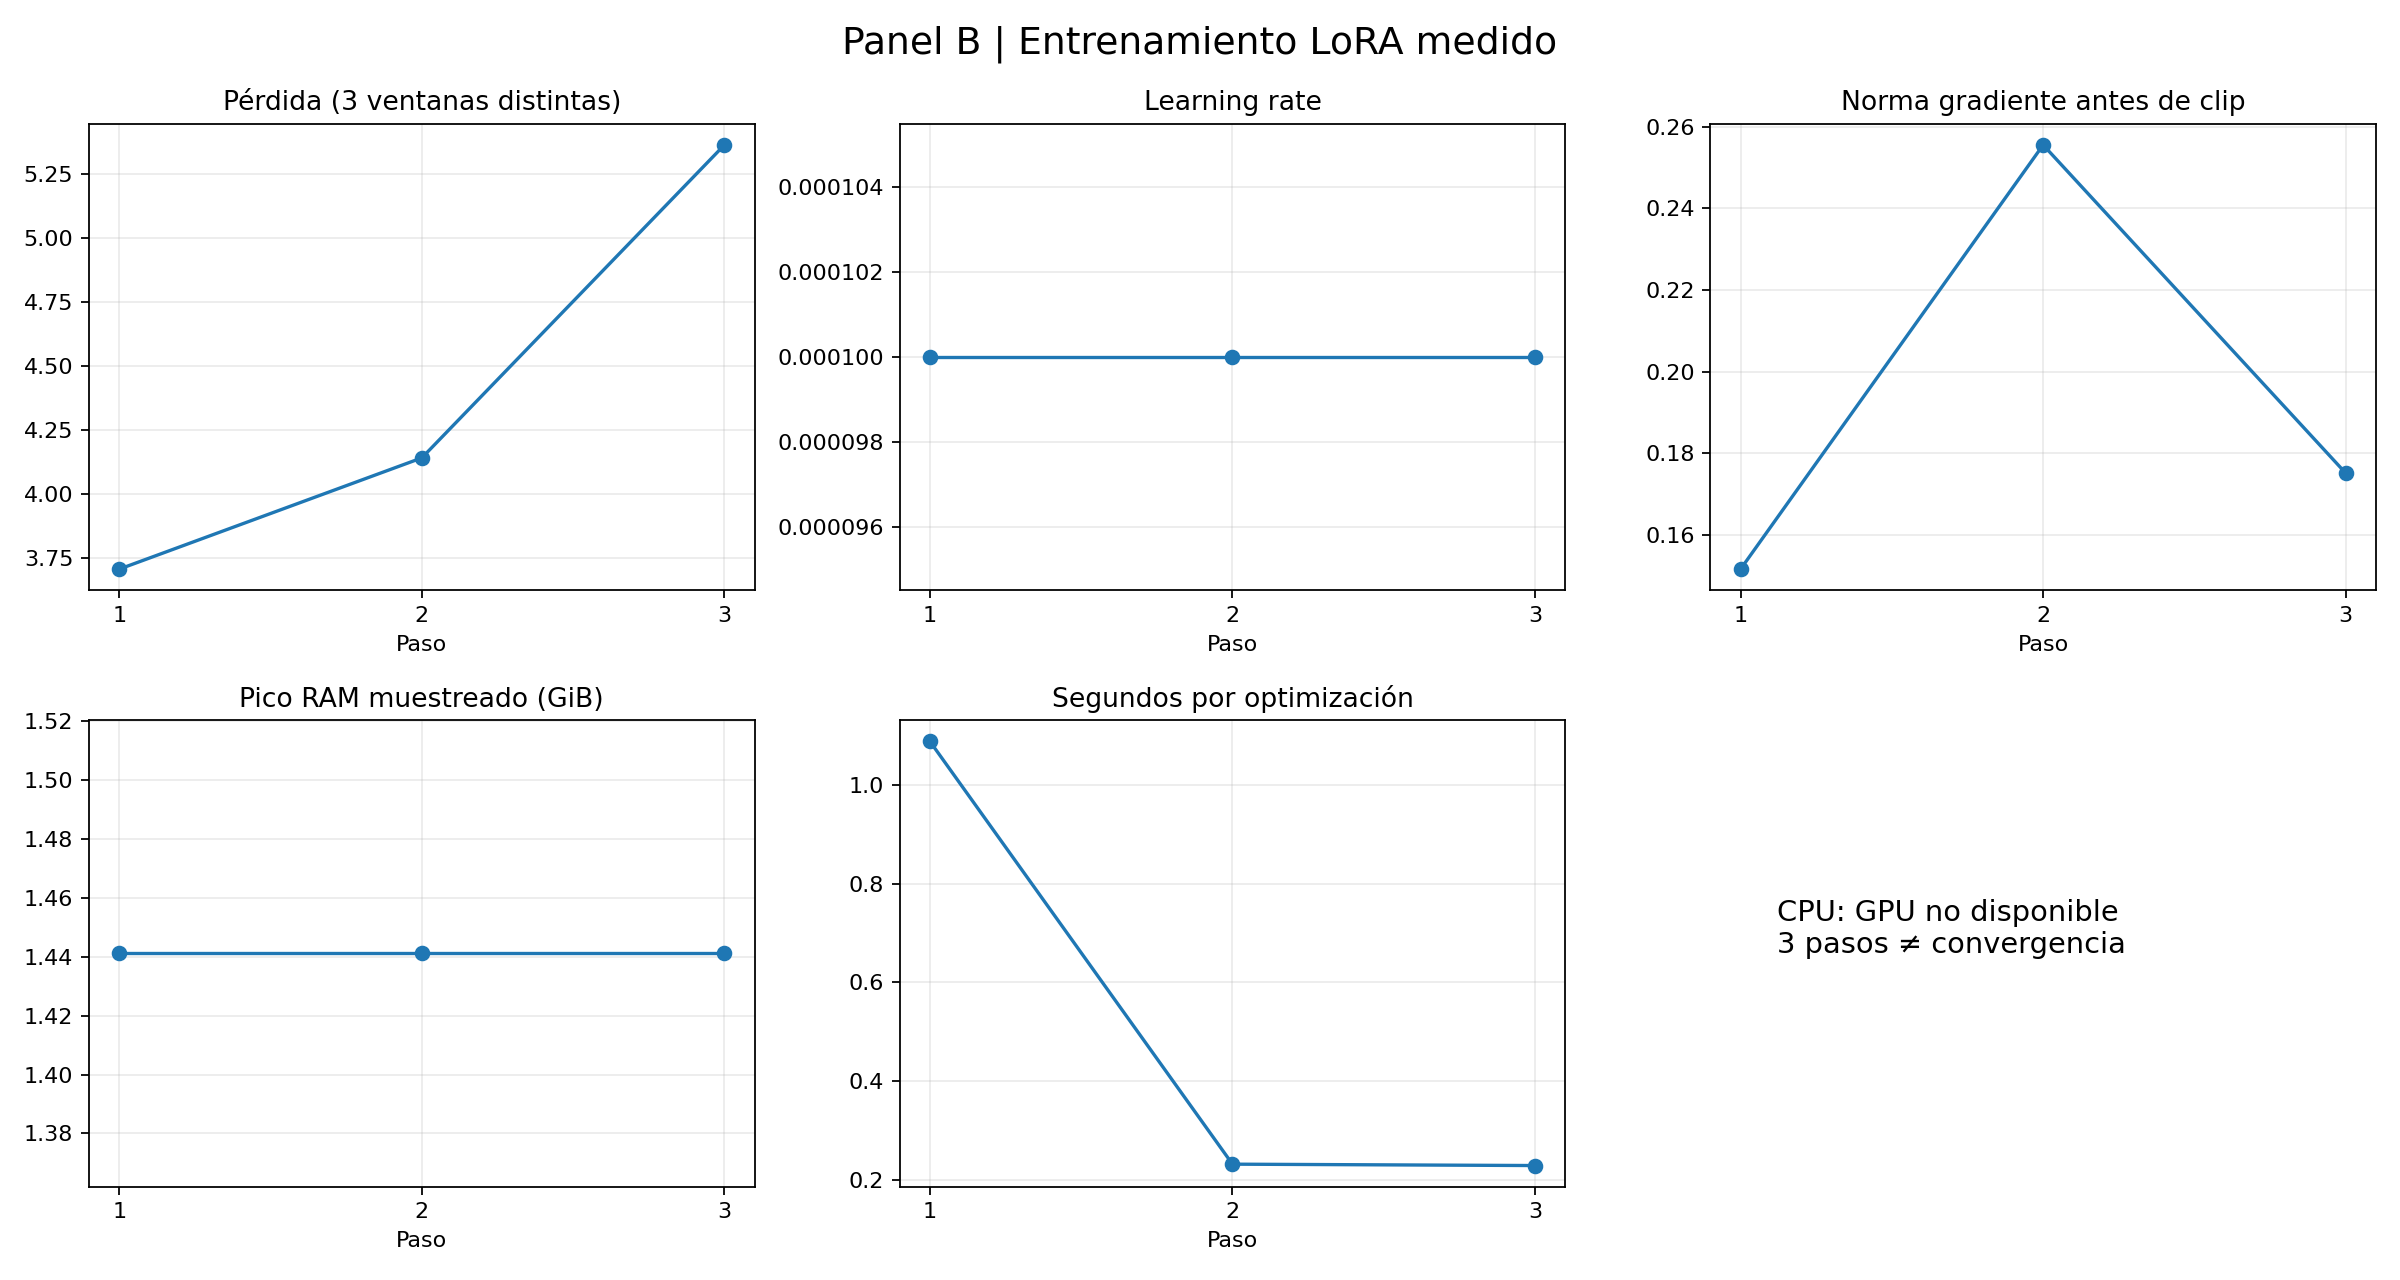

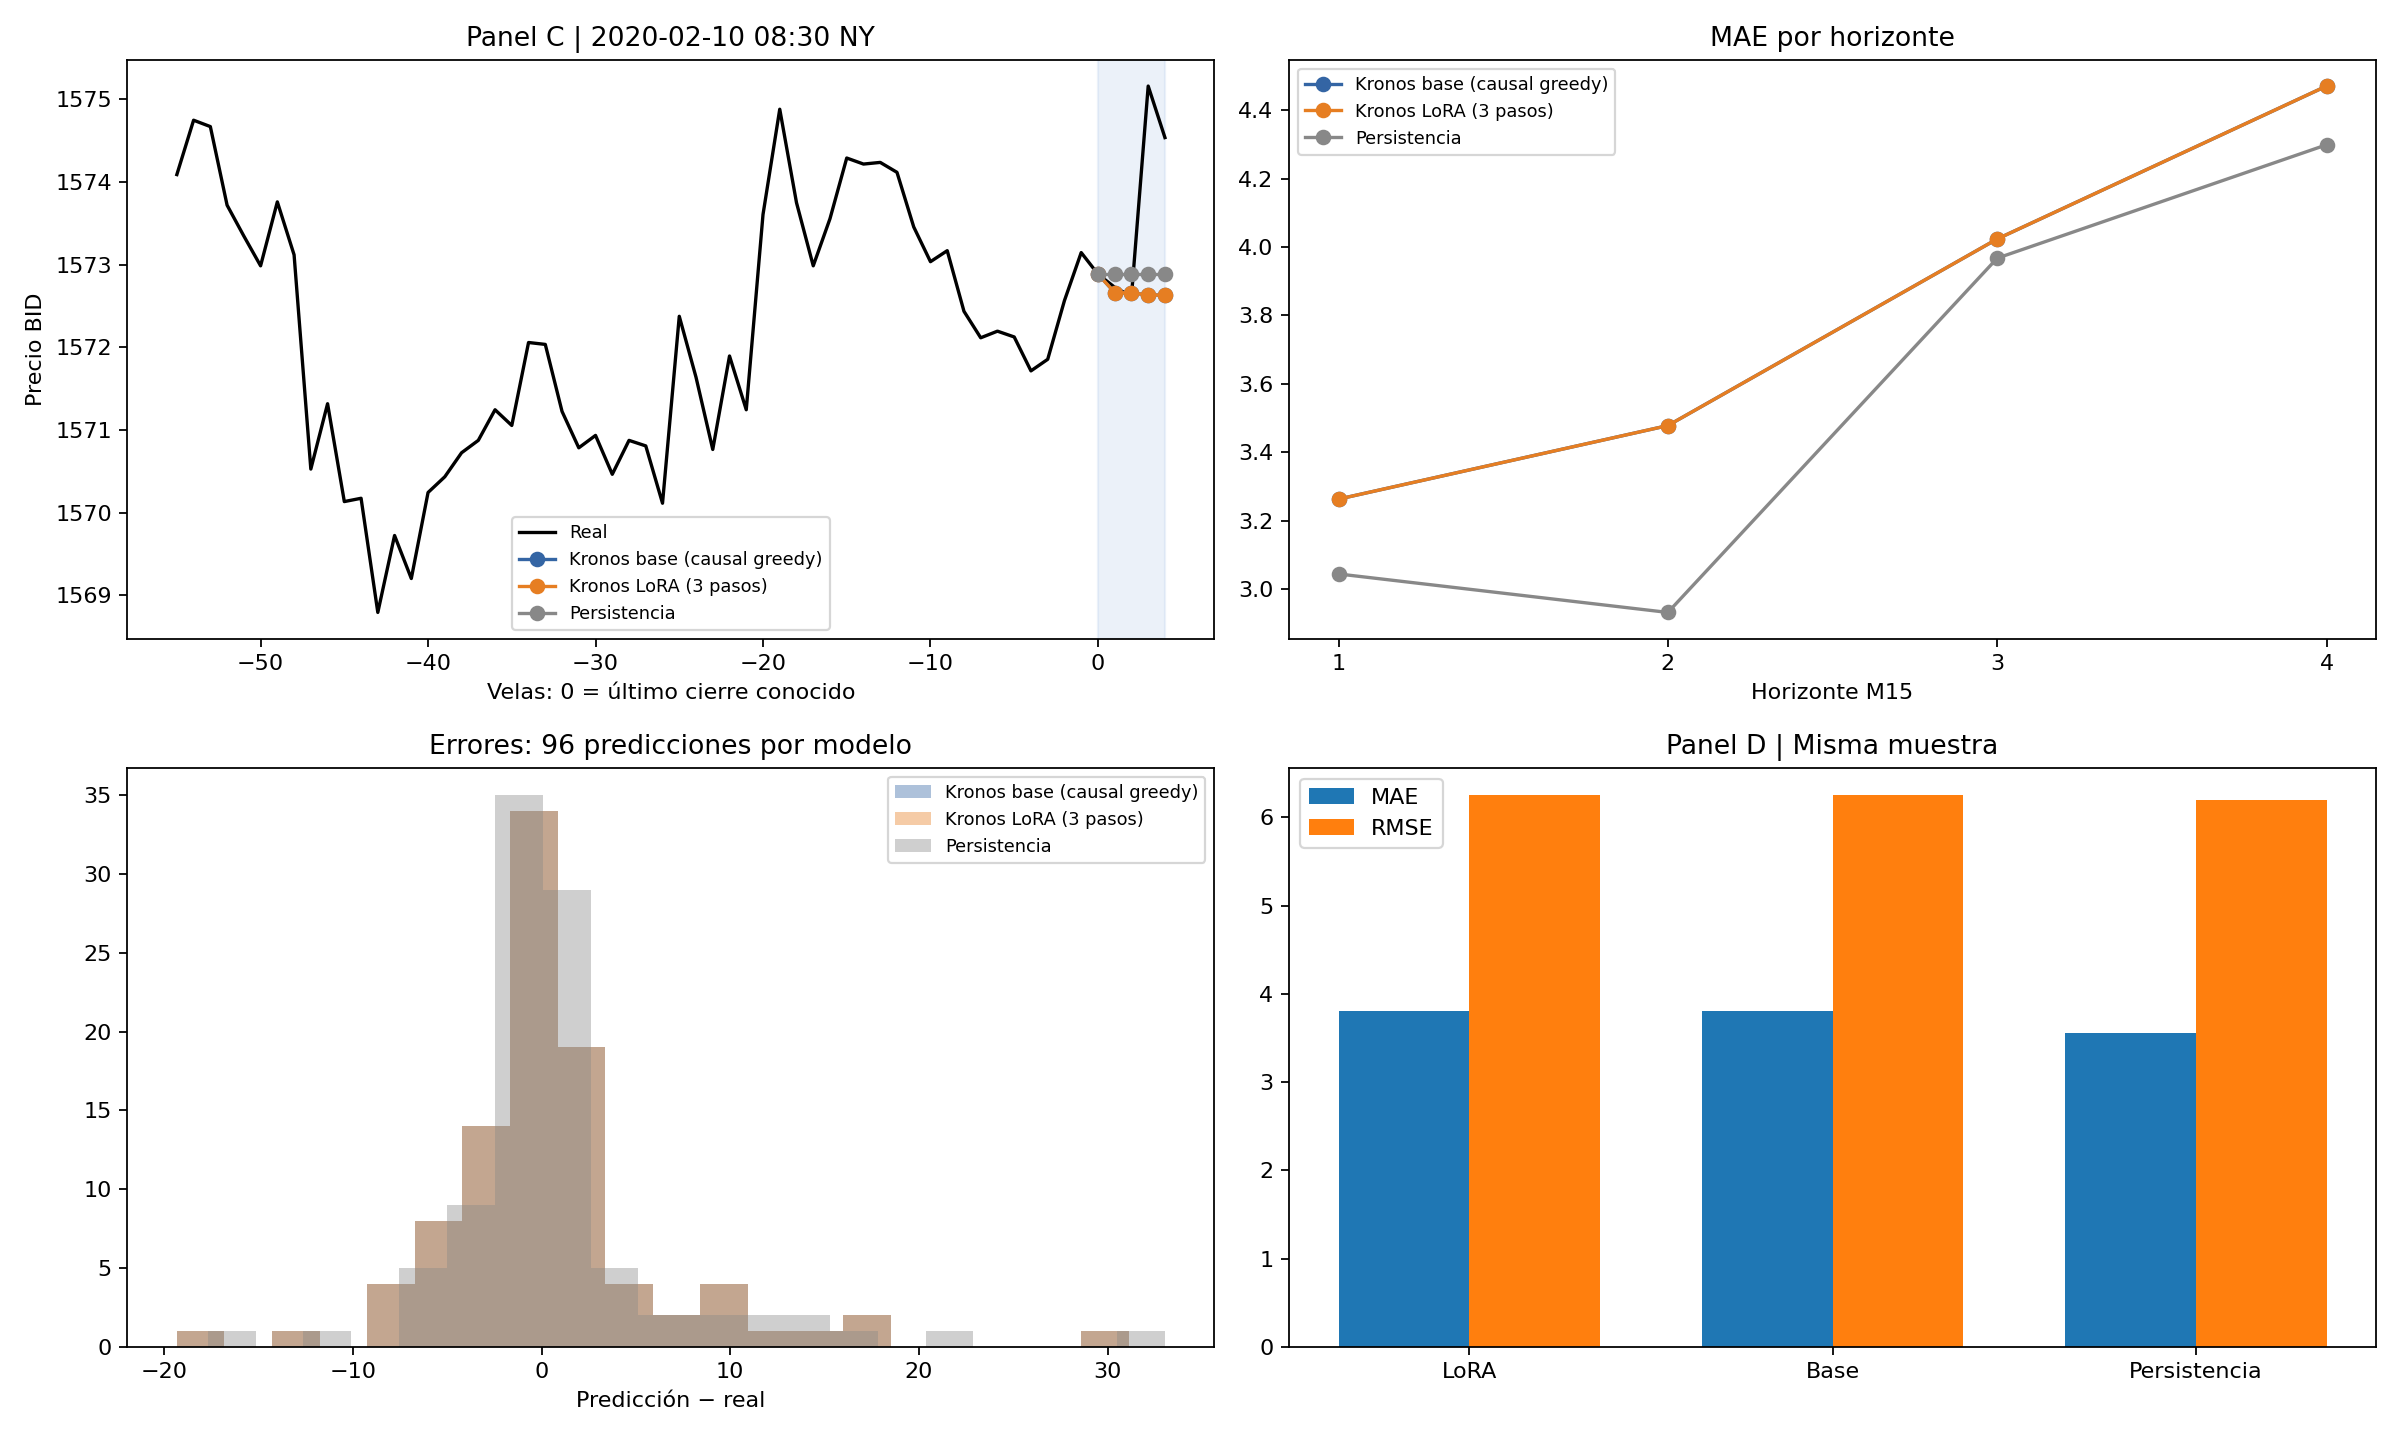

# AXXEL CAPITAL — KRONOS LoRA | INFORME DE RESULTADOS

**Ejecución real:** 20261112T024524Z_6f6ef2, Google Colab. **Decisión: LoRA técnicamente viable; ventaja predictiva no demostrada.**

## 1. Arquitectura verificada
Kronos-small: 8 bloques Transformer, d_model=512, 8 cabezas, FFN=1024, RMSNorm, RoPE, embeddings jerárquicos y doble cabezal s1/s2 (1024 clases cada uno). Tokenizador BSQ congelado, entrada de 6 variables, dimensión 256, 20 bits (10+10), 3 bloques encoder y 3 decoder reales. La configuración nominal de 4 capas genera n-1 bloques en la fuente oficial: no se confunde el número configurado con el instanciado.
Fuente oficial del commit 67b630e67f6a18c9e9be918d9b4337c960db1e9a: tres archivos verificados byte a byte. Revisión de pesos {'Kronos-small': '901c26c1332695a2a8f243eb2f37243a37bea320', 'Kronos-Tokenizer-base': '0e0117387f39004a9016484a186a908917e22426'}. Existe una modificación previa explícita: atención cruzada causal en train/eval y rollout greedy con s1 alineado. Se conserva idéntica en base y LoRA.

## 2. Configuración LoRA
Rank 8, alpha 16 (escala 2), dropout 0.10, LR 0.0001 fijo, AdamW, weight decay 0.01, clipping de gradiente 1.0, batch 1, FP32, seed 271828. Dieciocho módulos Q/V: 16 en autoatención + 2 en dependencia. Sin entrenar el tokenizador ni los pesos originales. Contexto 56 velas (14 horas) y horizonte 4 (1 hora).

## 3. Hardware empleado
CPU de Colab, 2 hilos, RAM total 12.671 GiB. Pico RSS del proceso muestreado durante pasos 1.441 GiB; incluye otras variables de la sesión. Piloto 1.631 s; media por paso 0.517 s. Evaluación base 13.602 s y LoRA 12.396 s. GPU no disponible: memoria y consumo GPU N/A.
CPU actual es el mínimo **demostrado**; no se probaron CPUs menores. Presupuesto estático de parámetros/gradientes/Adam: 111.73 MiB, excluyendo activaciones y memoria del runtime. T4 16 GB es candidata inicial a medir para ampliar ensayos; L4 24 GB, A100 40/80 GB y H100 80 GB no se midieron ni son necesarios para este piloto. Aumentar batch de 1 a 2/4/8 solo tras medir pico reservado <80% y estabilidad. Escalar cuando tiempo o memoria excedan el presupuesto; más GPU no demuestra mejores predicciones.

## 4. Parámetros
Predictor base congelado: 24,741,376. Adaptadores entrenables: 147,456. Predictor adaptado total: 24,888,832; fracción entrenable 0.5925%. Tokenizador congelado adicional: 3,958,042. Total combinado: 28,846,874.

## 5. Prueba piloto
Tres pasos, tres ventanas train 2010–2019 registradas exactamente. Todas las pérdidas y gradientes fueron finitos. Los 36 tensores A/B cambiaron. Hashes de todos los pesos/buffers originales y del tokenizador permanecen idénticos. Inicialización B=0 reprodujo exactamente la salida base. Checkpoint de adaptadores recargado y predicción idéntica.
Pérdida eval de la misma ventana train: 3.86023331 → 3.85743475; esta observación no mide generalización. Las pérdidas de entrenamiento por paso corresponden a ventanas distintas, por lo que su trayectoria no demuestra convergencia.

## 6. Gráficas de entrenamiento
Panel B interactivo y PNG real: pérdida, LR, norma de gradiente, RAM, tiempo y GPU N/A. Panel A: arquitectura, parámetros congelados/entrenables y distribución por módulo. Tablas completas y hashes en auditoria/ y metricas/.

## 7. Predicción y validez
Panel C interactivo: selector de las 24 ventanas con 56 velas de contexto y 4 objetivos, errores por horizonte e histograma. 24 días distintos de validación 2020–2022, 96 cierres por modelo. Anclas 08:30/09:30/10:30/11:30 America/New_York con DST. Estadísticas de normalización exclusivamente del contexto; 60 velas continuas, ninguna cruza particiones. Pruebas de invariancia a futuro pasan en normalización, tokenizer, atención train/eval y rollout. Test 2023–2024 no se leyó en esta misión.

## 8. Comparación contra base y persistencia
LoRA: MAE 3.80863444, RMSE 6.24949998, precisión direccional 45.8333%.
Base: MAE 3.80863444, RMSE 6.24949998, precisión direccional 45.8333%.
Persistencia: MAE 3.56029129, RMSE 6.20043013. Predice cambio cero, por lo que no emite dirección (cobertura 0%; acierto condicionado N/A).
Diferencia máxima de precios base/LoRA: 0.00000000. Tres pasos cambiaron adaptadores y pérdida, pero no los tokens ganadores greedy de esta muestra. LoRA no supera persistencia en MAE. Resultados por NY y año incluidos. Base se refiere a pesos originales con el mismo protocolo causal greedy, no al muestreador oficial KronosPredictor.

## 9. Errores y limitaciones
Se corrigió un error de sintaxis durante la inserción de la primera celda; todas las celdas finales se ejecutaron correctamente. Veinticuatro ventanas no bastan para establecer un efecto estadístico; los cuatro horizontes por ventana están correlacionados. No hay intervalos de confianza, prueba final, backtest ni costes de transacción. Posible solapamiento con preentrenamiento externo desconocido. Datos BID; volumen de procedencia pendiente y amount ausente codificado con cero. No existe auditoría económica de rentabilidad. GPU no perfilada. Los checkpoints históricos se preservaron y el último se cargó estrictamente; su L=64 impide confundirlo con este ensayo L=56.

## 10. Conclusión y siguiente fase
**GO técnico:** la integración LoRA funciona y el laboratorio está preparado para diseñar un SFT supervisado controlado. **NO-GO predictivo/trading:** no se ha demostrado mejora, ventaja ni rentabilidad. Antes de un entrenamiento amplio, fijar presupuesto, validación temporal/walk-forward, semillas, métricas y criterio de parada; ampliar la comparación base/persistencia en validación y resolver volumen/amount. Conservar test 2023–2024 para una evaluación final sin ajuste de hiperparámetros. Ningún entrenamiento completo ni orden de trading fue iniciado.

### Reproducción y artefactos
En runtime nuevo: ejecutar dependencias originales, montar Drive y ejecutar las celdas Misión 04 1–7 en orden. La sección 2 usa la implementación histórica fijada y recupera pesos por revisión si faltan. Cada sección 1 crea un directorio nuevo. La celda de piloto restaura los adaptadores iniciales al repetirse: no acumula pasos.
Carpeta: /content/drive/MyDrive/AXXEL_CAPITAL/MISION04_LORA/20261112T024524Z_6f6ef2. Checkpoint: checkpoints/lora_step003.pt; contiene solo adaptadores, optimizador, configuración y RNG, y exige pesos base fijados para recargar. El RNG guardado corresponde al momento posterior a las pruebas de auditoría; este piloto no certifica una reanudación de entrenamiento largo.
Respaldo previo: https://colab.research.google.com/drive/12247HRxRoitH1eD8HEdKPqC_rAhvd6Eq
Fuentes: https://github.com/shiyu-coder/Kronos/tree/67b630e67f6a18c9e9be918d9b4337c960db1e9a ; https://huggingface.co/NeoQuasar/Kronos-small ; https://docs.cloud.google.com/compute/docs/gpus


,model,MAE,RMSE,direction_accuracy_nonflat_pct,direction_coverage_pct,direction_accuracy_issued_pct,n_predictions,n_windows,n_days,n_nonflat
0,Kronos LoRA (3 pasos),3.808634,6.24950,45.833333,100.0,45.833333,96.0,24.0,24.0,96.0
1,Kronos base (causal greedy),3.808634,6.24950,45.833333,100.0,45.833333,96.0,24.0,24.0,96.0
2,Persistencia,3.560291,6.20043,0.000000,0.0,NaN,96.0,24.0,24.0,96.0


,step,train_id,decision_utc,loss,lr,gradient_norm_pre_clip,seconds,rss_peak_sampled_GiB,gpu_peak_allocated_GiB,gpu_peak_reserved_GiB
0,1,6543,2017-08-30 14:30:00+00:00,3.707210,0.0001,0.151609,1.088142,1.441151,None,None
1,2,7949,2019-04-16 13:30:00+00:00,4.141675,0.0001,0.255513,0.232256,1.441151,None,None
2,3,4984,2016-02-16 14:30:00+00:00,5.363853,0.0001,0.175115,0.229464,1.441151,None,None


SNAPSHOT_CUADERNO_GUARDADO (la salida en curso puede no estar incorporada aún).
MISION04_COMPLETADA_RESEARCH_ONLY {"mission": "04", "run_id": "20261112T024524Z_6f6ef2", "pilot_passed": true, "steps": 3, "base_frozen": true, "tokenizer_frozen": true, "reload_verified": true, "validation_valid": true, "validation_windows": 24, "validation_predictions_per_model": 96, "test_read_in_mission04": false, "full_training_started": false, "orders_enabled": false, "technical_lora_viable": true, "predictive_edge_demonstrated": false, "decision": "GO_TECHNICAL_RESEARCH_ONLY; NO_GO_TRADING", "max_base_lora_prediction_difference": 0.0}
ARTEFACTOS: 56 | RUTA: /content/drive/MyDrive/AXXEL_CAPITAL/MISION04_LORA/20261112T024524Z_6f6ef2


In [ ]:
 #@title MISIÓN 04 · 7. Hardware medido, verificación visual e informe final
from IPython.display import Image
m4_steps=pd.DataFrame(M4_HISTORY)
M4_HW['pilot_seconds']=M4_TRAIN_SECONDS
M4_HW['step_seconds_mean']=float(m4_steps.seconds.mean())
M4_HW['process_RSS_peak_sampled_GiB']=float(m4_steps.rss_peak_sampled_GiB.max())
M4_HW['process_lifetime_max_RSS_GiB']=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/2**20
M4_HW['evaluation_seconds']=M4_EVAL_TIMES
M4_HW['static_parameters_plus_lora_grads_adam_MiB']=((M4_N_BASE+M4_N_TOK+M4_N_TRAIN)*4+M4_N_TRAIN*12)/2**20
M4_HW['static_budget_excludes']='activaciones, temporales, CUDA context, RAM de datos, cachés, copias de auditoría'
M4_HARDWARE_TABLE=pd.DataFrame([
 {'hardware':'CPU actual','memoria_referencia':f'{M4_HW["ram_total_GiB"]:.2f} GiB RAM','estado':'MEDIDO: viable, batch 1 / FP32','uso':'Piloto y evaluación acotada; no se probó una máquina de menor RAM'},
 {'hardware':'T4','memoria_referencia':'16 GB GPU','estado':'CANDIDATO, no medido','uso':'Primera GPU a probar; batch 1, luego 2/4/8 si pico reservado <80%'},
 {'hardware':'L4','memoria_referencia':'24 GB GPU','estado':'CANDIDATO, no medido','uso':'Escalar si el tiempo medido de T4 excede el presupuesto o falta memoria'},
 {'hardware':'A100','memoria_referencia':'40/80 GB GPU según variante','estado':'No necesario para este piloto','uso':'Justificar con perfiles de lotes/contextos mayores, no por calidad predictiva'},
 {'hardware':'H100','memoria_referencia':'80 GB GPU (variante H100 de referencia)','estado':'No necesario para este piloto','uso':'Solo si experimentos amplios justifican rendimiento y coste'}])
M4_HARDWARE_TABLE.to_csv(M4_DIR/'auditoria/comparacion_hardware.csv',index=False)
m4_json(M4_DIR/'auditoria/hardware_final.json',M4_HW)
M4_VERSIONS={d.metadata['Name']:d.version for d in md.distributions() if d.metadata.get('Name')}
m4_json(M4_DIR/'auditoria/versiones_completas.json',M4_VERSIONS)
(M4_DIR/'auditoria/requirements_observed.txt').write_text('\n'.join(f'{k}=={v}' for k,v in sorted(M4_VERSIONS.items())))
display(Markdown('## Diagnóstico computacional final'))
display(pd.DataFrame([M4_HW])); display(M4_HARDWARE_TABLE)
print('GPU: no se asignó ninguna; consumo GPU=N/A. No se afirma haber medido T4/L4/A100/H100.')
print('Referencias de capacidades: https://docs.cloud.google.com/compute/docs/gpus ; https://www.nvidia.com/es-la/data-center/tesla-t4/ ; https://www.nvidia.com/es-es/data-center/l4/')
# Imágenes estáticas verificables, además de todos los paneles Plotly interactivos.
fig,axes=plt.subplots(2,3,figsize=(15,8))
for ax,key,title in zip(axes.ravel()[:5],['loss','lr','gradient_norm_pre_clip','rss_peak_sampled_GiB','seconds'],['Pérdida (3 ventanas distintas)','Learning rate','Norma gradiente antes de clip','Pico RAM muestreado (GiB)','Segundos por optimización']):
    ax.plot(m4_steps.step,m4_steps[key],marker='o'); ax.set(title=title,xlabel='Paso',xticks=[1,2,3]); ax.grid(alpha=.25)
axes.ravel()[5].axis('off'); axes.ravel()[5].text(.1,.5,'CPU: GPU no disponible\n3 pasos ≠ convergencia',fontsize=13)
fig.suptitle('Panel B | Entrenamiento LoRA medido',fontsize=17); fig.tight_layout()
fig.savefig(M4_DIR/'graficas/panel_B_estatico.png',dpi=160); plt.close(fig)
display(Image(filename=str(M4_DIR/'graficas/arquitectura.png')))
display(Image(filename=str(M4_DIR/'graficas/panel_B_estatico.png')))
fig,axes=plt.subplots(2,2,figsize=(15,9))
meta=m4_eval_ix.iloc[0]; s=int(meta.start_row)
x=np.arange(-55,5); axes[0,0].plot(x,m4_df.close.iloc[s:s+60],color='black',label='Real')
for model,color in zip(models,colors):
    g=m4_pred[(m4_pred.window==0)&(m4_pred.model==model)].sort_values('horizon')
    axes[0,0].plot(np.arange(5),np.r_[g.last_close.iloc[0],g.prediction],marker='o',color=color,label=model)
    gh=M4_BY_H[M4_BY_H.model==model]
    axes[0,1].plot(gh.horizon,gh.MAE,marker='o',label=model,color=color)
    ge=m4_pred[m4_pred.model==model]
    axes[1,0].hist(ge.error,bins=20,alpha=.4,label=model,color=color)
axes[0,0].axvspan(0,4,color='#bdd3ec',alpha=.3); axes[0,0].set(title=f'Panel C | {meta.ny_date} {meta.ny_hour} NY',xlabel='Velas: 0 = último cierre conocido',ylabel='Precio BID'); axes[0,0].legend(fontsize=8)
axes[0,1].set(title='MAE por horizonte',xlabel='Horizonte M15',xticks=[1,2,3,4]); axes[0,1].legend(fontsize=8)
axes[1,0].set(title='Errores: 96 predicciones por modelo',xlabel='Predicción − real'); axes[1,0].legend(fontsize=8)
xx=np.arange(len(M4_METRICS)); axes[1,1].bar(xx-.18,M4_METRICS.MAE,.36,label='MAE'); axes[1,1].bar(xx+.18,M4_METRICS.RMSE,.36,label='RMSE')
axes[1,1].set(xticks=xx,xticklabels=['LoRA','Base','Persistencia'],title='Panel D | Misma muestra'); axes[1,1].legend()
fig.tight_layout(); fig.savefig(M4_DIR/'graficas/paneles_CD_estaticos.png',dpi=160); plt.close(fig)
display(Image(filename=str(M4_DIR/'graficas/paneles_CD_estaticos.png')))
base_row=M4_METRICS.set_index('model').loc['Kronos base (causal greedy)']
lora_row=M4_METRICS.set_index('model').loc['Kronos LoRA (3 pasos)']
persist_row=M4_METRICS.set_index('model').loc['Persistencia']
paired=m4_pred[m4_pred.model!='Persistencia'].pivot(index=['window','horizon'],columns='model',values='prediction')
M4_PRED_MAX_DIFF=float((paired.iloc[:,0]-paired.iloc[:,1]).abs().max())
M4_STATUS={'mission':'04','run_id':M4_RUN,'pilot_passed':True,'steps':3,'base_frozen':M4_FROZEN_OK,'tokenizer_frozen':M4_TOKEN_OK,'reload_verified':M4_RELOAD_OK,'validation_valid':M4_EVAL_OK,'validation_windows':24,'validation_predictions_per_model':96,'test_read_in_mission04':False,'full_training_started':False,'orders_enabled':False,'technical_lora_viable':True,'predictive_edge_demonstrated':False,'decision':'GO_TECHNICAL_RESEARCH_ONLY; NO_GO_TRADING','max_base_lora_prediction_difference':M4_PRED_MAX_DIFF}
m4_json(M4_DIR/'informes/status.json',M4_STATUS)
M4_REPORT=f'''# AXXEL CAPITAL — KRONOS LoRA | INFORME DE RESULTADOS

**Ejecución real:** {M4_RUN}, Google Colab. **Decisión: LoRA técnicamente viable; ventaja predictiva no demostrada.**

## 1. Arquitectura verificada
Kronos-small: 8 bloques Transformer, d_model=512, 8 cabezas, FFN=1024, RMSNorm, RoPE, embeddings jerárquicos y doble cabezal s1/s2 (1024 clases cada uno). Tokenizador BSQ congelado, entrada de 6 variables, dimensión 256, 20 bits (10+10), 3 bloques encoder y 3 decoder reales. La configuración nominal de 4 capas genera n-1 bloques en la fuente oficial: no se confunde el número configurado con el instanciado.
Fuente oficial del commit {M4_COMMIT}: tres archivos verificados byte a byte. Revisión de pesos {kp.REVISIONS}. Existe una modificación previa explícita: atención cruzada causal en train/eval y rollout greedy con s1 alineado. Se conserva idéntica en base y LoRA.

## 2. Configuración LoRA
Rank 8, alpha 16 (escala 2), dropout 0.10, LR 0.0001 fijo, AdamW, weight decay 0.01, clipping de gradiente 1.0, batch 1, FP32, seed 271828. Dieciocho módulos Q/V: 16 en autoatención + 2 en dependencia. Sin entrenar el tokenizador ni los pesos originales. Contexto 56 velas (14 horas) y horizonte 4 (1 hora).

## 3. Hardware empleado
CPU de Colab, {M4_HW['cpu_threads']} hilos, RAM total {M4_HW['ram_total_GiB']:.3f} GiB. Pico RSS del proceso muestreado durante pasos {M4_HW['process_RSS_peak_sampled_GiB']:.3f} GiB; incluye otras variables de la sesión. Piloto {M4_TRAIN_SECONDS:.3f} s; media por paso {M4_HW['step_seconds_mean']:.3f} s. Evaluación base {M4_EVAL_TIMES['Kronos base (causal greedy)']:.3f} s y LoRA {M4_EVAL_TIMES['Kronos LoRA (3 pasos)']:.3f} s. GPU no disponible: memoria y consumo GPU N/A.
CPU actual es el mínimo **demostrado**; no se probaron CPUs menores. Presupuesto estático de parámetros/gradientes/Adam: {M4_HW['static_parameters_plus_lora_grads_adam_MiB']:.2f} MiB, excluyendo activaciones y memoria del runtime. T4 16 GB es candidata inicial a medir para ampliar ensayos; L4 24 GB, A100 40/80 GB y H100 80 GB no se midieron ni son necesarios para este piloto. Aumentar batch de 1 a 2/4/8 solo tras medir pico reservado <80% y estabilidad. Escalar cuando tiempo o memoria excedan el presupuesto; más GPU no demuestra mejores predicciones.

## 4. Parámetros
Predictor base congelado: {M4_N_BASE:,}. Adaptadores entrenables: {M4_N_TRAIN:,}. Predictor adaptado total: {M4_N_BASE+M4_N_TRAIN:,}; fracción entrenable {100*M4_N_TRAIN/(M4_N_BASE+M4_N_TRAIN):.4f}%. Tokenizador congelado adicional: {M4_N_TOK:,}. Total combinado: {M4_N_BASE+M4_N_TRAIN+M4_N_TOK:,}.

## 5. Prueba piloto
Tres pasos, tres ventanas train 2010–2019 registradas exactamente. Todas las pérdidas y gradientes fueron finitos. Los 36 tensores A/B cambiaron. Hashes de todos los pesos/buffers originales y del tokenizador permanecen idénticos. Inicialización B=0 reprodujo exactamente la salida base. Checkpoint de adaptadores recargado y predicción idéntica.
Pérdida eval de la misma ventana train: {M4_LOSS_BEFORE:.8f} → {M4_LOSS_AFTER:.8f}; esta observación no mide generalización. Las pérdidas de entrenamiento por paso corresponden a ventanas distintas, por lo que su trayectoria no demuestra convergencia.

## 6. Gráficas de entrenamiento
Panel B interactivo y PNG real: pérdida, LR, norma de gradiente, RAM, tiempo y GPU N/A. Panel A: arquitectura, parámetros congelados/entrenables y distribución por módulo. Tablas completas y hashes en auditoria/ y metricas/.

## 7. Predicción y validez
Panel C interactivo: selector de las 24 ventanas con 56 velas de contexto y 4 objetivos, errores por horizonte e histograma. 24 días distintos de validación 2020–2022, 96 cierres por modelo. Anclas 08:30/09:30/10:30/11:30 America/New_York con DST. Estadísticas de normalización exclusivamente del contexto; 60 velas continuas, ninguna cruza particiones. Pruebas de invariancia a futuro pasan en normalización, tokenizer, atención train/eval y rollout. Test 2023–2024 no se leyó en esta misión.

## 8. Comparación contra base y persistencia
LoRA: MAE {lora_row.MAE:.8f}, RMSE {lora_row.RMSE:.8f}, precisión direccional {lora_row.direction_accuracy_nonflat_pct:.4f}%.
Base: MAE {base_row.MAE:.8f}, RMSE {base_row.RMSE:.8f}, precisión direccional {base_row.direction_accuracy_nonflat_pct:.4f}%.
Persistencia: MAE {persist_row.MAE:.8f}, RMSE {persist_row.RMSE:.8f}. Predice cambio cero, por lo que no emite dirección (cobertura 0%; acierto condicionado N/A).
Diferencia máxima de precios base/LoRA: {M4_PRED_MAX_DIFF:.8f}. Tres pasos cambiaron adaptadores y pérdida, pero no los tokens ganadores greedy de esta muestra. LoRA no supera persistencia en MAE. Resultados por NY y año incluidos. Base se refiere a pesos originales con el mismo protocolo causal greedy, no al muestreador oficial KronosPredictor.

## 9. Errores y limitaciones
Se corrigió un error de sintaxis durante la inserción de la primera celda; todas las celdas finales se ejecutaron correctamente. Veinticuatro ventanas no bastan para establecer un efecto estadístico; los cuatro horizontes por ventana están correlacionados. No hay intervalos de confianza, prueba final, backtest ni costes de transacción. Posible solapamiento con preentrenamiento externo desconocido. Datos BID; volumen de procedencia pendiente y amount ausente codificado con cero. No existe auditoría económica de rentabilidad. GPU no perfilada. Los checkpoints históricos se preservaron y el último se cargó estrictamente; su L=64 impide confundirlo con este ensayo L=56.

## 10. Conclusión y siguiente fase
**GO técnico:** la integración LoRA funciona y el laboratorio está preparado para diseñar un SFT supervisado controlado. **NO-GO predictivo/trading:** no se ha demostrado mejora, ventaja ni rentabilidad. Antes de un entrenamiento amplio, fijar presupuesto, validación temporal/walk-forward, semillas, métricas y criterio de parada; ampliar la comparación base/persistencia en validación y resolver volumen/amount. Conservar test 2023–2024 para una evaluación final sin ajuste de hiperparámetros. Ningún entrenamiento completo ni orden de trading fue iniciado.

### Reproducción y artefactos
En runtime nuevo: ejecutar dependencias originales, montar Drive y ejecutar las celdas Misión 04 1–7 en orden. La sección 2 usa la implementación histórica fijada y recupera pesos por revisión si faltan. Cada sección 1 crea un directorio nuevo. La celda de piloto restaura los adaptadores iniciales al repetirse: no acumula pasos.
Carpeta: {M4_DIR}. Checkpoint: checkpoints/lora_step003.pt; contiene solo adaptadores, optimizador, configuración y RNG, y exige pesos base fijados para recargar. El RNG guardado corresponde al momento posterior a las pruebas de auditoría; este piloto no certifica una reanudación de entrenamiento largo.
Respaldo previo: {M4_BACKUP}
Fuentes: https://github.com/shiyu-coder/Kronos/tree/{M4_COMMIT} ; https://huggingface.co/NeoQuasar/Kronos-small ; https://docs.cloud.google.com/compute/docs/gpus
'''
(M4_DIR/'informes/INFORME_RESULTADOS.md').write_text(M4_REPORT,encoding='utf-8')
display(Markdown(M4_REPORT))
display(M4_METRICS.round(6)); display(m4_steps)
# Copia auditable del cuaderno existente; no sustituye el notebook ni sus outputs.
try:
    from google.colab import _message
    current_notebook=_message.blocking_request('get_ipynb',timeout_sec=30)['ipynb']
    m4_json(M4_DIR/'informes/Kronos_SFT_verificado_MISION04_snapshot.ipynb',current_notebook)
    print('SNAPSHOT_CUADERNO_GUARDADO (la salida en curso puede no estar incorporada aún).')
except Exception as exc:
    print('Snapshot secundario no disponible:',type(exc).__name__,str(exc)[:200])
manifest=[{'file':str(p.relative_to(M4_DIR)),'bytes':p.stat().st_size,'sha256':m4_sha(p)} for p in sorted(M4_DIR.rglob('*')) if p.is_file()]
m4_json(M4_DIR/'informes/manifest_artefactos.json',manifest)
print('MISION04_COMPLETADA_RESEARCH_ONLY',json.dumps(M4_STATUS,ensure_ascii=False))
print('ARTEFACTOS:',len(manifest),'| RUTA:',M4_DIR)

In [ ]:
#@title MISIÓN 05 · 1. Reconexión, respaldo y diagnóstico
from pathlib import Path
from datetime import datetime, timezone
import os, sys, json, hashlib, uuid, platform, time, random, copy, gc, inspect
import numpy as np, pandas as pd, torch, psutil
from IPython.display import display, Markdown
from google.colab import drive, _message
if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')
M5_BASE=Path('/content/drive/MyDrive/AXXEL_CAPITAL')
M5_PREV=M5_BASE/'MISION04_LORA/20261112T024524Z_6f6ef2'
M5_HIST=M5_BASE/'Kronos_SFT_verificado_20261107/ejecuciones/20261112T022707Z_55c83b'
M5_ID=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:6]
M5_DIR=M5_BASE/'MISION05_LORA'/M5_ID
for d in ['auditoria','checkpoints','metricas','graficas','informes']: (M5_DIR/d).mkdir(parents=True,exist_ok=False)
def m5_json(p,x): Path(p).write_text(json.dumps(x,indent=2,default=str),encoding='utf-8')
def m5_sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(1<<20),b''): h.update(b)
    return h.hexdigest()
torch.set_num_threads(min(4,os.cpu_count() or 1))
M5_DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
M5_HW={'device':str(M5_DEVICE),'torch':torch.__version__,'python':platform.python_version(),'threads':torch.get_num_threads(),'RAM_GiB':psutil.virtual_memory().total/2**30,'RSS_GiB':psutil.Process().memory_info().rss/2**30,'GPU':torch.cuda.get_device_name() if torch.cuda.is_available() else None}
m5_json(M5_DIR/'auditoria/hardware_inicial.json',M5_HW)
M5_NB=_message.blocking_request('get_ipynb',timeout_sec=30)['ipynb']
m5_json(M5_DIR/'auditoria/cuaderno_inicio.ipynb',M5_NB)
print('NUEVA_EJECUCION',M5_DIR); print('HARDWARE',M5_HW)
print('BACKUP_DRIVE https://colab.research.google.com/drive/18r4MCx8E97yMsBetJQM34muAxKkX4DyF')
print('VARIABLES_PREVIAS',[(k,k in globals()) for k in ['m4_model','m4_df','kp','m4_train_ds']])
print('INVENTARIO_PROCEDENCIA', [str(p.relative_to(M5_BASE)) for p in M5_BASE.rglob('*') if p.is_file() and p.suffix in ['.py','.json','.md','.csv'] and any(t in p.name.lower() for t in ['conver','audit','manifi','manifest','readme'])][:100])
print('M4_DATA_AUDIT', (M5_PREV/'auditoria/datasets.json').read_text()[:3500])
print('DIAGNOSTICO_OK')

Mounted at /content/drive
NUEVA_EJECUCION /content/drive/MyDrive/AXXEL_CAPITAL/MISION05_LORA/20261112T130149Z_80e373
HARDWARE {'device': 'cpu', 'torch': '2.14.1+cpu', 'python': '3.13.18', 'threads': 2, 'RAM_GiB': 12.671405792236328, 'RSS_GiB': 0.3388328552246094, 'GPU': None}
BACKUP_DRIVE https://colab.research.google.com/drive/18r4MCx8E97yMsBetJQM34muAxKkX4DyF
VARIABLES_PREVIAS [('m4_model', False), ('m4_df', False), ('kp', False), ('m4_train_ds', False)]
INVENTARIO_PROCEDENCIA ['reports/auditoria_m1_2010_2024.csv', 'reports/conversion_m5_m15_2010_2024.csv', 'MISION04_LORA/20261112T024524Z_6f6ef2/informes/manifest_artefactos.json', 'Kronos_SFT_verificado_20261107/ejecuciones/20261112T022707Z_55c83b/resultados/source_manifest.json', 'Kronos_SFT_verificado_20261107/ejecuciones/20261111T220538Z_84e689/resultados/source_manifest.json', 'Kronos_SFT_verificado_20261107/ejecuciones/20261109T235309Z_9e4b39/resultados/source_manifest.json', 'Kronos_SFT_verificado_20261107/ejecuciones/20261109T

In [ ]:
#@title MISIÓN 05 · 2. Modelo fijado, datos íntegros y procedencia
import subprocess, importlib.metadata as md, shutil, zipfile, math
subprocess.run([sys.executable,'-m','pip','install','-q','einops==0.8.2','safetensors==0.6.2','huggingface_hub==1.4.0','pyarrow==23.0.0','plotly'],check=True)
sys.path.insert(0,str(M5_HIST))
import kronos_pipeline as kp
assert m5_sha(M5_HIST/'kronos_pipeline.py')=='1424fb451942c7e1e1823808405f428283f9b1aacf7b34d08df7ca9edb503016'
shutil.copytree(M5_HIST/'vendor',M5_DIR/'auditoria/vendor')
shutil.copy2(M5_HIST/'kronos_pipeline.py',M5_DIR/'auditoria/kronos_pipeline.py')
from huggingface_hub import snapshot_download
M5_WEIGHTS=Path('/content/kronos_weights_pinned')
for repo,rev in kp.REVISIONS.items():
    snapshot_download('NeoQuasar/'+repo,revision=rev,local_dir=str(M5_WEIGHTS/repo),allow_patterns=['config.json','model.safetensors'])
m5_model,m5_tok=kp.load_models(M5_WEIGHTS,M5_DEVICE)
m5_model.requires_grad_(False).eval(); m5_tok.requires_grad_(False).eval()
M5_SOURCE=M5_BASE/'datasets/processed/kronos_ohlcv_v1'
M5_MANIFEST=json.loads((M5_PREV/'auditoria/datasets.json').read_text())
parts=[]
for item in M5_MANIFEST:
    p=M5_SOURCE/item['file']; assert m5_sha(p)==item['sha256']
    d=pd.read_parquet(p); d['timestamp_utc']=pd.to_datetime(d.timestamp_utc,utc=True)
    assert len(d)==item['rows'] and d.m1_candles.eq(15).all() and not d.isna().any().any()
    assert np.isfinite(d[['open','high','low','close','volume']]).all().all()
    assert (d.volume>=0).all() and (d.low>0).all()
    assert (d.low<=d[['open','close']].min(axis=1)).all() and (d.high>=d[['open','close']].max(axis=1)).all()
    parts.append(d)
m5_df=pd.concat(parts,ignore_index=True); del parts,d
assert m5_df.timestamp_utc.is_monotonic_increasing and m5_df.timestamp_utc.is_unique
assert m5_df.timestamp_utc.dt.year.max()==2022
m5_ix=pd.read_parquet(M5_PREV/'auditoria/ventanas_l56_h4.parquet')
for c in ['decision_utc','context_start','target_end']: m5_ix[c]=pd.to_datetime(m5_ix[c],utc=True)
s=m5_ix.start_row.to_numpy(np.int64); ts=m5_df.timestamp_utc.astype('int64').to_numpy()
assert np.all(ts[s[:,None]+np.arange(60)]==ts[s,None]+np.arange(60)*15*60*10**9)
assert np.array_equal(ts[s+56],m5_ix.decision_utc.astype('int64').to_numpy())
assert m5_ix.decision_utc.dt.tz_convert('America/New_York').dt.strftime('%H:%M').eq(m5_ix.ny_hour).all()
m5_train_ix=m5_ix[m5_ix.split=='train'].reset_index(drop=True)
m5_val_ix=m5_ix[m5_ix.split=='validation'].reset_index(drop=True)
assert m5_train_ix.target_end.max()<m5_val_ix.context_start.min()
class M5Dataset(torch.utils.data.Dataset):
    def __init__(self,index):
        self.L,self.H=56,4; self.index=index.reset_index(drop=True); self.starts=self.index.start_row.to_numpy(np.int64)
        self.values=np.column_stack([m5_df[['open','high','low','close','volume']].to_numpy(np.float32),np.zeros(len(m5_df),np.float32)])
        t=m5_df.timestamp_utc.dt
        self.stamp=np.column_stack([t.minute,t.hour,t.weekday,t.day,t.month]).astype(np.float32)
    def __len__(self): return len(self.starts)
    def __getitem__(self,i):
        s=int(self.starts[i]); raw=self.values[s:s+60].copy(); x,mean,scale=kp.normalize(raw,56)
        return {'x':torch.from_numpy(x),'stamp':torch.from_numpy(self.stamp[s:s+60].copy()),'loss_mask':torch.from_numpy(np.arange(59)>=55),'mean':torch.from_numpy(mean),'scale':torch.from_numpy(scale),'truth':torch.from_numpy(raw[56:]),'last_close':torch.tensor(raw[55,3])}
m5_train=M5Dataset(m5_train_ix); m5_val=M5Dataset(m5_val_ix)
from torch.utils.data import default_collate
def m5_batch(ds,ids): return kp.to_device(default_collate([ds[int(i)] for i in ids]),M5_DEVICE)
m5_json(M5_DIR/'auditoria/datasets.json',M5_MANIFEST)
m5_ix.to_parquet(M5_DIR/'auditoria/ventanas_l56_h4.parquet',index=False)
m5_json(M5_DIR/'auditoria/versiones.json',{x.metadata['Name']:x.version for x in md.distributions() if x.metadata.get('Name')})
print('FUENTES_INTACTAS; TEST 2023-2024 NO LEIDO')
display(m5_ix.groupby(['split','year','ny_hour']).size().unstack())
print('CONVERSION', (M5_BASE/'reports/conversion_m5_m15_2010_2024.csv').read_text()[:1800])
M5_RAW=M5_BASE/'datasets/raw/XAUUSD_M1_2010_2024.zip'
with zipfile.ZipFile(M5_RAW) as z:
    M5_RAW_SAMPLE=next(n for n in z.namelist() if n.lower().endswith('.csv') and '2010' in n)
    with z.open(M5_RAW_SAMPLE) as f: print('CSV_ORIGINAL',M5_RAW_SAMPLE, [f.readline().decode('utf-8-sig') for _ in range(5)])
print('DATOS_MODELO_OK',len(m5_train),len(m5_val))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights from local directory
Loading weights from local directory
FUENTES_INTACTAS; TEST 2023-2024 NO LEIDO


ny_hour          08:30  09:30  10:30  11:30
split      year                            
train      2010     50     84    124    130
           2011    225    234    237    240
           2012    256    258    258    258
           2013    116    211    214    210
           2014    146    214    217    218
           2015    230    241    244    244
           2016    251    254    254    254
           2017    252    255    255    255
           2018    224    237    237    237
           2019    117    153    166    168
validation 2020    229    237    241    243
           2021    247    253    254    253
           2022    248    255    255    255

CONVERSION anio,temporalidad,velas_m1_origen,velas_completas,ventanas_incompletas
2010,M5,364242,70454,3982
2010,M15,364242,22634,2206
2011,M5,362590,71462,2178
2011,M15,362590,23712,928
2012,M5,362146,71658,1899
2012,M15,362146,23816,786
2013,M5,352307,70001,639
2013,M15,352307,23024,545
2014,M5,351440,70085,283
2014,M15,351440,23222,246
2015,M5,353746,70709,58
2015,M15,353746,23538,58
2016,M5,354364,70842,44
2016,M15,354364,23592,40
2017,M5,352788,70518,54
2017,M15,352788,23473,55
2018,M5,353923,70589,254
2018,M15,353923,23391,226
2019,M5,353290,70073,774
2019,M15,353290,22955,667
2020,M5,355495,71041,77
2020,M15,355495,23639,67
2021,M5,354346,70844,34
2021,M15,354346,23594,32
2022,M5,354633,70876,64
2022,M15,354633,23585,62
2023,M5,352969,70429,212
2023,M15,352969,23359,188
2024,M5,286018,57167,47
2024,M15,286018,19031,42

CSV_ORIGINAL XAUUSD_M1_BID_2010_01.csv ['timestamp,open,high,low,close,volume\n', '1262304120000,1096.088,1096.213,1096.017,1096.095,0.00948\n', '1262304240000,10

In [ ]:

#@title MISIÓN 05 · 3. Trazabilidad M1 a M15 y contrato de variables
M5_VOLUME_AUDIT=[]
with zipfile.ZipFile(M5_RAW) as z:
    for year in range(2010,2023):
        names=sorted(n for n in z.namelist() if n.endswith('.csv') and f'_{year}_' in n)
        raw=pd.concat([pd.read_csv(z.open(n)) for n in names],ignore_index=True)
        raw['timestamp_utc']=pd.to_datetime(raw.timestamp,unit='ms',utc=True)
        assert raw.timestamp_utc.is_unique and raw.timestamp_utc.is_monotonic_increasing
        grouped=raw.set_index('timestamp_utc').resample('15min',label='left',closed='left')
        agg=grouped.agg({'open':'first','high':'max','low':'min','close':'last','volume':'sum'})
        agg=agg[grouped.size().eq(15)]
        actual=m5_df[m5_df.timestamp_utc.dt.year.eq(year)].set_index('timestamp_utc')
        assert agg.index.equals(actual.index), f'Indice M1/M15 diferente {year}'
        delta=(agg-actual[agg.columns]).abs().max()
        assert np.allclose(agg.values,actual[agg.columns].values,atol=1e-8,rtol=1e-8), (year,delta)
        M5_VOLUME_AUDIT.append({'year':year,'csv_files':len(names),'M1_rows':len(raw),'M15_rows':len(agg),'volume_max_abs_difference':float(delta.volume),'OHLC_max_abs_difference':float(delta.drop('volume').max()),'volume_min':float(agg.volume.min()),'volume_max':float(agg.volume.max()),'volume_zero_fraction':float(agg.volume.eq(0).mean())})
        print('RECONSTRUCCION_OK',year,len(agg),flush=True)
del raw,agg,actual,grouped
M5_FEATURE_CONTRACT={'features':['open','high','low','close','volume','amount'],'volume_origin':'Suma exacta del campo volume de 15 filas M1 originales BID; 2010-2022 reconstruidos y comparados','volume_semantics':'No certificado como volumen negociado centralizado ni conteo de ticks; unidad económica no documentada en CSV. Se usa exclusivamente como proxy numérico del proveedor.','amount':'Ausente en fuentes; entrada constante cero explícita, no imputación de turnover observado','normalization':'Media/desviacion de las 56 velas de contexto por variable; float32; eps1e-5; clip5','comparison_policy':'Mismas variables y normalización en base y LoRA; no se infiere amount=price*volume sin unidades verificadas','scope':'Experimento condicional al contrato; semántica económica del volumen sigue limitada; no trading'}
pd.DataFrame(M5_VOLUME_AUDIT).to_csv(M5_DIR/'auditoria/reconstruccion_M1_M15.csv',index=False)
m5_json(M5_DIR/'auditoria/contrato_variables.json',M5_FEATURE_CONTRACT)
display(pd.DataFrame(M5_VOLUME_AUDIT)); display(Markdown('**Contrato de variables:** volumen agregado del proveedor, sin atribuirle unidades económicas no documentadas; amount ausente se representa por cero en ambos modelos.'))
print(json.dumps(M5_FEATURE_CONTRACT,ensure_ascii=False,indent=2))
print('TRAZABILIDAD_NUMERICA_OK; SEMANTICA_ECONOMICA_LIMITADA')

RECONSTRUCCION_OK 2010 22634
RECONSTRUCCION_OK 2011 23712
RECONSTRUCCION_OK 2012 23816
RECONSTRUCCION_OK 2013 23024
RECONSTRUCCION_OK 2014 23222
RECONSTRUCCION_OK 2015 23538
RECONSTRUCCION_OK 2016 23592
RECONSTRUCCION_OK 2017 23473
RECONSTRUCCION_OK 2018 23391
RECONSTRUCCION_OK 2019 22955
RECONSTRUCCION_OK 2020 23639
RECONSTRUCCION_OK 2021 23594
RECONSTRUCCION_OK 2022 23585


,year,csv_files,M1_rows,M15_rows,volume_max_abs_difference,OHLC_max_abs_difference,volume_min,volume_max,volume_zero_fraction
0,2010,12,364242,22634,0.0,0.0,0.023890,1.453850,0.0
1,2011,12,362590,23712,0.0,0.0,0.015800,2.005210,0.0
2,2012,12,362146,23816,0.0,0.0,0.013200,1.736200,0.0
3,2013,12,352307,23024,0.0,0.0,0.006500,27.330300,0.0
4,2014,12,351440,23222,0.0,0.0,0.011100,3.563990,0.0
5,2015,12,353746,23538,0.0,0.0,0.023940,3.715500,0.0
6,2016,12,354364,23592,0.0,0.0,0.008200,4.463200,0.0
7,2017,12,352788,23473,0.0,0.0,0.000610,6.690490,0.0
8,2018,12,353923,23391,0.0,0.0,0.012025,3.825330,0.0
9,2019,12,353290,22955,0.0,0.0,0.009251,6.528710,0.0


**Contrato de variables:** volumen agregado del proveedor, sin atribuirle unidades económicas no documentadas; amount ausente se representa por cero en ambos modelos.

{
  "features": [
    "open",
    "high",
    "low",
    "close",
    "volume",
    "amount"
  ],
  "volume_origin": "Suma exacta del campo volume de 15 filas M1 originales BID; 2010-2022 reconstruidos y comparados",
  "volume_semantics": "No certificado como volumen negociado centralizado ni conteo de ticks; unidad económica no documentada en CSV. Se usa exclusivamente como proxy numérico del proveedor.",
  "amount": "Ausente en fuentes; entrada constante cero explícita, no imputación de turnover observado",
  "normalization": "Media/desviacion de las 56 velas de contexto por variable; float32; eps1e-5; clip5",
  "comparison_policy": "Mismas variables y normalización en base y LoRA; no se infiere amount=price*volume sin unidades verificadas",
  "scope": "Experimento condicional al contrato; semántica económica del volumen sigue limitada; no trading"
}
TRAZABILIDAD_NUMERICA_OK; SEMANTICA_ECONOMICA_LIMITADA


In [ ]:
#@title MISIÓN 05 · 4. Recuperación tras desconexión (sin repetir auditoría)
from pathlib import Path
from datetime import datetime, timezone
import os, sys, json, hashlib, uuid, platform, time, random, copy, gc, inspect
import numpy as np, pandas as pd, torch, psutil
from IPython.display import display, Markdown
from google.colab import drive, _message
if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')
M5_BASE=Path('/content/drive/MyDrive/AXXEL_CAPITAL')
M5_PREV=M5_BASE/'MISION04_LORA/20261112T024524Z_6f6ef2'
M5_HIST=M5_BASE/'Kronos_SFT_verificado_20261107/ejecuciones/20261112T022707Z_55c83b'
M5_AUDITED=M5_BASE/'MISION05_LORA/20261112T130149Z_80e373'
M5_ID=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:6]
M5_DIR=M5_AUDITED/('continuacion_'+M5_ID)
for d in ['auditoria','checkpoints','metricas','graficas','informes']: (M5_DIR/d).mkdir(parents=True,exist_ok=False)
def m5_json(p,x): Path(p).write_text(json.dumps(x,indent=2,default=str),encoding='utf-8')
def m5_sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(1<<20),b''): h.update(b)
    return h.hexdigest()
torch.set_num_threads(min(4,os.cpu_count() or 1))
M5_DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
M5_HW={'device':str(M5_DEVICE),'torch':torch.__version__,'python':platform.python_version(),'threads':torch.get_num_threads(),'RAM_GiB':psutil.virtual_memory().total/2**30,'RSS_GiB':psutil.Process().memory_info().rss/2**30,'GPU':torch.cuda.get_device_name() if torch.cuda.is_available() else None}
M5_NB=_message.blocking_request('get_ipynb',timeout_sec=30)['ipynb']
m5_json(M5_DIR/'auditoria/cuaderno_inicio.ipynb',M5_NB)
# Recupera exactamente la celda 2 de esta misión: carga revisiones fijadas y revalida hashes de 13 fuentes.
setup=next(c for c in M5_NB['cells'] if c['metadata'].get('id')=='NhR6xTum2leX')
setup_source=setup['source']; setup_source=''.join(setup_source) if isinstance(setup_source,list) else setup_source
assert setup_source.startswith('#@title MISIÓN 05 · 2. Modelo fijado')
exec(compile(setup_source,'M05_celda_2_recuperacion','exec'),globals())
M5_FEATURE_CONTRACT=json.loads((M5_AUDITED/'auditoria/contrato_variables.json').read_text())
M5_VOLUME_AUDIT=pd.read_csv(M5_AUDITED/'auditoria/reconstruccion_M1_M15.csv')
assert len(M5_VOLUME_AUDIT)==13 and M5_VOLUME_AUDIT.volume_max_abs_difference.max()<1e-8
for name in ['contrato_variables.json','reconstruccion_M1_M15.csv']:
    shutil.copy2(M5_AUDITED/'auditoria'/name,M5_DIR/'auditoria'/name)
m5_json(M5_DIR/'auditoria/hardware_inicial.json',M5_HW)
print('RECUPERACION_OK',M5_DIR, M5_HW)
print('Auditoría numérica previa preservada; entrenamiento M05 todavía no iniciado.')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights from local directory
Loading weights from local directory
FUENTES_INTACTAS; TEST 2023-2024 NO LEIDO


ny_hour          08:30  09:30  10:30  11:30
split      year                            
train      2010     50     84    124    130
           2011    225    234    237    240
           2012    256    258    258    258
           2013    116    211    214    210
           2014    146    214    217    218
           2015    230    241    244    244
           2016    251    254    254    254
           2017    252    255    255    255
           2018    224    237    237    237
           2019    117    153    166    168
validation 2020    229    237    241    243
           2021    247    253    254    253
           2022    248    255    255    255

CONVERSION anio,temporalidad,velas_m1_origen,velas_completas,ventanas_incompletas
2010,M5,364242,70454,3982
2010,M15,364242,22634,2206
2011,M5,362590,71462,2178
2011,M15,362590,23712,928
2012,M5,362146,71658,1899
2012,M15,362146,23816,786
2013,M5,352307,70001,639
2013,M15,352307,23024,545
2014,M5,351440,70085,283
2014,M15,351440,23222,246
2015,M5,353746,70709,58
2015,M15,353746,23538,58
2016,M5,354364,70842,44
2016,M15,354364,23592,40
2017,M5,352788,70518,54
2017,M15,352788,23473,55
2018,M5,353923,70589,254
2018,M15,353923,23391,226
2019,M5,353290,70073,774
2019,M15,353290,22955,667
2020,M5,355495,71041,77
2020,M15,355495,23639,67
2021,M5,354346,70844,34
2021,M15,354346,23594,32
2022,M5,354633,70876,64
2022,M15,354633,23585,62
2023,M5,352969,70429,212
2023,M15,352969,23359,188
2024,M5,286018,57167,47
2024,M15,286018,19031,42

CSV_ORIGINAL XAUUSD_M1_BID_2010_01.csv ['timestamp,open,high,low,close,volume\n', '1262304120000,1096.088,1096.213,1096.017,1096.095,0.00948\n', '1262304240000,10

In [ ]:
#@title MISIÓN 05 · 5. LoRA, RNG exacto, causalidad y perfil de ejecución
import torch.nn as nn, torch.nn.functional as F
from contextlib import contextmanager
torch.use_deterministic_algorithms(True)
M5_CFG={'seed':271828,'L':56,'H':4,'rank':8,'alpha':16,'dropout':0.10,'lr':1e-4,'weight_decay':0.01,'grad_clip':1.0,'batch_size':1,'max_steps':1000,'validation_every':100,'patience':3,'min_delta':1e-4,'monitor':'CE media de 128 ventanas fijas de 2020; checkpoint menor CE incluyendo paso 0','train':'2010-2019; 1000 ventanas distintas, orden fijado antes de optimizar','validation':'2970 ventanas de 2020-2022; cuatro anclas NY con DST','temporal_check':'2021-2022 no usados para seleccionar checkpoint en M05; M04 examinó 16 ventanas de esos años','test_reserved':'2023-2024','dtype':'float32','decoding':'causal_greedy_aligned','research_only':True,'orders_enabled':False}
def m5_hash_state(net,base=False):
    h=hashlib.sha256()
    for k,v in sorted(net.state_dict().items()):
        if base and ('lora_A' in k or 'lora_B' in k): continue
        k=k.replace('.base.','.') if base else k
        h.update(k.encode()); h.update(str(tuple(v.shape)).encode()); h.update(v.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()
M5_BASE_HASH=m5_hash_state(m5_model); M5_TOK_HASH=m5_hash_state(m5_tok)
class M5LoRALinear(nn.Module):
    def __init__(self,base):
        super().__init__(); self.base=base.requires_grad_(False); self.scale=2.0; self.enabled=True
        self.lora_A=nn.Parameter(torch.empty(8,base.in_features,device=base.weight.device)); self.lora_B=nn.Parameter(torch.zeros(base.out_features,8,device=base.weight.device))
        nn.init.kaiming_uniform_(self.lora_A,a=math.sqrt(5)); self.dropout=nn.Dropout(.10)
    def forward(self,x):
        y=self.base(x)
        return y+F.linear(F.linear(self.dropout(x),self.lora_A),self.lora_B)*self.scale if self.enabled else y
M5_TARGETS=[]
for name,module in list(m5_model.named_modules()):
    if type(module).__name__ in ['MultiHeadAttentionWithRoPE','MultiHeadCrossAttentionWithRoPE']:
        for leaf in ['q_proj','v_proj']:
            layer=getattr(module,leaf); assert isinstance(layer,nn.Linear) and layer.in_features==layer.out_features==512
            M5_TARGETS.append(name+'.'+leaf)
            setattr(module,leaf,M5LoRALinear(layer))
assert len(M5_TARGETS)==18
M5_PARAMS={n:p for n,p in m5_model.named_parameters() if p.requires_grad}
assert sum(p.numel() for p in M5_PARAMS.values())==147456
M5_INIT=torch.load(M5_PREV/'checkpoints/adapter_initial.pt',map_location='cpu',weights_only=True)
assert set(M5_INIT)==set(M5_PARAMS)
def m5_load_adapter(state):
    assert set(state)==set(M5_PARAMS)
    with torch.no_grad():
        for n,p in M5_PARAMS.items(): p.copy_(state[n].to(p.device))
def m5_adapter(): return {n:p.detach().cpu().clone() for n,p in M5_PARAMS.items()}
def m5_enable(flag):
    for name in M5_TARGETS: m5_model.get_submodule(name).enabled=flag
def m5_rng(): return {'python':random.getstate(),'numpy':np.random.get_state(),'torch':torch.get_rng_state(),'cuda':torch.cuda.get_rng_state_all() if M5_DEVICE.type=='cuda' else None}
def m5_restore_rng(s):
    random.setstate(s['python']); np.random.set_state(s['numpy']); torch.set_rng_state(s['torch'])
    if s['cuda'] is not None: torch.cuda.set_rng_state_all(s['cuda'])
@contextmanager
def m5_eval_guard():
    state=m5_rng(); was_training=m5_model.training
    try:
        m5_model.eval(); m5_tok.eval()
        with torch.no_grad(): yield
    finally: m5_restore_rng(state); m5_model.train(was_training)
def m5_reset(seed=M5_CFG['seed']):
    m5_load_adapter(M5_INIT); m5_enable(True); kp.seed_all(seed)
    return torch.optim.AdamW(list(M5_PARAMS.values()),lr=M5_CFG['lr'],weight_decay=M5_CFG['weight_decay'])
M5_ORDER=np.random.default_rng(M5_CFG['seed']+1).permutation(len(m5_train))[:1000].tolist()
M5_MONITOR=[]
for hour,g in m5_val_ix[m5_val_ix.year.eq(2020)].groupby('ny_hour'):
    M5_MONITOR.extend(g.iloc[np.linspace(0,len(g)-1,32,dtype=int)].index.tolist())
M5_MONITOR=sorted(M5_MONITOR); assert len(set(M5_MONITOR))==128
m5_train_ix.iloc[M5_ORDER].assign(step=np.arange(1,1001)).to_csv(M5_DIR/'auditoria/orden_train.csv',index=False)
m5_val_ix.loc[M5_MONITOR].to_csv(M5_DIR/'auditoria/monitor_2020.csv',index=False)
M5_CFG['targets']=M5_TARGETS; M5_CFG['commit']=kp.COMMIT; M5_CFG['weight_revisions']=kp.REVISIONS
m5_json(M5_DIR/'auditoria/protocolo.json',M5_CFG)
def m5_step(opt,idx):
    m5_model.train(); m5_tok.eval(); opt.zero_grad(set_to_none=True)
    if M5_DEVICE.type=='cuda': torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0=time.perf_counter(); loss=kp.loss_for_batch(m5_model,m5_tok,m5_batch(m5_train,[idx])); assert torch.isfinite(loss)
    loss.backward()
    assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in M5_PARAMS.values())
    assert all(p.grad is None for p in m5_model.parameters() if not p.requires_grad)
    grad=torch.nn.utils.clip_grad_norm_(list(M5_PARAMS.values()),1.0); assert torch.isfinite(grad)
    opt.step()
    if M5_DEVICE.type=='cuda': torch.cuda.synchronize()
    assert all(torch.isfinite(p).all() for p in M5_PARAMS.values())
    return {'loss':float(loss.detach()),'gradient_norm':float(grad),'lr':opt.param_groups[0]['lr'],'seconds':time.perf_counter()-t0,'RSS_GiB':psutil.Process().memory_info().rss/2**30,'GPU_peak_GiB':torch.cuda.max_memory_allocated()/2**30 if M5_DEVICE.type=='cuda' else None}
def m5_packet(opt,step,history,validation,best_step,best_score,bad):
    return {'adapter':m5_adapter(),'optimizer':copy.deepcopy(opt.state_dict()),'step':step,'rng':m5_rng(),'train_order':M5_ORDER,'history':copy.deepcopy(history),'validation':copy.deepcopy(validation),'best_step':best_step,'best_score':best_score,'bad':bad,'base_hash':M5_BASE_HASH,'tokenizer_hash':M5_TOK_HASH,'config':copy.deepcopy(M5_CFG)}
def m5_restore(packet):
    assert packet['base_hash']==M5_BASE_HASH and packet['tokenizer_hash']==M5_TOK_HASH and packet['train_order']==M5_ORDER
    opt=m5_reset(); m5_load_adapter(packet['adapter']); opt.load_state_dict(packet['optimizer']); m5_restore_rng(packet['rng']); return opt
def m5_equal(a,b):
    if torch.is_tensor(a): return torch.equal(a.cpu(),b.cpu())
    if isinstance(a,np.ndarray): return np.array_equal(a,b)
    if isinstance(a,dict): return a.keys()==b.keys() and all(m5_equal(a[k],b[k]) for k in a)
    if isinstance(a,(list,tuple)): return len(a)==len(b) and all(m5_equal(x,y) for x,y in zip(a,b))
    return a==b
# Ensayo de reanudación separado: 4 pasos continuos vs 2 + guardar/cargar + 2; se descarta al terminar.
opt=m5_reset(); ref_rows=[m5_step(opt,i) for i in M5_ORDER[:4]]; ref_adapter=m5_adapter(); ref_opt=copy.deepcopy(opt.state_dict()); ref_rng=m5_rng()
opt=m5_reset(); part=[m5_step(opt,i) for i in M5_ORDER[:2]]
packet=m5_packet(opt,2,part,[],0,float('inf'),0)
torch.save(packet,M5_DIR/'checkpoints/prueba_reanudacion_step002.pt')
# Simula consumo de RNG y destrucción del estado de la sesión.
random.random(); np.random.rand(7); torch.rand(11); m5_reset(99)
packet=torch.load(M5_DIR/'checkpoints/prueba_reanudacion_step002.pt',map_location='cpu',weights_only=False)
opt=m5_restore(packet); resumed=[m5_step(opt,i) for i in M5_ORDER[packet['step']:4]]
M5_RESUME={'losses_identical':[r['loss'] for r in resumed]==[r['loss'] for r in ref_rows[2:]],'adapters_identical':m5_equal(ref_adapter,m5_adapter()),'optimizer_identical':m5_equal(ref_opt,opt.state_dict()),'rng_identical':m5_equal(ref_rng,m5_rng()),'next_data_cursor':4,'scope':'Mismo hardware, versiones y orden; cuatro pasos reales, no garantía entre hardware diferente'}
assert all(M5_RESUME[k] for k in ['losses_identical','adapters_identical','optimizer_identical','rng_identical'])
opt=m5_reset(); M5_CAUSAL=kp.contract_tests(m5_model,m5_tok,m5_train,M5_DEVICE); opt=m5_reset()
assert m5_hash_state(m5_model,True)==M5_BASE_HASH and m5_hash_state(m5_tok)==M5_TOK_HASH
m5_json(M5_DIR/'auditoria/reanudacion_exacta.json',M5_RESUME); m5_json(M5_DIR/'auditoria/causalidad.json',M5_CAUSAL)
# Perfil sin optimización; mismo conjunto de 8 ventanas train, no selección por resultado predictivo.
M5_PROFILE=[]; M5_PROFILE_PREDS={}
for bs in [1,8]:
    t0=time.perf_counter(); out=[]
    with m5_eval_guard():
        for start in range(0,8,bs): out.append(kp.rollout(m5_model,m5_tok,m5_batch(m5_train,range(start,min(start+bs,8))),56,4).cpu())
    if M5_DEVICE.type=='cuda': torch.cuda.synchronize()
    M5_PROFILE_PREDS[bs]=torch.cat(out)
    M5_PROFILE.append({'batch':bs,'seconds_8_windows':time.perf_counter()-t0,'RSS_GiB':psutil.Process().memory_info().rss/2**30})
M5_BATCH_DELTA=float((M5_PROFILE_PREDS[1]-M5_PROFILE_PREDS[8]).abs().max())
M5_EVAL_BATCH=8 if M5_BATCH_DELTA<1e-3 and M5_PROFILE[1]['seconds_8_windows']<M5_PROFILE[0]['seconds_8_windows'] else 1
M5_HW['eval_batch']=M5_EVAL_BATCH; M5_HW['profile']=M5_PROFILE; M5_HW['batch_max_price_delta']=M5_BATCH_DELTA
M5_HW['projected_two_full_evaluations_minutes']=2*len(m5_val)*next(r['seconds_8_windows'] for r in M5_PROFILE if r['batch']==M5_EVAL_BATCH)/8/60
m5_json(M5_DIR/'auditoria/hardware_perfil.json',M5_HW)
print('REANUDACION_EXACTA',M5_RESUME); print('CAUSALIDAD',M5_CAUSAL); display(pd.DataFrame(M5_PROFILE)); print('HARDWARE',M5_HW)
print('LISTO_PARA_BASELINES_Y_ENTRENAMIENTO; pruebas descartadas y adaptadores reinicializados')

REANUDACION_EXACTA {'losses_identical': True, 'adapters_identical': True, 'optimizer_identical': True, 'rng_identical': True, 'next_data_cursor': 4, 'scope': 'Mismo hardware, versiones y orden; cuatro pasos reales, no garantía entre hardware diferente'}
CAUSALIDAD {'loss_active_indices': [55, 56, 57, 58], 'normalization_future_invariant': True, 'tokenizer_future_and_prefix_invariant': True, 'predictor_causal_eval': [0.0, 0.0], 'predictor_causal_train': [0.0, 0.0], 'rollout_future_invariant': True, 'tokenizer_frozen': True}


,batch,seconds_8_windows,RSS_GiB
0,1,2.188223,0.705349
1,8,2.235981,0.718796


HARDWARE {'device': 'cpu', 'torch': '2.14.1+cpu', 'python': '3.13.18', 'threads': 2, 'RAM_GiB': 12.671405792236328, 'RSS_GiB': 0.3389015197753906, 'GPU': None, 'eval_batch': 1, 'profile': [{'batch': 1, 'seconds_8_windows': 2.1882234500000095, 'RSS_GiB': 0.7053489685058594}, {'batch': 8, 'seconds_8_windows': 2.2359811659999878, 'RSS_GiB': 0.7187957763671875}], 'batch_max_price_delta': 0.0, 'projected_two_full_evaluations_minutes': 27.079265193750118}
LISTO_PARA_BASELINES_Y_ENTRENAMIENTO; pruebas descartadas y adaptadores reinicializados


In [ ]:
#@title MISIÓN 05 · 6. Perfil T4 y recuperación reproducible
import os
os.environ['CUBLAS_WORKSPACE_CONFIG']=':4096:8'
from google.colab import _message
nb_gpu=_message.blocking_request('get_ipynb',timeout_sec=30)['ipynb']
def m5_cell_source(title):
    for cell in nb_gpu['cells']:
        src=cell.get('source',''); src=''.join(src) if isinstance(src,list) else src
        if src.lstrip().startswith('#@title '+title): return src
    raise ValueError(title)
exec(compile(m5_cell_source('MISIÓN 05 · 4. Recuperación'),'M05_recuperacion_GPU','exec'),globals())
assert M5_DEVICE.type=='cuda', 'No se asignó GPU; mantener perfil CPU y revisar disponibilidad'
torch.set_float32_matmul_precision('highest')
torch.backends.cuda.matmul.allow_tf32=False; torch.backends.cudnn.allow_tf32=False
exec(compile(m5_cell_source('MISIÓN 05 · 5. LoRA'),'M05_integridad_GPU','exec'),globals())
M5_HW['GPU_total_GiB']=torch.cuda.get_device_properties(0).total_memory/2**30
M5_HW['GPU_peak_allocated_GiB']=torch.cuda.max_memory_allocated()/2**30
M5_HW['GPU_peak_reserved_GiB']=torch.cuda.max_memory_reserved()/2**30
cpu_profiles=[]
for p in M5_AUDITED.glob('continuacion_*/auditoria/hardware_perfil.json'):
    h=json.loads(p.read_text())
    if h['device']=='cpu': cpu_profiles.append(h)
M5_CPU_PROFILE=cpu_profiles[-1] if cpu_profiles else None
m5_json(M5_DIR/'auditoria/hardware_CPU_comparado.json',M5_CPU_PROFILE)
m5_json(M5_DIR/'auditoria/hardware_perfil.json',M5_HW)
print('HARDWARE_T4_MEDIDO',json.dumps(M5_HW)); print('CPU_COMPARADO',M5_CPU_PROFILE)
print('DIRECTORIO_ACTIVO',M5_DIR)

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights from local directory
Loading weights from local directory
FUENTES_INTACTAS; TEST 2023-2024 NO LEIDO


ny_hour          08:30  09:30  10:30  11:30
split      year                            
train      2010     50     84    124    130
           2011    225    234    237    240
           2012    256    258    258    258
           2013    116    211    214    210
           2014    146    214    217    218
           2015    230    241    244    244
           2016    251    254    254    254
           2017    252    255    255    255
           2018    224    237    237    237
           2019    117    153    166    168
validation 2020    229    237    241    243
           2021    247    253    254    253
           2022    248    255    255    255

CONVERSION anio,temporalidad,velas_m1_origen,velas_completas,ventanas_incompletas
2010,M5,364242,70454,3982
2010,M15,364242,22634,2206
2011,M5,362590,71462,2178
2011,M15,362590,23712,928
2012,M5,362146,71658,1899
2012,M15,362146,23816,786
2013,M5,352307,70001,639
2013,M15,352307,23024,545
2014,M5,351440,70085,283
2014,M15,351440,23222,246
2015,M5,353746,70709,58
2015,M15,353746,23538,58
2016,M5,354364,70842,44
2016,M15,354364,23592,40
2017,M5,352788,70518,54
2017,M15,352788,23473,55
2018,M5,353923,70589,254
2018,M15,353923,23391,226
2019,M5,353290,70073,774
2019,M15,353290,22955,667
2020,M5,355495,71041,77
2020,M15,355495,23639,67
2021,M5,354346,70844,34
2021,M15,354346,23594,32
2022,M5,354633,70876,64
2022,M15,354633,23585,62
2023,M5,352969,70429,212
2023,M15,352969,23359,188
2024,M5,286018,57167,47
2024,M15,286018,19031,42

CSV_ORIGINAL XAUUSD_M1_BID_2010_01.csv ['timestamp,open,high,low,close,volume\n', '1262304120000,1096.088,1096.213,1096.017,1096.095,0.00948\n', '1262304240000,10

,batch,seconds_8_windows,RSS_GiB
0,1,0.515117,1.825825
1,8,0.081780,1.826126


HARDWARE {'device': 'cuda', 'torch': '2.14.1+cu130', 'python': '3.13.16', 'threads': 2, 'RAM_GiB': 12.671405792236328, 'RSS_GiB': 0.620513916015625, 'GPU': 'Tesla T4', 'eval_batch': 8, 'profile': [{'batch': 1, 'seconds_8_windows': 0.5151170240000056, 'RSS_GiB': 1.8258247375488281}, {'batch': 8, 'seconds_8_windows': 0.08177971800000705, 'RSS_GiB': 1.8261260986328125}], 'batch_max_price_delta': 8.940696716308594e-08, 'projected_two_full_evaluations_minutes': 1.0120240102500873}
LISTO_PARA_BASELINES_Y_ENTRENAMIENTO; pruebas descartadas y adaptadores reinicializados
HARDWARE_T4_MEDIDO {"device": "cuda", "torch": "2.14.1+cu130", "python": "3.13.16", "threads": 2, "RAM_GiB": 12.671405792236328, "RSS_GiB": 0.620513916015625, "GPU": "Tesla T4", "eval_batch": 8, "profile": [{"batch": 1, "seconds_8_windows": 0.5151170240000056, "RSS_GiB": 1.8258247375488281}, {"batch": 8, "seconds_8_windows": 0.08177971800000705, "RSS_GiB": 1.8261260986328125}], "batch_max_price_delta": 8.940696716308594e-08, "p

In [ ]:
#@title MISIÓN 05 · 7. Baselines completos: 2970 ventanas de validación
import plotly.express as px, plotly.graph_objects as go, plotly.io as pio
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
pio.renderers.default='colab'
def m5_plot(fig,name):
    fig.update_layout(template='plotly_white',font_size=13)
    fig.write_html(str(M5_DIR/'graficas'/f'{name}.html'),include_plotlyjs=True); fig.show()
def m5_metrics(g):
    y=g.truth.to_numpy(float); p=g.prediction.to_numpy(float); last=g.last_close.to_numpy(float)
    actual=np.sign(y-last); forecast=np.sign(p-last); nonflat=actual!=0; issued=(forecast!=0)&nonflat
    return {'MAE':float(np.mean(np.abs(p-y))),'RMSE':float(np.sqrt(np.mean((p-y)**2))),'direction_accuracy_pct':float(np.mean(actual[nonflat]==forecast[nonflat])*100) if nonflat.any() else None,'direction_coverage_pct':float(np.mean(forecast!=0)*100),'accuracy_when_issued_pct':float(np.mean(actual[issued]==forecast[issued])*100) if issued.any() else None,'n_predictions':len(g),'n_windows':g.window.nunique(),'n_days':g.ny_date.nunique()}
def m5_group_metrics(df,keys):
    rows=[]
    for key,g in df.groupby(keys,sort=True):
        key=key if isinstance(key,tuple) else (key,)
        rows.append(dict(zip(keys,key))|m5_metrics(g))
    return pd.DataFrame(rows)
def m5_rows(ids,pred,label):
    rows=[]
    for j,i in enumerate(ids):
        meta=m5_val_ix.iloc[int(i)]; sample=m5_val[int(i)]
        for h in range(4):
            rows.append({'model':label,'window':int(i),'horizon':h+1,'decision_utc':meta.decision_utc,'ny_date':meta.ny_date,'ny_hour':meta.ny_hour,'year':int(meta.year),'target_close_utc':meta.decision_utc+pd.Timedelta(minutes=15*(h+1)),'truth':float(sample['truth'][h,3]),'last_close':float(sample['last_close']),'prediction':float(pred[j,h])})
    return pd.DataFrame(rows)
def m5_predict(label,enabled):
    folder=M5_DIR/'metricas'/label; folder.mkdir(exist_ok=True)
    identity={'label':label,'enabled':enabled,'state_hash':m5_hash_state(m5_model) if enabled else M5_BASE_HASH,'tokenizer_hash':M5_TOK_HASH,'windows':len(m5_val),'batch':M5_EVAL_BATCH,'protocol':M5_CFG}
    meta_path=folder/'identity.json'
    if meta_path.exists(): assert json.loads(meta_path.read_text())==identity
    else: m5_json(meta_path,identity)
    frames=[]; t0=time.perf_counter(); m5_enable(enabled)
    try:
        with m5_eval_guard():
            for start in range(0,len(m5_val),128):
                end=min(start+128,len(m5_val)); part=folder/f'part_{start:05d}.parquet'
                if part.exists(): result=pd.read_parquet(part)
                else:
                    outs=[]
                    for a in range(start,end,M5_EVAL_BATCH):
                        b=m5_batch(m5_val,range(a,min(a+M5_EVAL_BATCH,end)))
                        pred=kp.rollout(m5_model,m5_tok,b,56,4)[:,:,3]
                        assert torch.isfinite(pred).all(); outs.append(pred.cpu().numpy())
                    result=m5_rows(range(start,end),np.concatenate(outs),label)
                    result.to_parquet(part,index=False)
                assert result.window.unique().tolist()==list(range(start,end)) and len(result)==4*(end-start)
                frames.append(result)
                print(label,end,'/',len(m5_val),'ventanas;',round(time.perf_counter()-t0,2),'s',flush=True)
    finally: m5_enable(True)
    result=pd.concat(frames,ignore_index=True); assert not result.duplicated(['window','horizon']).any()
    result['error']=result.prediction-result.truth
    result.to_parquet(M5_DIR/'metricas'/f'{label}_predicciones.parquet',index=False)
    m5_json(folder/'timing.json',{'seconds_this_call':time.perf_counter()-t0,'GPU_peak_GiB':torch.cuda.max_memory_allocated()/2**30 if M5_DEVICE.type=='cuda' else None})
    return result
M5_CFG['replication_rule']='Si LoRA mejora MAE frente a base tanto global como 2021-2022, repetir semillas 271829 y 271830 con protocolo idéntico; no seleccionar semilla ganadora.'
m5_json(M5_DIR/'auditoria/protocolo.json',M5_CFG)
# La persistencia repite el último cierre observado; cambio cero es abstención direccional.
last=np.array([float(m5_val[i]['last_close']) for i in range(len(m5_val))])
m5_persistence=m5_rows(range(len(m5_val)),np.repeat(last[:,None],4,axis=1),'Persistencia')
m5_persistence['error']=m5_persistence.prediction-m5_persistence.truth
m5_persistence.to_parquet(M5_DIR/'metricas/Persistencia_predicciones.parquet',index=False)
m5_base=m5_predict('Kronos_base',False)
M5_BASELINES=pd.concat([m5_base,m5_persistence],ignore_index=True)
M5_BASELINE_METRICS=m5_group_metrics(M5_BASELINES,['model'])
M5_BASELINE_METRICS.to_csv(M5_DIR/'metricas/baselines.csv',index=False)
display(M5_BASELINE_METRICS); display(m5_group_metrics(M5_BASELINES,['model','year']))
m5_plot(px.bar(M5_BASELINE_METRICS.melt(id_vars='model',value_vars=['MAE','RMSE'],var_name='metrica',value_name='error'),x='model',y='error',color='metrica',barmode='group',title='Referencias antes de entrenar · 2970 ventanas / 11880 cierres por modelo'),'baselines_completos')
print('BASELINES_COMPLETOS_TEST_RESERVADO')

Kronos_base 128 / 2970 ventanas; 1.01 s
Kronos_base 256 / 2970 ventanas; 2.06 s
Kronos_base 384 / 2970 ventanas; 4.92 s
Kronos_base 512 / 2970 ventanas; 9.64 s
Kronos_base 640 / 2970 ventanas; 11.24 s
Kronos_base 768 / 2970 ventanas; 12.23 s
Kronos_base 896 / 2970 ventanas; 13.21 s
Kronos_base 1024 / 2970 ventanas; 14.22 s
Kronos_base 1152 / 2970 ventanas; 15.22 s
Kronos_base 1280 / 2970 ventanas; 16.18 s
Kronos_base 1408 / 2970 ventanas; 17.15 s
Kronos_base 1536 / 2970 ventanas; 18.13 s
Kronos_base 1664 / 2970 ventanas; 19.31 s
Kronos_base 1792 / 2970 ventanas; 20.64 s
Kronos_base 1920 / 2970 ventanas; 21.98 s
Kronos_base 2048 / 2970 ventanas; 23.21 s
Kronos_base 2176 / 2970 ventanas; 24.21 s
Kronos_base 2304 / 2970 ventanas; 25.19 s
Kronos_base 2432 / 2970 ventanas; 26.21 s
Kronos_base 2560 / 2970 ventanas; 27.18 s
Kronos_base 2688 / 2970 ventanas; 28.16 s
Kronos_base 2816 / 2970 ventanas; 29.16 s
Kronos_base 2944 / 2970 ventanas; 30.14 s
Kronos_base 2970 / 2970 ventanas; 30.43 s


,model,MAE,RMSE,direction_accuracy_pct,direction_coverage_pct,accuracy_when_issued_pct,n_predictions,n_windows,n_days
0,Kronos_base,3.430783,5.064705,50.286436,99.974747,50.299149,11880,2970,754
1,Persistencia,3.193094,4.790961,0.000000,0.000000,NaN,11880,2970,754


,model,year,MAE,RMSE,direction_accuracy_pct,direction_coverage_pct,accuracy_when_issued_pct,n_predictions,n_windows,n_days
0,Kronos_base,2020,3.821930,5.681344,49.552160,100.000000,49.552160,3800,950,243
1,Kronos_base,2021,3.154928,4.588122,51.354037,99.950348,51.379567,4028,1007,255
2,Kronos_base,2022,3.338181,4.900005,49.913559,99.975321,49.925889,4052,1013,256
3,Persistencia,2020,3.560039,5.391019,0.000000,0.000000,NaN,3800,950,243
4,Persistencia,2021,2.957597,4.382118,0.000000,0.000000,NaN,4028,1007,255
5,Persistencia,2022,3.083071,4.577295,0.000000,0.000000,NaN,4052,1013,256


BASELINES_COMPLETOS_TEST_RESERVADO


In [ ]:
#@title MISIÓN 05 · 8. SFT LoRA controlado: hasta 1000 pasos, validación cada 100
import resource
M5_PRIMARY_INIT={k:v.clone() for k,v in M5_INIT.items()}
M5_PRIMARY_ORDER=list(M5_ORDER)
def m5_monitor_ce():
    total=0.; n=0; t0=time.perf_counter()
    with m5_eval_guard():
        for start in range(0,len(M5_MONITOR),M5_EVAL_BATCH):
            ids=M5_MONITOR[start:start+M5_EVAL_BATCH]
            loss=kp.loss_for_batch(m5_model,m5_tok,m5_batch(m5_val,ids)); assert torch.isfinite(loss)
            total+=float(loss)*len(ids); n+=len(ids)
    return total/n,time.perf_counter()-t0
def m5_train_run(seed):
    global M5_ORDER,M5_INIT
    folder=M5_DIR/'checkpoints'/f'seed_{seed}'; folder.mkdir(exist_ok=True)
    M5_CFG['seed']=seed
    M5_ORDER=np.random.default_rng(seed+1).permutation(len(m5_train))[:M5_CFG['max_steps']].tolist()
    if seed==271828: M5_INIT={k:v.clone() for k,v in M5_PRIMARY_INIT.items()}
    else:
        kp.seed_all(seed); M5_INIT={}
        for n,p in M5_PARAMS.items():
            x=torch.empty_like(p,device='cpu')
            if n.endswith('lora_A'): nn.init.kaiming_uniform_(x,a=math.sqrt(5))
            else: x.zero_()
            M5_INIT[n]=x
    existing=sorted(folder.glob('step_*.pt'))
    started=time.perf_counter()
    if existing:
        packet=torch.load(existing[-1],map_location='cpu',weights_only=False)
        assert packet['config']==M5_CFG
        optimizer=m5_restore(packet); step=packet['step']; history=packet['history']; validation=packet['validation']; best_step=packet['best_step']; best_score=packet['best_score']; bad=packet['bad']
        print('REANUDANDO',seed,step,flush=True)
    else:
        torch.save(M5_INIT,folder/'adapter_initial.pt')
        m5_train_ix.iloc[M5_ORDER].assign(step=np.arange(1,len(M5_ORDER)+1)).to_csv(folder/'orden_train.csv',index=False)
        optimizer=m5_reset(seed); history=[]; step=0; bad=0
        best_score,secs=m5_monitor_ce(); best_step=0
        validation=[{'step':0,'CE':best_score,'seconds':secs}]
        torch.save(m5_packet(optimizer,0,history,validation,best_step,best_score,bad),folder/'step_0000.pt')
        print('VALIDACION_INICIAL',seed,best_score,flush=True)
    while step<M5_CFG['max_steps'] and bad<M5_CFG['patience']:
        idx=M5_ORDER[step]; row=m5_step(optimizer,idx); step+=1
        row.update({'seed':seed,'step':step,'train_id':idx,'decision_utc':str(m5_train_ix.iloc[idx].decision_utc)})
        history.append(row)
        if step%100==0:
            score,secs=m5_monitor_ce(); validation.append({'step':step,'CE':score,'seconds':secs})
            if score<best_score-M5_CFG['min_delta']: best_score=score; best_step=step; bad=0
            else: bad+=1
            assert m5_hash_state(m5_model,True)==M5_BASE_HASH and m5_hash_state(m5_tok)==M5_TOK_HASH
            print('VALIDACION',seed,step,round(score,6),'mejor',best_step,'paciencia',bad,flush=True)
        if step%25==0 or step==M5_CFG['max_steps']:
            # Estado RNG capturado después de optimizer.step; la validación preserva RNG y modo.
            target=folder/f'step_{step:04d}.pt'
            packet=m5_packet(optimizer,step,history,validation,best_step,best_score,bad)
            torch.save(packet,target)
            pd.DataFrame(history).to_csv(M5_DIR/'metricas'/f'train_seed_{seed}.csv',index=False)
            pd.DataFrame(validation).to_csv(M5_DIR/'metricas'/f'validation_seed_{seed}.csv',index=False)
            print('CHECKPOINT',seed,step,'loss',round(row['loss'],6),'seg',round(time.perf_counter()-started,1),flush=True)
    final_packet=m5_packet(optimizer,step,history,validation,best_step,best_score,bad)
    assert m5_hash_state(m5_model,True)==M5_BASE_HASH and m5_hash_state(m5_tok)==M5_TOK_HASH
    best_path=folder/f'step_{best_step:04d}.pt'
    best_packet=torch.load(best_path,map_location='cpu',weights_only=False); m5_load_adapter(best_packet['adapter']); m5_model.eval()
    result={'seed':seed,'completed_steps':step,'best_step':best_step,'best_validation_CE':best_score,'initial_validation_CE':validation[0]['CE'],'stop_reason':'early_stopping_patience3' if bad>=M5_CFG['patience'] else 'budget_1000_steps','seconds_this_call':time.perf_counter()-started,'best_checkpoint':str(best_path),'checkpoint_sha256':m5_sha(best_path),'base_unchanged':m5_hash_state(m5_model,True)==M5_BASE_HASH,'tokenizer_unchanged':m5_hash_state(m5_tok)==M5_TOK_HASH,'process_lifetime_max_RSS_GiB':resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/2**20}
    m5_json(M5_DIR/'informes'/f'train_seed_{seed}.json',result)
    return result,history,validation,final_packet
M5_TRAIN_RESULT,M5_HISTORY,M5_VALIDATION,M5_FINAL_PACKET=m5_train_run(271828)
# Comprueba reanudación desde un checkpoint real del entrenamiento, no solo el ensayo inicial.
checkpoint_steps=sorted(int(p.stem.split('_')[1]) for p in (M5_DIR/'checkpoints/seed_271828').glob('step_*.pt'))
resume_at=checkpoint_steps[max(0,len(checkpoint_steps)//2-1)]; compare_at=resume_at+25
if compare_at<=M5_TRAIN_RESULT['completed_steps']:
    folder=M5_DIR/'checkpoints/seed_271828'
    packet=torch.load(folder/f'step_{resume_at:04d}.pt',map_location='cpu',weights_only=False); opt=m5_restore(packet)
    replay=[]
    for j in range(resume_at,compare_at):
        replay.append(m5_step(opt,M5_ORDER[j])['loss'])
        if (j+1)%100==0: m5_monitor_ce()
    expected=torch.load(folder/f'step_{compare_at:04d}.pt',map_location='cpu',weights_only=False)
    M5_REAL_RESUME={'from_step':resume_at,'to_step':compare_at,'losses_identical':replay==[r['loss'] for r in M5_HISTORY[resume_at:compare_at]],'adapters_identical':m5_equal(m5_adapter(),expected['adapter']),'optimizer_identical':m5_equal(opt.state_dict(),expected['optimizer']),'rng_identical':m5_equal(m5_rng(),expected['rng'])}
    assert all(v for k,v in M5_REAL_RESUME.items() if k.endswith('identical'))
    m5_json(M5_DIR/'auditoria/reanudacion_entrenamiento_real.json',M5_REAL_RESUME)
    selected=torch.load(M5_TRAIN_RESULT['best_checkpoint'],map_location='cpu',weights_only=False); m5_load_adapter(selected['adapter']); m5_model.eval()
print('ENTRENAMIENTO_CONTROLADO_TERMINADO',json.dumps(M5_TRAIN_RESULT)); print('REANUDACION_REAL',M5_REAL_RESUME)
display(pd.DataFrame(M5_VALIDATION))
history_df=pd.DataFrame(M5_HISTORY)
fig=make_subplots(rows=3,cols=2,subplot_titles=['Pérdida train (ventanas distintas)','CE validación fija 2020','Norma gradiente antes de clip','Memoria GPU pico (GiB)','Segundos por paso','Learning rate'])
for (r,c,key) in [(1,1,'loss'),(2,1,'gradient_norm'),(2,2,'GPU_peak_GiB'),(3,1,'seconds'),(3,2,'lr')]: fig.add_trace(go.Scatter(x=history_df.step,y=history_df[key],mode='lines',name=key),row=r,col=c)
fig.add_trace(go.Scatter(x=[r['step'] for r in M5_VALIDATION],y=[r['CE'] for r in M5_VALIDATION],mode='lines+markers',name='CE validación'),row=1,col=2)
fig.update_layout(height=850,title='SFT LoRA medido · checkpoint seleccionado por CE, no por test')
m5_plot(fig,'entrenamiento_principal')
print('Los pasos de prueba y replay se descartan: el checkpoint seleccionado contiene solo los pasos del entrenamiento principal.')

VALIDACION_INICIAL 271828 3.9640520066022873
CHECKPOINT 271828 25 loss 3.276025 seg 2.2
CHECKPOINT 271828 50 loss 4.946012 seg 4.0
CHECKPOINT 271828 75 loss 3.53826 seg 5.4
VALIDACION 271828 100 3.951058 mejor 100 paciencia 0
CHECKPOINT 271828 100 loss 3.327678 seg 7.6
CHECKPOINT 271828 125 loss 3.107175 seg 8.9
CHECKPOINT 271828 150 loss 4.741657 seg 10.3
CHECKPOINT 271828 175 loss 3.718257 seg 11.6
VALIDACION 271828 200 3.892988 mejor 200 paciencia 0
CHECKPOINT 271828 200 loss 4.527528 seg 13.8
CHECKPOINT 271828 225 loss 2.176591 seg 15.6
CHECKPOINT 271828 250 loss 3.71618 seg 17.5
CHECKPOINT 271828 275 loss 4.357814 seg 18.9
VALIDACION 271828 300 3.788347 mejor 300 paciencia 0
CHECKPOINT 271828 300 loss 4.071243 seg 21.0
CHECKPOINT 271828 325 loss 3.81822 seg 22.4
CHECKPOINT 271828 350 loss 2.694663 seg 23.9
CHECKPOINT 271828 375 loss 5.353193 seg 25.3
VALIDACION 271828 400 3.726126 mejor 400 paciencia 0
CHECKPOINT 271828 400 loss 3.499098 seg 27.5
CHECKPOINT 271828 425 loss 3.08682

,step,CE,seconds
0,0,3.964052,0.388390
1,100,3.951058,0.330123
2,200,3.892988,0.308997
3,300,3.788347,0.324471
4,400,3.726126,0.327076
5,500,3.675874,0.323265
6,600,3.642506,0.378867
7,700,3.622226,0.303606
8,800,3.596677,0.323171
9,900,3.574281,0.821094


Los pasos de prueba y replay se descartan: el checkpoint seleccionado contiene solo los pasos del entrenamiento principal.


In [ ]:
#@title MISIÓN 05 · Continuidad de la sesión
from pathlib import Path
print('MODELO_EN_MEMORIA', 'm5_model' in globals(), 'M5_DIR', str(globals().get('M5_DIR','ausente')))
print('BASELINE_EN_MEMORIA', 'M5_BASELINES' in globals())
p=Path('/content/drive/MyDrive/AXXEL_CAPITAL/MISION05_LORA/20261112T130149Z_80e373/continuacion_20261113T152630Z_9fb05b')
print('ARTEFACTOS_GUARDADOS', sorted(str(x.relative_to(p)) for x in p.glob('checkpoints/seed_*/*.pt')))
print('BASELINES_GUARDADOS', sorted(str(x.relative_to(p)) for x in p.glob('metricas/*')))


MODELO_EN_MEMORIA False M5_DIR ausente
BASELINE_EN_MEMORIA False
ARTEFACTOS_GUARDADOS []
BASELINES_GUARDADOS ['metricas/Kronos_base', 'metricas/Kronos_base_predicciones.parquet', 'metricas/Persistencia_predicciones.parquet', 'metricas/baselines.csv']


In [ ]:
#@title MISIÓN 05 · Recuperar T4 y referencias verificadas
import os
os.environ['CUBLAS_WORKSPACE_CONFIG']=':4096:8'
from google.colab import _message
nb_restart=_message.blocking_request('get_ipynb',timeout_sec=30)['ipynb']
def m5_restart_source(title):
    for cell in nb_restart['cells']:
        src=cell.get('source',''); src=''.join(src) if isinstance(src,list) else src
        if src.startswith('#@title '+title): return src
    raise ValueError(title)
exec(compile(m5_restart_source('MISIÓN 05 · 6. Perfil T4'),'M05_recuperacion_actual','exec'),globals())
M5_REFERENCE_RUN=M5_AUDITED/'continuacion_20261113T152630Z_9fb05b'
identity=json.loads((M5_REFERENCE_RUN/'metricas/Kronos_base/identity.json').read_text())
assert identity['state_hash']==M5_BASE_HASH and identity['tokenizer_hash']==M5_TOK_HASH
assert identity['batch']==M5_EVAL_BATCH
old_data=json.loads((M5_REFERENCE_RUN/'auditoria/datasets.json').read_text())
new_data=json.loads((M5_DIR/'auditoria/datasets.json').read_text())
assert old_data==new_data, 'Las fuentes deben coincidir exactamente'
shutil.copytree(M5_REFERENCE_RUN/'metricas/Kronos_base',M5_DIR/'metricas/Kronos_base')
m5_json(M5_DIR/'auditoria/referencia_recuperada.json',{'source':str(M5_REFERENCE_RUN),'identity':identity,'datasets_identical':True,'original_predictions_sha256':m5_sha(M5_REFERENCE_RUN/'metricas/Kronos_base_predicciones.parquet')})
exec(compile(m5_restart_source('MISIÓN 05 · 7. Baselines'),'M05_referencia_guardada','exec'),globals())
print('RECUPERACION_LISTA_PARA_CELDA_32',M5_DIR)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights from local directory
Loading weights from local directory
FUENTES_INTACTAS; TEST 2023-2024 NO LEIDO


ny_hour          08:30  09:30  10:30  11:30
split      year                            
train      2010     50     84    124    130
           2011    225    234    237    240
           2012    256    258    258    258
           2013    116    211    214    210
           2014    146    214    217    218
           2015    230    241    244    244
           2016    251    254    254    254
           2017    252    255    255    255
           2018    224    237    237    237
           2019    117    153    166    168
validation 2020    229    237    241    243
           2021    247    253    254    253
           2022    248    255    255    255

CONVERSION anio,temporalidad,velas_m1_origen,velas_completas,ventanas_incompletas
2010,M5,364242,70454,3982
2010,M15,364242,22634,2206
2011,M5,362590,71462,2178
2011,M15,362590,23712,928
2012,M5,362146,71658,1899
2012,M15,362146,23816,786
2013,M5,352307,70001,639
2013,M15,352307,23024,545
2014,M5,351440,70085,283
2014,M15,351440,23222,246
2015,M5,353746,70709,58
2015,M15,353746,23538,58
2016,M5,354364,70842,44
2016,M15,354364,23592,40
2017,M5,352788,70518,54
2017,M15,352788,23473,55
2018,M5,353923,70589,254
2018,M15,353923,23391,226
2019,M5,353290,70073,774
2019,M15,353290,22955,667
2020,M5,355495,71041,77
2020,M15,355495,23639,67
2021,M5,354346,70844,34
2021,M15,354346,23594,32
2022,M5,354633,70876,64
2022,M15,354633,23585,62
2023,M5,352969,70429,212
2023,M15,352969,23359,188
2024,M5,286018,57167,47
2024,M15,286018,19031,42

CSV_ORIGINAL XAUUSD_M1_BID_2010_01.csv ['timestamp,open,high,low,close,volume\n', '1262304120000,1096.088,1096.213,1096.017,1096.095,0.00948\n', '1262304240000,10

,batch,seconds_8_windows,RSS_GiB
0,1,0.499763,1.827240
1,8,0.069862,1.827545


HARDWARE {'device': 'cuda', 'torch': '2.14.1+cu130', 'python': '3.13.16', 'threads': 2, 'RAM_GiB': 12.671405792236328, 'RSS_GiB': 0.6247367858886719, 'GPU': 'Tesla T4', 'eval_batch': 8, 'profile': [{'batch': 1, 'seconds_8_windows': 0.4997633630000564, 'RSS_GiB': 1.827239990234375}, {'batch': 8, 'seconds_8_windows': 0.0698622959999966, 'RSS_GiB': 1.827545166015625}], 'batch_max_price_delta': 8.940696716308594e-08, 'projected_two_full_evaluations_minutes': 0.864545912999958}
LISTO_PARA_BASELINES_Y_ENTRENAMIENTO; pruebas descartadas y adaptadores reinicializados
HARDWARE_T4_MEDIDO {"device": "cuda", "torch": "2.14.1+cu130", "python": "3.13.16", "threads": 2, "RAM_GiB": 12.671405792236328, "RSS_GiB": 0.6247367858886719, "GPU": "Tesla T4", "eval_batch": 8, "profile": [{"batch": 1, "seconds_8_windows": 0.4997633630000564, "RSS_GiB": 1.827239990234375}, {"batch": 8, "seconds_8_windows": 0.0698622959999966, "RSS_GiB": 1.827545166015625}], "batch_max_price_delta": 8.940696716308594e-08, "projec

,model,MAE,RMSE,direction_accuracy_pct,direction_coverage_pct,accuracy_when_issued_pct,n_predictions,n_windows,n_days
0,Kronos_base,3.430783,5.064705,50.286436,99.974747,50.299149,11880,2970,754
1,Persistencia,3.193094,4.790961,0.000000,0.000000,NaN,11880,2970,754


,model,year,MAE,RMSE,direction_accuracy_pct,direction_coverage_pct,accuracy_when_issued_pct,n_predictions,n_windows,n_days
0,Kronos_base,2020,3.821930,5.681344,49.552160,100.000000,49.552160,3800,950,243
1,Kronos_base,2021,3.154928,4.588122,51.354037,99.950348,51.379567,4028,1007,255
2,Kronos_base,2022,3.338181,4.900005,49.913559,99.975321,49.925889,4052,1013,256
3,Persistencia,2020,3.560039,5.391019,0.000000,0.000000,NaN,3800,950,243
4,Persistencia,2021,2.957597,4.382118,0.000000,0.000000,NaN,4028,1007,255
5,Persistencia,2022,3.083071,4.577295,0.000000,0.000000,NaN,4052,1013,256


BASELINES_COMPLETOS_TEST_RESERVADO
RECUPERACION_LISTA_PARA_CELDA_32 /content/drive/MyDrive/AXXEL_CAPITAL/MISION05_LORA/20261112T130149Z_80e373/continuacion_20261113T203705Z_d2f8d8


In [ ]:
#@title MISIÓN 05 · 9. Evaluación pareada del checkpoint seleccionado
assert 'M5_TRAIN_RESULT' in globals(), 'Ejecutar primero SFT LoRA controlado (celda 32)'
M5_PRIMARY_CFG=copy.deepcopy(M5_CFG)
selected=torch.load(M5_TRAIN_RESULT['best_checkpoint'],map_location='cpu',weights_only=False)
m5_load_adapter(selected['adapter']); m5_enable(True); m5_model.eval()
m5_lora=m5_predict('LoRA_271828',True)
M5_COMPARISON=pd.concat([M5_BASELINES,m5_lora],ignore_index=True)
assert M5_COMPARISON.groupby('model').size().eq(11880).all()
truth_check=M5_COMPARISON.pivot(index=['window','horizon'],columns='model',values='truth')
assert truth_check.nunique(axis=1).eq(1).all()
M5_METRICS=m5_group_metrics(M5_COMPARISON,['model'])
M5_TEMPORAL=m5_group_metrics(M5_COMPARISON[M5_COMPARISON.year>=2021],['model'])
for name,keys in [('global',['model']),('year',['model','year']),('hour_NY',['model','ny_hour']),('horizon',['model','horizon']),('year_hour',['model','year','ny_hour'])]:
    table=m5_group_metrics(M5_COMPARISON,keys); table.to_csv(M5_DIR/'metricas'/f'comparacion_{name}.csv',index=False)
M5_TEMPORAL.to_csv(M5_DIR/'metricas/comparacion_temporal_2021_2022.csv',index=False)
# Bootstrap pareado por bloques contiguos de 5 sesiones NY. Conserva agrupación intradía.
# Intervalos exploratorios, sin corrección por selección de checkpoint; no son rentabilidad.
def m5_paired_ci(candidate,reference,scope):
    a=candidate[['window','horizon','ny_date','truth','prediction']]
    b=reference[['window','horizon','truth','prediction']]
    paired=a.merge(b,on=['window','horizon'],suffixes=('_a','_b'),validate='one_to_one')
    assert np.array_equal(paired.truth_a,paired.truth_b)
    paired['delta']=abs(paired.prediction_a-paired.truth_a)-abs(paired.prediction_b-paired.truth_b)
    daily=paired.groupby('ny_date',sort=True).delta.agg(['sum','count'])
    values=daily.to_numpy(float); n=len(values); gen=np.random.default_rng(271828)
    boot=[]
    for _ in range(2000):
        starts=gen.integers(0,n,size=math.ceil(n/5)); ids=((starts[:,None]+np.arange(5))%n).ravel()[:n]
        sums=values[ids].sum(axis=0); boot.append(sums[0]/sums[1])
    lo,hi=np.quantile(boot,[.025,.975])
    return {'scope':scope,'candidate':candidate.model.iloc[0],'reference':reference.model.iloc[0],'delta_MAE':paired.delta.mean(),'CI95_low':lo,'CI95_high':hi,'n_days':n,'n_predictions':len(paired),'bootstrap_replicates':2000,'block_sessions':5}
ci=[]
for scope,minyear in [('2020-2022',2020),('2021-2022',2021)]:
    for ref in [m5_base,m5_persistence]: ci.append(m5_paired_ci(m5_lora[m5_lora.year>=minyear],ref[ref.year>=minyear],scope))
M5_CI=pd.DataFrame(ci); M5_CI.to_csv(M5_DIR/'metricas/intervalos_pareados.csv',index=False)
global_idx=M5_METRICS.set_index('model'); temporal_idx=M5_TEMPORAL.set_index('model')
M5_REPLICATE=bool(global_idx.loc['LoRA_271828','MAE']<global_idx.loc['Kronos_base','MAE'] and temporal_idx.loc['LoRA_271828','MAE']<temporal_idx.loc['Kronos_base','MAE'])
m5_json(M5_DIR/'auditoria/decision_replicas.json',{'execute':M5_REPLICATE,'rule':M5_CFG['replication_rule'],'selection_by_test':False})
display(Markdown('**Comparación completa 2020–2022.** Persistencia no emite dirección: cobertura 0%; su acierto direccional condicional no está definido.'))
display(M5_METRICS); display(Markdown('**Comprobación temporal 2021–2022 (sin selección de checkpoint en M05)**')); display(M5_TEMPORAL); display(M5_CI)
print('REPLICAS_SEGUN_REGLA_PREVIA',M5_REPLICATE)
print('Test 2023–2024 sigue reservado. Esta comparación es validación, no prueba final ni backtest de trading.')


LoRA_271828 128 / 2970 ventanas; 1.52 s
LoRA_271828 256 / 2970 ventanas; 3.06 s
LoRA_271828 384 / 2970 ventanas; 4.23 s
LoRA_271828 512 / 2970 ventanas; 5.39 s
LoRA_271828 640 / 2970 ventanas; 6.59 s
LoRA_271828 768 / 2970 ventanas; 7.76 s
LoRA_271828 896 / 2970 ventanas; 8.92 s
LoRA_271828 1024 / 2970 ventanas; 10.08 s
LoRA_271828 1152 / 2970 ventanas; 11.25 s
LoRA_271828 1280 / 2970 ventanas; 12.39 s
LoRA_271828 1408 / 2970 ventanas; 13.73 s
LoRA_271828 1536 / 2970 ventanas; 15.29 s
LoRA_271828 1664 / 2970 ventanas; 16.8 s
LoRA_271828 1792 / 2970 ventanas; 18.17 s
LoRA_271828 1920 / 2970 ventanas; 19.37 s
LoRA_271828 2048 / 2970 ventanas; 20.57 s
LoRA_271828 2176 / 2970 ventanas; 21.72 s
LoRA_271828 2304 / 2970 ventanas; 22.88 s
LoRA_271828 2432 / 2970 ventanas; 24.01 s
LoRA_271828 2560 / 2970 ventanas; 25.14 s
LoRA_271828 2688 / 2970 ventanas; 26.3 s
LoRA_271828 2816 / 2970 ventanas; 27.64 s
LoRA_271828 2944 / 2970 ventanas; 29.21 s
LoRA_271828 2970 / 2970 ventanas; 29.61 s


**Comparación completa 2020–2022.** Persistencia no emite dirección: cobertura 0%; su acierto direccional condicional no está definido.

,model,MAE,RMSE,direction_accuracy_pct,direction_coverage_pct,accuracy_when_issued_pct,n_predictions,n_windows,n_days
0,Kronos_base,3.430783,5.064705,50.286436,99.974747,50.299149,11880,2970,754
1,LoRA_271828,3.660541,5.316730,50.210615,100.000000,50.210615,11880,2970,754
2,Persistencia,3.193094,4.790961,0.000000,0.000000,NaN,11880,2970,754


**Comprobación temporal 2021–2022 (sin selección de checkpoint en M05)**

,model,MAE,RMSE,direction_accuracy_pct,direction_coverage_pct,accuracy_when_issued_pct,n_predictions,n_windows,n_days
0,Kronos_base,3.246827,4.747089,50.631657,99.962871,50.650477,8080,2020,511
1,LoRA_271828,3.476786,5.008349,50.619272,100.000000,50.619272,8080,2020,511
2,Persistencia,3.020520,4.481059,0.000000,0.000000,NaN,8080,2020,511


,scope,candidate,reference,delta_MAE,CI95_low,CI95_high,n_days,n_predictions,bootstrap_replicates,block_sessions
0,2020-2022,LoRA_271828,Kronos_base,0.229759,0.178688,0.280838,754,11880,2000,5
1,2020-2022,LoRA_271828,Persistencia,0.467448,0.407726,0.527841,754,11880,2000,5
2,2021-2022,LoRA_271828,Kronos_base,0.229959,0.177340,0.285343,511,8080,2000,5
3,2021-2022,LoRA_271828,Persistencia,0.456266,0.388593,0.524956,511,8080,2000,5


REPLICAS_SEGUN_REGLA_PREVIA False
Test 2023–2024 sigue reservado. Esta comparación es validación, no prueba final ni backtest de trading.


In [ ]:
#@title MISIÓN 05 · 10. Réplicas condicionadas a la regla predeclarada
assert 'M5_REPLICATE' in globals(), 'Primero ejecutar evaluación pareada'
M5_REPLICA_RESULTS=[]; M5_REPLICA_FRAMES=[]
if M5_REPLICATE:
    for seed in [271829,271830]:
        result,hist,val,_=m5_train_run(seed)
        pred=m5_predict(f'LoRA_{seed}',True)
        M5_REPLICA_RESULTS.append(result); M5_REPLICA_FRAMES.append(pred)
        hd=pd.DataFrame(hist); vd=pd.DataFrame(val)
        f=make_subplots(rows=1,cols=2,subplot_titles=['Pérdida train','CE 128 ventanas 2020'])
        f.add_trace(go.Scatter(x=hd.step,y=hd.loss,name='train'),row=1,col=1)
        f.add_trace(go.Scatter(x=vd.step,y=vd.CE,name='validación',mode='lines+markers'),row=1,col=2)
        f.update_layout(title=f'Réplica {seed} · todos los resultados se conservan',height=420)
        m5_plot(f,f'entrenamiento_seed_{seed}')
else: print('Réplicas no activadas: no se cumplió la mejora de MAE global y temporal frente a base.')
# Restaura siempre la semilla principal; no se selecciona una semilla por su MAE.
M5_CFG=copy.deepcopy(M5_PRIMARY_CFG); M5_ORDER=list(M5_PRIMARY_ORDER)
M5_INIT={k:v.clone() for k,v in M5_PRIMARY_INIT.items()}
selected=torch.load(M5_TRAIN_RESULT['best_checkpoint'],map_location='cpu',weights_only=False)
m5_load_adapter(selected['adapter']); m5_enable(True); m5_model.eval()
M5_ALL=pd.concat([M5_COMPARISON]+M5_REPLICA_FRAMES,ignore_index=True)
M5_ALL_METRICS=m5_group_metrics(M5_ALL,['model'])
M5_ALL_METRICS.to_csv(M5_DIR/'metricas/todas_semillas_global.csv',index=False)
m5_group_metrics(M5_ALL,['model','year']).to_csv(M5_DIR/'metricas/todas_semillas_year.csv',index=False)
m5_json(M5_DIR/'informes/replicas.json',{'triggered':M5_REPLICATE,'results':M5_REPLICA_RESULTS,'selected_seed':271828})
display(M5_ALL_METRICS)
print('REPLICAS_TERMINADAS; CHECKPOINT_PRINCIPAL_RESTAURADO',M5_TRAIN_RESULT['best_step'])


Réplicas no activadas: no se cumplió la mejora de MAE global y temporal frente a base.


,model,MAE,RMSE,direction_accuracy_pct,direction_coverage_pct,accuracy_when_issued_pct,n_predictions,n_windows,n_days
0,Kronos_base,3.430783,5.064705,50.286436,99.974747,50.299149,11880,2970,754
1,LoRA_271828,3.660541,5.316730,50.210615,100.000000,50.210615,11880,2970,754
2,Persistencia,3.193094,4.790961,0.000000,0.000000,NaN,11880,2970,754


REPLICAS_TERMINADAS; CHECKPOINT_PRINCIPAL_RESTAURADO 1000


,predictor_total,predictor_trainable,tokenizer_total,tokenizer_trainable
0,24888832,147456,3958042,0


,network,module,type,shapes,total,trainable
9,predictor,transformer.0.self_attn.q_proj,M5LoRALinear,"{'lora_A': [8, 512], 'lora_B': [512, 8]}",8192,8192
12,predictor,transformer.0.self_attn.v_proj,M5LoRALinear,"{'lora_A': [8, 512], 'lora_B': [512, 8]}",8192,8192
20,predictor,transformer.1.self_attn.q_proj,M5LoRALinear,"{'lora_A': [8, 512], 'lora_B': [512, 8]}",8192,8192
23,predictor,transformer.1.self_attn.v_proj,M5LoRALinear,"{'lora_A': [8, 512], 'lora_B': [512, 8]}",8192,8192
31,predictor,transformer.2.self_attn.q_proj,M5LoRALinear,"{'lora_A': [8, 512], 'lora_B': [512, 8]}",8192,8192
34,predictor,transformer.2.self_attn.v_proj,M5LoRALinear,"{'lora_A': [8, 512], 'lora_B': [512, 8]}",8192,8192
42,predictor,transformer.3.self_attn.q_proj,M5LoRALinear,"{'lora_A': [8, 512], 'lora_B': [512, 8]}",8192,8192
45,predictor,transformer.3.self_attn.v_proj,M5LoRALinear,"{'lora_A': [8, 512], 'lora_B': [512, 8]}",8192,8192
53,predictor,transformer.4.self_attn.q_proj,M5LoRALinear,"{'lora_A': [8, 512], 'lora_B': [512, 8]}",8192,8192
56,predictor,transformer.4.self_attn.v_proj,M5LoRALinear,"{'lora_A': [8, 512], 'lora_B': [512, 8]}",8192,8192


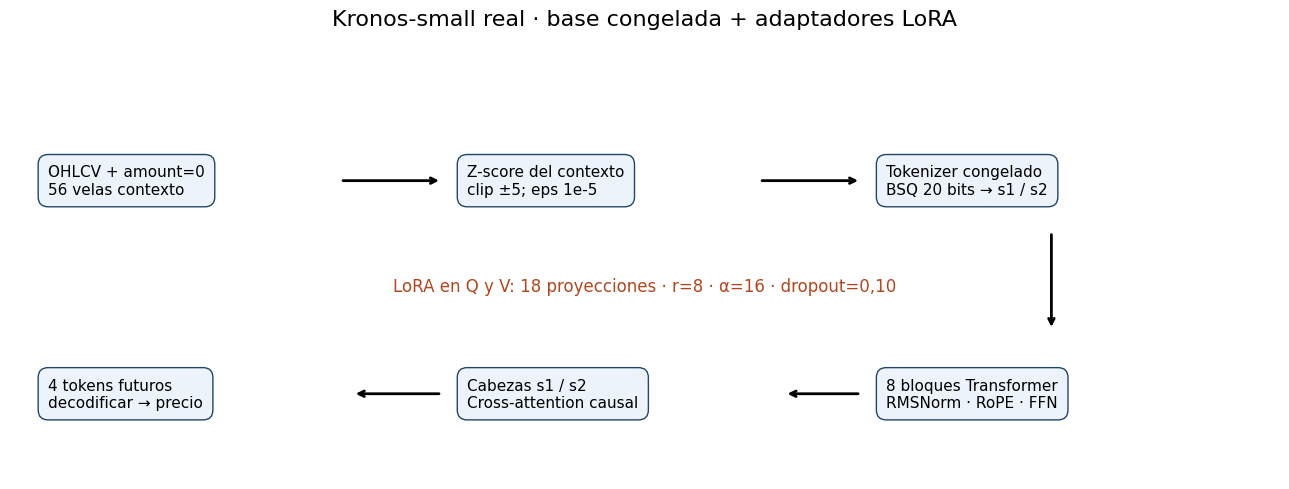

,valor
device,cuda
torch,2.14.1+cu130
python,3.13.16
threads,2
RAM_GiB,12.671406
RSS_GiB,0.624737
GPU,Tesla T4
eval_batch,8
profile,"[{'batch': 1, 'seconds_8_windows': 0.499763363..."
batch_max_price_delta,0.0


**Hardware:** CPU ya pasó la prueba funcional. T4 es la GPU mínima probada para este protocolo; L4/A100/H100 no se han medido. Escalar por lote/contexto/modelo mayores o tiempo insuficiente, midiendo primero. La GPU no demuestra mayor calidad predictiva. RAM es RSS muestreada y máximo del proceso; VRAM corresponde a memoria asignada por PyTorch, no a todo el driver.

PANELES_REALES_GUARDADOS 12


In [ ]:
#@title MISIÓN 05 · 11. Laboratorio visual: arquitectura, hardware y predicción
assert 'M5_ALL' in globals(), 'Ejecutar comparación y celda de réplicas primero'
# Panel A: inspección del modelo actualmente adaptado.
layer_rows=[]
for netname,net in [('predictor',m5_model),('tokenizer',m5_tok)]:
    for name,module in net.named_modules():
        pars=list(module.named_parameters(recurse=False))
        if pars: layer_rows.append({'network':netname,'module':name,'type':type(module).__name__,'shapes':str({k:list(p.shape) for k,p in pars}),'total':sum(p.numel() for _,p in pars),'trainable':sum(p.numel() for _,p in pars if p.requires_grad)})
M5_LAYERS=pd.DataFrame(layer_rows); M5_LAYERS.to_csv(M5_DIR/'auditoria/capas_finales.csv',index=False)
M5_COUNTS={'predictor_total':sum(p.numel() for p in m5_model.parameters()),'predictor_trainable':sum(p.numel() for p in m5_model.parameters() if p.requires_grad),'tokenizer_total':sum(p.numel() for p in m5_tok.parameters()),'tokenizer_trainable':sum(p.numel() for p in m5_tok.parameters() if p.requires_grad)}
display(pd.DataFrame([M5_COUNTS])); display(M5_LAYERS[M5_LAYERS.trainable>0])
fig,ax=plt.subplots(figsize=(13,5)); ax.axis('off')
boxes=[(.03,.70,'OHLCV + amount=0\n56 velas contexto'),(.36,.70,'Z-score del contexto\nclip ±5; eps 1e-5'),(.69,.70,'Tokenizer congelado\nBSQ 20 bits → s1 / s2'),(.69,.20,'8 bloques Transformer\nRMSNorm · RoPE · FFN'),(.36,.20,'Cabezas s1 / s2\nCross-attention causal'),(.03,.20,'4 tokens futuros\ndecodificar → precio')]
for x,y,label in boxes: ax.text(x,y,label,transform=ax.transAxes,ha='left',va='center',fontsize=11,bbox=dict(boxstyle='round,pad=.65',fc='#edf3fa',ec='#234666'))
for a,b in [((.26,.70),(.34,.70)),((.59,.70),(.67,.70)),((.82,.58),(.82,.35)),((.67,.20),(.61,.20)),((.34,.20),(.27,.20))]: ax.annotate('',xy=b,xytext=a,xycoords='axes fraction',arrowprops=dict(arrowstyle='->',lw=2))
ax.text(.5,.44,'LoRA en Q y V: 18 proyecciones · r=8 · α=16 · dropout=0,10',ha='center',transform=ax.transAxes,color='#b04720',fontsize=12)
ax.set_title('Kronos-small real · base congelada + adaptadores LoRA',fontsize=16,pad=20)
fig.tight_layout(); fig.savefig(M5_DIR/'graficas/arquitectura_lora.png',dpi=160,bbox_inches='tight'); display(fig); plt.close(fig)
parts=pd.DataFrame([{'module':n,'parameters':p.numel(),'state':'entrenable' if p.requires_grad else 'congelado','group':'.'.join(n.split('.')[:2])} for n,p in m5_model.named_parameters()])
summary=parts.groupby(['group','state'],as_index=False).parameters.sum()
m5_plot(px.bar(summary,x='group',y='parameters',color='state',title='Parámetros reales del predictor por módulo'),'parametros_modulo')
# Panel computacional: mediciones, no extrapolaciones de precisión entre GPU.
M5_HW_FINAL=dict(M5_HW)
M5_HW_FINAL.update({'train_steps':len(M5_HISTORY),'train_batch':1,'train_seconds':M5_TRAIN_RESULT['seconds_this_call'],'train_step_median_seconds':history_df.seconds.median(),'train_GPU_peak_GiB':history_df.GPU_peak_GiB.max(),'train_RSS_sampled_max_GiB':history_df.RSS_GiB.max(),'process_lifetime_max_RSS_GiB':M5_TRAIN_RESULT['process_lifetime_max_RSS_GiB'],'current_GPU_reserved_GiB':torch.cuda.memory_reserved()/2**30})
m5_json(M5_DIR/'auditoria/hardware_final.json',M5_HW_FINAL)
display(pd.DataFrame([M5_HW_FINAL]).T.rename(columns={0:'valor'}))
display(Markdown('**Hardware:** CPU ya pasó la prueba funcional. T4 es la GPU mínima probada para este protocolo; L4/A100/H100 no se han medido. Escalar por lote/contexto/modelo mayores o tiempo insuficiente, midiendo primero. La GPU no demuestra mayor calidad predictiva. RAM es RSS muestreada y máximo del proceso; VRAM corresponde a memoria asignada por PyTorch, no a todo el driver.'))
# Panel C: regla de selección de ejemplos independiente del error.
examples=[]
for year in [2020,2021,2022]:
    ids=m5_val_ix.index[(m5_val_ix.year==year)&(m5_val_ix.ny_hour=='08:30')]
    examples.append(int(ids[0]))
m5_json(M5_DIR/'auditoria/ejemplos_graficos.json',{'rule':'Primera ventana cronológica 08:30 NY de cada año; no elegida por error','ids':examples})
fig=make_subplots(rows=3,cols=1,subplot_titles=[str(m5_val_ix.iloc[i].decision_utc.tz_convert('America/New_York')) for i in examples])
colors={'Kronos_base':'#3264b0','LoRA_271828':'#d25b23','Persistencia':'#7f8c8d'}
for row,i in enumerate(examples,1):
    start=int(m5_val_ix.iloc[i].start_row); sample=m5_val[i]; context=m5_val.values[start:start+56,3]
    fig.add_trace(go.Scatter(x=list(range(-55,1)),y=context,name='Contexto real',line=dict(color='#222'),showlegend=row==1),row=row,col=1)
    fig.add_trace(go.Scatter(x=[0,1,2,3,4],y=[float(sample['last_close'])]+sample['truth'][:,3].tolist(),name='Futuro real',line=dict(color='#00a277',width=3),showlegend=row==1),row=row,col=1)
    for label,g in M5_COMPARISON[M5_COMPARISON.window==i].groupby('model'):
        g=g.sort_values('horizon'); fig.add_trace(go.Scatter(x=[0,1,2,3,4],y=[float(sample['last_close'])]+g.prediction.tolist(),name=label,mode='lines+markers',line=dict(color=colors[label],dash='dot' if label=='Persistencia' else 'solid'),showlegend=row==1),row=row,col=1)
    fig.add_vrect(x0=.01,x1=4.3,fillcolor='#ffe3b1',opacity=.25,line_width=0,row=row,col=1)
    fig.update_xaxes(title_text='Velas M15 desde decisión: contexto −55…0, horizonte 1…4',row=row,col=1)
    fig.update_yaxes(title_text='Precio XAUUSD',row=row,col=1)
fig.update_layout(height=1000,title='Contexto y futuro · ejemplos fijados por calendario',legend=dict(orientation='h',y=1.06))
m5_plot(fig,'prediccion_contexto_horizonte')
m5_plot(px.histogram(M5_COMPARISON,x='error',color='model',nbins=100,barmode='overlay',opacity=.5,title='Distribución completa de errores firmados: predicción − real'),'distribucion_errores')
m5_plot(px.line(m5_group_metrics(M5_COMPARISON,['model','horizon']),x='horizon',y='MAE',color='model',markers=True,title='MAE por horizonte · mismas observaciones'),'error_por_horizonte')
# Panel D: comparación completa y estabilidad temporal.
m5_plot(px.bar(M5_ALL_METRICS.melt(id_vars='model',value_vars=['MAE','RMSE'],var_name='metrica',value_name='error'),x='model',y='error',color='metrica',barmode='group',title='Modelos y semillas · 11880 predicciones por modelo'),'comparacion_global')
m5_plot(px.bar(m5_group_metrics(M5_ALL,['model','year']),x='year',y='MAE',color='model',barmode='group',title='MAE por año · 2020 incluye selección del checkpoint'),'comparacion_por_year')
m5_plot(px.line(m5_group_metrics(M5_COMPARISON,['model','ny_hour']),x='ny_hour',y='MAE',color='model',markers=True,title='MAE por hora de decisión Nueva York · DST verificado'),'comparacion_horas_NY')
dir_table=M5_ALL_METRICS.copy(); dir_table.loc[dir_table.direction_coverage_pct==0,'direction_accuracy_pct']=np.nan
m5_plot(px.bar(dir_table,x='model',y='direction_accuracy_pct',title='Acierto direccional sobre movimientos reales no nulos · persistencia se abstiene'),'precision_direccional')
daily=m5_group_metrics(M5_COMPARISON,['model','ny_date']); daily['MAE_20_sessions']=daily.groupby('model').MAE.transform(lambda x:x.rolling(20,min_periods=20).mean())
m5_plot(px.line(daily,x='ny_date',y='MAE_20_sessions',color='model',title='MAE medio por sesión · media móvil de 20 sesiones NY'),'estabilidad_temporal')
print('PANELES_REALES_GUARDADOS',len(list((M5_DIR/'graficas').glob('*'))))


In [ ]:
#@title MISIÓN 05 · 12. Integridad final, recarga y trazabilidad
assert len(M5_HISTORY)==M5_TRAIN_RESULT['completed_steps']<=1000
assert np.isfinite(history_df[['loss','gradient_norm','seconds','lr','GPU_peak_GiB','RSS_GiB']]).all().all()
assert m5_hash_state(m5_model,True)==M5_BASE_HASH and m5_hash_state(m5_tok)==M5_TOK_HASH
M5_SELECTED_ADAPTER=m5_adapter()
M5_DELTAS=pd.DataFrame([{'parameter':n,'changed':not torch.equal(M5_INIT[n],p),'delta_L2':float((p-M5_INIT[n]).norm()),'delta_max_abs':float((p-M5_INIT[n]).abs().max())} for n,p in M5_SELECTED_ADAPTER.items()])
M5_DELTAS.to_csv(M5_DIR/'auditoria/cambios_adaptadores.csv',index=False)
assert M5_DELTAS.changed.any()
M5_RELOAD_IDS=list(range(8))
with m5_eval_guard(): before=kp.rollout(m5_model,m5_tok,m5_batch(m5_val,M5_RELOAD_IDS),56,4).cpu()
m5_load_adapter(M5_INIT)
selected=torch.load(M5_TRAIN_RESULT['best_checkpoint'],map_location='cpu',weights_only=False)
m5_load_adapter(selected['adapter'])
with m5_eval_guard(): after=kp.rollout(m5_model,m5_tok,m5_batch(m5_val,M5_RELOAD_IDS),56,4).cpu()
assert torch.equal(before,after)
recorded=m5_lora[m5_lora.window.isin(M5_RELOAD_IDS)].sort_values(['window','horizon']).prediction.to_numpy().reshape(8,4)
assert np.array_equal(after[:,:,3].numpy(),recorded)
m5_enable(False)
with m5_eval_guard(): base_recomputed=kp.rollout(m5_model,m5_tok,m5_batch(m5_val,M5_RELOAD_IDS),56,4)[:,:,3].cpu().numpy()
m5_enable(True)
base_recorded=m5_base[m5_base.window.isin(M5_RELOAD_IDS)].sort_values(['window','horizon']).prediction.to_numpy().reshape(8,4)
assert np.array_equal(base_recomputed,base_recorded), 'Referencia recuperada debe reproducirse en la nueva T4'
assert all(m5_sha(M5_SOURCE/r['file'])==r['sha256'] for r in M5_MANIFEST)
M5_FINAL_AUDIT={'base_unchanged':m5_hash_state(m5_model,True)==M5_BASE_HASH,'tokenizer_unchanged':m5_hash_state(m5_tok)==M5_TOK_HASH,'source_files_hashes_verified':len(M5_MANIFEST),'adapter_tensors_changed':int(M5_DELTAS.changed.sum()),'adapter_tensors_total':len(M5_DELTAS),'reload_predictions_bit_identical':True,'saved_LoRA_predictions_bit_identical':True,'recovered_base_predictions_bit_identical':True,'reload_windows':8,'actual_training_resume':M5_REAL_RESUME,'causality':M5_CAUSAL,'test_2023_2024_read':False,'orders_enabled':False}
m5_json(M5_DIR/'auditoria/verificacion_final.json',M5_FINAL_AUDIT)
torch.save(M5_SELECTED_ADAPTER,M5_DIR/'checkpoints/adapter_selected_271828.pt')
m5_json(M5_DIR/'checkpoints/adapter_config.json',{'config':M5_CFG,'selected_step':M5_TRAIN_RESULT['best_step'],'base_hash':M5_BASE_HASH,'tokenizer_hash':M5_TOK_HASH,'trainable_names':list(M5_PARAMS)})
# Denominadores explícitos: un cambio verdadero nulo se excluye del acierto direccional.
den=[]
for label,g in M5_COMPARISON.groupby('model'):
    den.append({'model':label,'predictions':len(g),'actual_nonzero_moves':int((g.truth!=g.last_close).sum()),'actual_flat_moves':int((g.truth==g.last_close).sum()),'issued_nonzero_directions':int((g.prediction!=g.last_close).sum())})
M5_DENOMINATORS=pd.DataFrame(den); M5_DENOMINATORS.to_csv(M5_DIR/'metricas/denominadores_direccion.csv',index=False)
display(M5_DELTAS); display(M5_DENOMINATORS)
print('AUDITORIA_FINAL_SUPERADA',json.dumps(M5_FINAL_AUDIT))
print('CHECKPOINT_SELECCIONADO',M5_TRAIN_RESULT['best_checkpoint'])


,parameter,changed,delta_L2,delta_max_abs
0,transformer.0.self_attn.q_proj.lora_A,True,0.859960,0.045073
1,transformer.0.self_attn.q_proj.lora_B,True,0.586947,0.031070
2,transformer.0.self_attn.v_proj.lora_A,True,1.833214,0.051786
3,transformer.0.self_attn.v_proj.lora_B,True,1.019694,0.047491
4,transformer.1.self_attn.q_proj.lora_A,True,1.200957,0.045453
5,transformer.1.self_attn.q_proj.lora_B,True,0.698280,0.039095
6,transformer.1.self_attn.v_proj.lora_A,True,2.251901,0.061793
7,transformer.1.self_attn.v_proj.lora_B,True,1.123501,0.056047
8,transformer.2.self_attn.q_proj.lora_A,True,1.152440,0.051221
9,transformer.2.self_attn.q_proj.lora_B,True,0.617945,0.035529


,model,predictions,actual_nonzero_moves,actual_flat_moves,issued_nonzero_directions
0,Kronos_base,11880,11870,10,11877
1,LoRA_271828,11880,11870,10,11880
2,Persistencia,11880,11870,10,0


AUDITORIA_FINAL_SUPERADA {"base_unchanged": true, "tokenizer_unchanged": true, "source_files_hashes_verified": 13, "adapter_tensors_changed": 36, "adapter_tensors_total": 36, "reload_predictions_bit_identical": true, "saved_LoRA_predictions_bit_identical": true, "recovered_base_predictions_bit_identical": true, "reload_windows": 8, "actual_training_resume": {"from_step": 475, "to_step": 500, "losses_identical": true, "adapters_identical": true, "optimizer_identical": true, "rng_identical": true}, "causality": {"loss_active_indices": [55, 56, 57, 58], "normalization_future_invariant": true, "tokenizer_future_and_prefix_invariant": true, "predictor_causal_eval": [0.0, 0.0], "predictor_causal_train": [0.0, 0.0], "rollout_future_invariant": true, "tokenizer_frozen": true}, "test_2023_2024_read": false, "orders_enabled": false}
CHECKPOINT_SELECCIONADO /content/drive/MyDrive/AXXEL_CAPITAL/MISION05_LORA/20261112T130149Z_80e373/continuacion_20261113T203705Z_d2f8d8/checkpoints/seed_271828/step_

In [ ]:
#@title AXXEL CAPITAL — KRONOS LoRA | INFORME DE RESULTADOS
assert all(M5_FINAL_AUDIT[k] for k in ['base_unchanged','tokenizer_unchanged','reload_predictions_bit_identical','saved_LoRA_predictions_bit_identical','recovered_base_predictions_bit_identical'])
mt=M5_METRICS.set_index('model'); lo=mt.loc['LoRA_271828']; ba=mt.loc['Kronos_base']; pe=mt.loc['Persistencia']
mae_delta_pct=(lo.MAE/ba.MAE-1)*100; ce_change_pct=(M5_TRAIN_RESULT['best_validation_CE']/M5_TRAIN_RESULT['initial_validation_CE']-1)*100
M5_VERDICT='VIABLE_TECNICAMENTE_SIN_MEJORA_PREDICTIVA' if lo.MAE>=ba.MAE else 'VIABLE_TECNICAMENTE_MEJORA_EXPLORATORIA_PENDIENTE_VALIDACION'
M5_REPORT_SUMMARY={'status':M5_VERDICT,'run_directory':str(M5_DIR),'training':M5_TRAIN_RESULT,'metrics':M5_METRICS.to_dict('records'),'temporal_metrics':M5_TEMPORAL.to_dict('records'),'paired_CI':M5_CI.to_dict('records'),'hardware':M5_HW_FINAL,'parameter_counts':M5_COUNTS,'integrity':M5_FINAL_AUDIT,'replication_triggered':M5_REPLICATE,'replicas':M5_REPLICA_RESULTS,'test_reserved':'2023-2024','trading_enabled':False}
m5_json(M5_DIR/'informes/resultados.json',M5_REPORT_SUMMARY)
compact=M5_METRICS[['model','MAE','RMSE','direction_accuracy_pct','n_predictions','n_windows','n_days']].copy()
compact.loc[compact.model=='Persistencia','direction_accuracy_pct']=np.nan
conclusion=('No pasar todavía a un entrenamiento completo. La pérdida de tokens mejoró, pero MAE y RMSE empeoraron frente al modelo base y persistencia. Primero investigar, con un protocolo nuevo y datos de desarrollo, la relación entre pérdida de tokens, decodificación y error de precio. No elegir retrospectivamente otro checkpoint por esta evaluación ni abrir el test para corregir el resultado.' if lo.MAE>=ba.MAE else 'La mejora es exploratoria: revisar réplicas y estabilidad antes de plantear un protocolo final independiente. El test permanece reservado; no se demuestra rentabilidad.')
M5_REPORT=f'''# AXXEL CAPITAL — KRONOS LoRA | INFORME DE RESULTADOS

**Misión 05 · ejecución real en el cuaderno principal · 13 de noviembre de 2026**
**Estado: {M5_VERDICT}. Investigación exclusivamente; órdenes desactivadas.**

## 1. Arquitectura verificada
NeoQuasar/Kronos-small, commit oficial **{kp.COMMIT}**, revisiones de pesos fijadas en protocolo.json. Tokenizador Kronos-Tokenizer-base (no Amazon Chronos): BSQ de 20 bits dividido en dos subcódigos de 10 bits. El predictor tiene 8 bloques Transformer, dimensión 512, atención RoPE, RMSNorm y feed-forward; las dimensiones exactas de todas las capas se guardan en capas_finales.csv.

OHLCV + amount constante cero → normalización calculada solo con las 56 velas del contexto → tokenizer congelado → predicción autoregresiva s1/s2 → decoder del tokenizer → desnormalización de 4 velas futuras. Se inspeccionaron realmente 18 proyecciones Q/V compatibles con LoRA. La implementación incluye la corrección de atención cruzada causal tanto en entrenamiento como evaluación y decodificación greedy alineada. **Kronos_base** significa pesos originales bajo esa misma implementación corregida; no es una comparación con el predictor estocástico oficial sin modificaciones.

## 2. Configuración LoRA
Rank 8, alpha 16 (escala 2), dropout 0,10; AdamW, LR 0,0001 constante, weight decay 0,01; clip de gradiente 1,0; float32; lote train 1; evaluación {M5_EVAL_BATCH}; L=56, H=4. Semilla 271828. Se partió de adaptadores neutros iniciales de M04, no de su checkpoint de tres pasos. Pruebas y replay se descartan antes de seleccionar el resultado principal.

## 3. Hardware empleado
**{M5_HW['GPU']}**, {M5_HW['GPU_total_GiB']:.3f} GiB GPU, {M5_HW['RAM_GiB']:.3f} GiB RAM. Entrenamiento completo de este presupuesto: **{M5_TRAIN_RESULT['seconds_this_call']:.2f} s**; mediana {M5_HW_FINAL['train_step_median_seconds']:.4f} s/paso. Pico train de memoria GPU asignada por PyTorch: **{M5_HW_FINAL['train_GPU_peak_GiB']:.4f} GiB**. RSS máxima del proceso: {M5_HW_FINAL['process_lifetime_max_RSS_GiB']:.3f} GiB. Estas métricas no incluyen toda la memoria del driver; RSS por paso es muestreada.

CPU pasó previamente causalidad, gradientes y reanudación; ocho ventanas tardaron 2,1882 s con lote 1. T4 con lote 8 tardó {M5_HW['profile'][1]['seconds_8_windows']:.4f} s en el perfil actual. La referencia completa original tardó aproximadamente 30,43 s; al recuperarla se leyeron resultados de Drive, por lo que el tiempo de caché no representa inferencia. **Mínimo funcional probado: CPU; GPU mínima probada y suficiente para este protocolo: T4.** L4, A100 y H100 no fueron medidas. Escalar si perfiles de lotes/contextos/modelos mayores exceden el presupuesto de tiempo o memoria; como margen operativo propuesto, conservar 20% de VRAM libre ({.8*M5_HW['GPU_total_GiB']:.2f} GiB asignados como umbral orientativo en esta T4). Una GPU mayor no demuestra mejor predicción.

## 4. Parámetros
Predictor base congelado: **24.741.376**. Adaptadores entrenables: **{M5_COUNTS['predictor_trainable']:,}**. Predictor con LoRA: **{M5_COUNTS['predictor_total']:,}**; fracción entrenable {100*M5_COUNTS['predictor_trainable']/M5_COUNTS['predictor_total']:.4f}%. Tokenizador: **{M5_COUNTS['tokenizer_total']:,}**, todos congelados. Cambiaron {M5_FINAL_AUDIT['adapter_tensors_changed']} de {M5_FINAL_AUDIT['adapter_tensors_total']} tensores de adaptadores; pesos originales y tokenizer conservaron sus hashes exactos.

## 5. Piloto y entrenamiento controlado
La prueba funcional inicial de cuatro pasos continuos frente a 2 + guardar/cargar + 2 pasó con pérdidas, pesos, AdamW y RNG idénticos. El entrenamiento principal ejecutó **{M5_TRAIN_RESULT['completed_steps']} pasos**, una sola pasada parcial de ventanas distintas de 2010–2019, sin múltiples épocas. Checkpoints cada 25 pasos; validación cada 100 sobre 128 ventanas fijas de 2020, seleccionadas antes de optimizar. Mejor checkpoint por CE: **paso {M5_TRAIN_RESULT['best_step']}**. CE inicial {M5_TRAIN_RESULT['initial_validation_CE']:.6f} → {M5_TRAIN_RESULT['best_validation_CE']:.6f} ({ce_change_pct:.2f}%). Parada: {M5_TRAIN_RESULT['stop_reason']}.

Se reanudó además el checkpoint real del paso {M5_REAL_RESUME['from_step']} y se reprodujo hasta {M5_REAL_RESUME['to_step']}: pérdidas, adaptadores, optimizador y RNG idénticos. La recarga del checkpoint seleccionado reprodujo bit a bit ocho ventanas y coincidió con las predicciones guardadas. La referencia recuperada también reprodujo esas ocho ventanas bit a bit en el nuevo runtime.

## 6. Gráficas de entrenamiento
La celda SFT contiene seis paneles reales: pérdida train, CE de validación, norma de gradientes, memoria GPU, segundos por paso y learning rate. La pérdida train corresponde a ventanas diferentes, por lo que no se interpreta como una curva sobre la misma muestra. Los registros exactos de cada paso están en train_seed_271828.csv y validation_seed_271828.csv.

## 7. Predicciones y comparación
**2.970 ventanas / 11.880 cierres por modelo / 754 sesiones NY**, 2020–2022. Cuatro anclas de decisión: 08:30, 09:30, 10:30 y 11:30 America/New_York, con DST verificado. Son todas las ventanas válidas de ese índice de cuatro anclas, no todas las velas de la sesión. Horizonte 1–4, mismos targets y contexto para todos los modelos. Unidades de MAE/RMSE: precio XAUUSD, no pips ni retorno.

{compact.to_markdown(index=False,floatfmt='.6f')}

El MAE LoRA frente a base cambió **{mae_delta_pct:+.2f}%**. Persistencia repite el último cierre; no emite dirección. Su acierto direccional condicional es indefinido, no un sistema con 0% de capacidad predictiva. La precisión direccional excluye movimientos reales nulos; denominadores y cobertura están guardados por separado.

## 8. Estabilidad y comparación pareada
2021–2022 se evaluó por separado y no se utilizó para elegir el checkpoint en M05; M04 ya había examinado 16 ventanas de esos años. Las tablas por año, horizonte, hora NY y año/hora están guardadas. Las gráficas incluyen contexto de 56 velas, futuro, distribución completa de errores y media móvil de error por sesión. Los ejemplos se eligen por calendario (primera ventana 08:30 NY de cada año), nunca por su error.

{M5_CI.to_markdown(index=False,floatfmt='.6f')}

Delta MAE = LoRA menos referencia; positivo significa peor. Bootstrap exploratorio pareado, 2.000 remuestreos, bloques de cinco sesiones NY: reconoce dependencia intradía y entre sesiones cercanas, pero no elimina sesgo por selección, cambios de régimen ni incertidumbre de preentrenamiento. **Réplicas activadas: {M5_REPLICATE}**. La regla previa requería mejora de MAE frente a base tanto global como en 2021–2022; no se cambió tras ver los resultados.

## 9. Errores y limitaciones
Los runtimes se reiniciaron; la recuperación se documentó sin rehacer la auditoría M1 ni sobrescribir artefactos históricos. Todos los 13 archivos fuente 2010–2022 conservaron sus hashes. Reconstrucción M1→M15 y volumen agregados coinciden numéricamente; la unidad económica del volumen del proveedor sigue sin certificar y amount no está observado (entrada cero explícita). La evaluación usa float32 y greedy; no mide incertidumbre de trayectorias. Una sola semilla principal, presupuesto de 1.000 pasos y selección por CE no bastan para entrenamiento estadísticamente concluyente.

Los splits son cronológicos; normalización y tokenización pasaron invariancia al futuro. **Test 2023–2024 no leído ni utilizado en M05.** No se puede certificar ausencia de solapamiento con los datos originales de preentrenamiento de Kronos. No se calcularon beneficio, costes, spread, ejecución ni rentabilidad. No se ajustaron hiperparámetros con el test.

## 10. Conclusión y reproducción
{conclusion}

La integración LoRA, congelación, gradientes, estabilidad numérica, persistencia de checkpoints y reanudación exacta quedaron demostradas bajo las versiones y hardware registrados. Esto demuestra viabilidad técnica, no ventaja de trading.

**Artefactos:** {M5_DIR}

**Checkpoint elegido:** {M5_TRAIN_RESULT['best_checkpoint']}

**Reproducir una nueva ejecución:** en este mismo cuaderno, ejecutar «Recuperar T4 y referencias verificadas» (crea carpeta nueva), «8. SFT LoRA controlado», «9. Evaluación pareada», «10. Réplicas», «11. Laboratorio visual», «12. Integridad final» y este informe, en ese orden. No ejecutar todas las secciones históricas para reproducir M05. El protocolo, código vendorizado, versiones, índices, hashes, métricas, adaptadores y RNG están conservados. El checkpoint seleccionado contiene el estado AdamW completo; la función m5_restore verifica identidad y orden antes de recuperar el cursor. La reanudación bit a bit está certificada en la misma configuración T4/torch registrada, no entre dispositivos diferentes.
'''
(M5_DIR/'informes/INFORME_RESULTADOS.md').write_text(M5_REPORT,encoding='utf-8')
import html
(M5_DIR/'informes/INFORME_RESULTADOS.html').write_text('<!doctype html><html lang="es"><meta charset="utf-8"><title>AXXEL CAPITAL · Resultados LoRA</title><style>body{max-width:1100px;margin:40px auto;font:16px system-ui;line-height:1.55}pre{white-space:pre-wrap}table{border-collapse:collapse}td,th{padding:8px;border:1px solid #ddd}</style><h1>AXXEL CAPITAL — KRONOS LoRA</h1>'+compact.to_html(index=False)+ '<pre>'+html.escape(M5_REPORT)+'</pre></html>',encoding='utf-8')
# Snapshot previo al cierre; el cuaderno principal guardado conserva también la salida de este informe.
nb_final=_message.blocking_request('get_ipynb',timeout_sec=30)['ipynb']
m5_json(M5_DIR/'auditoria/cuaderno_pre_cierre.ipynb',nb_final)
manifest=[]
for p in sorted(M5_DIR.rglob('*')):
    if p.is_file() and p.name!='manifest_sha256.csv': manifest.append({'file':str(p.relative_to(M5_DIR)),'bytes':p.stat().st_size,'sha256':m5_sha(p)})
pd.DataFrame(manifest).to_csv(M5_DIR/'auditoria/manifest_sha256.csv',index=False)
display(Markdown(M5_REPORT))
print('ENTREGA_M05_VERIFICADA',len(manifest),'artefactos',M5_DIR)


# AXXEL CAPITAL — KRONOS LoRA | INFORME DE RESULTADOS

**Misión 05 · ejecución real en el cuaderno principal · 13 de noviembre de 2026**  
**Estado: VIABLE_TECNICAMENTE_SIN_MEJORA_PREDICTIVA. Investigación exclusivamente; órdenes desactivadas.**

## 1. Arquitectura verificada
NeoQuasar/Kronos-small, commit oficial **67b630e67f6a18c9e9be918d9b4337c960db1e9a**, revisiones de pesos fijadas en protocolo.json. Tokenizador Kronos-Tokenizer-base (no Amazon Chronos): BSQ de 20 bits dividido en dos subcódigos de 10 bits. El predictor tiene 8 bloques Transformer, dimensión 512, atención RoPE, RMSNorm y feed-forward; las dimensiones exactas de todas las capas se guardan en capas_finales.csv.

OHLCV + amount constante cero → normalización calculada solo con las 56 velas del contexto → tokenizer congelado → predicción autoregresiva s1/s2 → decoder del tokenizer → desnormalización de 4 velas futuras. Se inspeccionaron realmente 18 proyecciones Q/V compatibles con LoRA. La implementación incluye la corrección de atención cruzada causal tanto en entrenamiento como evaluación y decodificación greedy alineada. **Kronos_base** significa pesos originales bajo esa misma implementación corregida; no es una comparación con el predictor estocástico oficial sin modificaciones.

## 2. Configuración LoRA
Rank 8, alpha 16 (escala 2), dropout 0,10; AdamW, LR 0,0001 constante, weight decay 0,01; clip de gradiente 1,0; float32; lote train 1; evaluación 8; L=56, H=4. Semilla 271828. Se partió de adaptadores neutros iniciales de M04, no de su checkpoint de tres pasos. Pruebas y replay se descartan antes de seleccionar el resultado principal.

## 3. Hardware empleado
**Tesla T4**, 14.563 GiB GPU, 12.671 GiB RAM. Entrenamiento completo de este presupuesto: **83.36 s**; mediana 0.0510 s/paso. Pico train de memoria GPU asignada por PyTorch: **0.1890 GiB**. RSS máxima del proceso: 1.922 GiB. Estas métricas no incluyen toda la memoria del driver; RSS por paso es muestreada.

CPU pasó previamente causalidad, gradientes y reanudación; ocho ventanas tardaron 2,1882 s con lote 1. T4 con lote 8 tardó 0.0699 s en el perfil actual. La referencia completa original tardó aproximadamente 30,43 s; al recuperarla se leyeron resultados de Drive, por lo que el tiempo de caché no representa inferencia. **Mínimo funcional probado: CPU; GPU mínima probada y suficiente para este protocolo: T4.** L4, A100 y H100 no fueron medidas. Escalar si perfiles de lotes/contextos/modelos mayores exceden el presupuesto de tiempo o memoria; como margen operativo propuesto, conservar 20% de VRAM libre (11.65 GiB asignados como umbral orientativo en esta T4). Una GPU mayor no demuestra mejor predicción.

## 4. Parámetros
Predictor base congelado: **24.741.376**. Adaptadores entrenables: **147,456**. Predictor con LoRA: **24,888,832**; fracción entrenable 0.5925%. Tokenizador: **3,958,042**, todos congelados. Cambiaron 36 de 36 tensores de adaptadores; pesos originales y tokenizer conservaron sus hashes exactos.

## 5. Piloto y entrenamiento controlado
La prueba funcional inicial de cuatro pasos continuos frente a 2 + guardar/cargar + 2 pasó con pérdidas, pesos, AdamW y RNG idénticos. El entrenamiento principal ejecutó **1000 pasos**, una sola pasada parcial de ventanas distintas de 2010–2019, sin múltiples épocas. Checkpoints cada 25 pasos; validación cada 100 sobre 128 ventanas fijas de 2020, seleccionadas antes de optimizar. Mejor checkpoint por CE: **paso 1000**. CE inicial 3.964052 → 3.565331 (-10.06%). Parada: budget_1000_steps.

Se reanudó además el checkpoint real del paso 475 y se reprodujo hasta 500: pérdidas, adaptadores, optimizador y RNG idénticos. La recarga del checkpoint seleccionado reprodujo bit a bit ocho ventanas y coincidió con las predicciones guardadas. La referencia recuperada también reprodujo esas ocho ventanas bit a bit en el nuevo runtime.

## 6. Gráficas de entrenamiento
La celda SFT contiene seis paneles reales: pérdida train, CE de validación, norma de gradientes, memoria GPU, segundos por paso y learning rate. La pérdida train corresponde a ventanas diferentes, por lo que no se interpreta como una curva sobre la misma muestra. Los registros exactos de cada paso están en train_seed_271828.csv y validation_seed_271828.csv.

## 7. Predicciones y comparación
**2.970 ventanas / 11.880 cierres por modelo / 754 sesiones NY**, 2020–2022. Cuatro anclas de decisión: 08:30, 09:30, 10:30 y 11:30 America/New_York, con DST verificado. Son todas las ventanas válidas de ese índice de cuatro anclas, no todas las velas de la sesión. Horizonte 1–4, mismos targets y contexto para todos los modelos. Unidades de MAE/RMSE: precio XAUUSD, no pips ni retorno.

| model        |      MAE |     RMSE |   direction_accuracy_pct |   n_predictions |   n_windows |   n_days |
|:-------------|---------:|---------:|-------------------------:|----------------:|------------:|---------:|
| Kronos_base  | 3.430783 | 5.064705 |                50.286436 |           11880 |        2970 |      754 |
| LoRA_271828  | 3.660541 | 5.316730 |                50.210615 |           11880 |        2970 |      754 |
| Persistencia | 3.193094 | 4.790961 |               nan        |           11880 |        2970 |      754 |

El MAE LoRA frente a base cambió **+6.70%**. Persistencia repite el último cierre; no emite dirección. Su acierto direccional condicional es indefinido, no un sistema con 0% de capacidad predictiva. La precisión direccional excluye movimientos reales nulos; denominadores y cobertura están guardados por separado.

## 8. Estabilidad y comparación pareada
2021–2022 se evaluó por separado y no se utilizó para elegir el checkpoint en M05; M04 ya había examinado 16 ventanas de esos años. Las tablas por año, horizonte, hora NY y año/hora están guardadas. Las gráficas incluyen contexto de 56 velas, futuro, distribución completa de errores y media móvil de error por sesión. Los ejemplos se eligen por calendario (primera ventana 08:30 NY de cada año), nunca por su error.

| scope     | candidate   | reference    |   delta_MAE |   CI95_low |   CI95_high |   n_days |   n_predictions |   bootstrap_replicates |   block_sessions |
|:----------|:------------|:-------------|------------:|-----------:|------------:|---------:|----------------:|-----------------------:|-----------------:|
| 2020-2022 | LoRA_271828 | Kronos_base  |    0.229759 |   0.178688 |    0.280838 |      754 |           11880 |                   2000 |                5 |
| 2020-2022 | LoRA_271828 | Persistencia |    0.467448 |   0.407726 |    0.527841 |      754 |           11880 |                   2000 |                5 |
| 2021-2022 | LoRA_271828 | Kronos_base  |    0.229959 |   0.177340 |    0.285343 |      511 |            8080 |                   2000 |                5 |
| 2021-2022 | LoRA_271828 | Persistencia |    0.456266 |   0.388593 |    0.524956 |      511 |            8080 |                   2000 |                5 |

Delta MAE = LoRA menos referencia; positivo significa peor. Bootstrap exploratorio pareado, 2.000 remuestreos, bloques de cinco sesiones NY: reconoce dependencia intradía y entre sesiones cercanas, pero no elimina sesgo por selección, cambios de régimen ni incertidumbre de preentrenamiento. **Réplicas activadas: False**. La regla previa requería mejora de MAE frente a base tanto global como en 2021–2022; no se cambió tras ver los resultados.

## 9. Errores y limitaciones
Los runtimes se reiniciaron; la recuperación se documentó sin rehacer la auditoría M1 ni sobrescribir artefactos históricos. Todos los 13 archivos fuente 2010–2022 conservaron sus hashes. Reconstrucción M1→M15 y volumen agregados coinciden numéricamente; la unidad económica del volumen del proveedor sigue sin certificar y amount no está observado (entrada cero explícita). La evaluación usa float32 y greedy; no mide incertidumbre de trayectorias. Una sola semilla principal, presupuesto de 1.000 pasos y selección por CE no bastan para entrenamiento estadísticamente concluyente.

Los splits son cronológicos; normalización y tokenización pasaron invariancia al futuro. **Test 2023–2024 no leído ni utilizado en M05.** No se puede certificar ausencia de solapamiento con los datos originales de preentrenamiento de Kronos. No se calcularon beneficio, costes, spread, ejecución ni rentabilidad. No se ajustaron hiperparámetros con el test.

## 10. Conclusión y reproducción
No pasar todavía a un entrenamiento completo. La pérdida de tokens mejoró, pero MAE y RMSE empeoraron frente al modelo base y persistencia. Primero investigar, con un protocolo nuevo y datos de desarrollo, la relación entre pérdida de tokens, decodificación y error de precio. No elegir retrospectivamente otro checkpoint por esta evaluación ni abrir el test para corregir el resultado.

La integración LoRA, congelación, gradientes, estabilidad numérica, persistencia de checkpoints y reanudación exacta quedaron demostradas bajo las versiones y hardware registrados. Esto demuestra viabilidad técnica, no ventaja de trading.

**Artefactos:** /content/drive/MyDrive/AXXEL_CAPITAL/MISION05_LORA/20261112T130149Z_80e373/continuacion_20261113T203705Z_d2f8d8

**Checkpoint elegido:** /content/drive/MyDrive/AXXEL_CAPITAL/MISION05_LORA/20261112T130149Z_80e373/continuacion_20261113T203705Z_d2f8d8/checkpoints/seed_271828/step_1000.pt

**Reproducir una nueva ejecución:** en este mismo cuaderno, ejecutar «Recuperar T4 y referencias verificadas» (crea carpeta nueva), «8. SFT LoRA controlado», «9. Evaluación pareada», «10. Réplicas», «11. Laboratorio visual», «12. Integridad final» y este informe, en ese orden. No ejecutar todas las secciones históricas para reproducir M05. El protocolo, código vendorizado, versiones, índices, hashes, métricas, adaptadores y RNG están conservados. El checkpoint seleccionado contiene el estado AdamW completo; la función m5_restore verifica identidad y orden antes de recuperar el cursor. La reanudación bit a bit está certificada en la misma configuración T4/torch registrada, no entre dispositivos diferentes.


ENTREGA_M05_VERIFICADA 162 artefactos /content/drive/MyDrive/AXXEL_CAPITAL/MISION05_LORA/20261112T130149Z_80e373/continuacion_20261113T203705Z_d2f8d8


# MISIÓN 06 · Diagnóstico causal y alineación predictiva

**Estado: preparación inicial; experimentos M06 no ejecutados.**

Train 2010–2019 · Desarrollo 2020 · L=56 · H=4 · RESEARCH ONLY · ORDERS DISABLED.

Ejecutar solo esta sección. **No ejecutar las recuperaciones de M05 ni «Ejecutar todas»**:
las celdas históricas cargan también 2021–2022. Sus resultados y checkpoints se conservan.

Primero ejecutar M06 · 0 y revisar el hardware y la procedencia. Después M06 · 1
construye un índice independiente de los archivos permitidos. Las fases I–VI aún
requieren implementación, ejecución y verificación en este mismo cuaderno.


In [ ]:
#@title MISIÓN 06 · 0. Estado real del runtime y procedencia (sin entrenamiento)
# Ejecutar esta sección solamente: las recuperaciones históricas de M05 cargan 2021–2022.
import sys, os, json, hashlib, platform, uuid, importlib.metadata as m6_metadata
from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display, Markdown

if 'google.colab' not in sys.modules:
    import importlib.util
    if importlib.util.find_spec('google.colab') is None:
        raise RuntimeError('M06 debe ejecutarse en el cuaderno principal de Google Colab.')

import torch
from google.colab import drive, _message
M6_BASE = Path('/content/drive/MyDrive/AXXEL_CAPITAL')
M6_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
M6_HW = {
    'observed_at_utc': datetime.now(timezone.utc).isoformat(),
    'python': platform.python_version(), 'torch': torch.__version__,
    'cuda_build': torch.version.cuda, 'cuda_available': torch.cuda.is_available(),
    'device': str(M6_DEVICE), 'cpu_count': os.cpu_count(),
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    'gpu_total_GiB': torch.cuda.get_device_properties(0).total_memory / 2**30 if torch.cuda.is_available() else None,
}
if torch.cuda.is_available():
    free, total = torch.cuda.mem_get_info()
    M6_HW.update(gpu_free_GiB=free / 2**30, gpu_allocated_GiB=torch.cuda.memory_allocated() / 2**30)
try:
    import psutil
    M6_HW.update(ram_total_GiB=psutil.virtual_memory().total / 2**30,
                 ram_available_GiB=psutil.virtual_memory().available / 2**30)
except ImportError:
    M6_HW['ram_measurement'] = 'psutil no instalado; no se infiere memoria'
print(json.dumps(M6_HW, indent=2))

if not Path('/content/drive/MyDrive').exists():
    drive.mount('/content/drive')
if not M6_BASE.is_dir():
    raise FileNotFoundError(M6_BASE)
M6_RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
M6_DIR = M6_BASE / 'MISION06_ALINEACION' / M6_RUN_ID
M6_DIR.mkdir(parents=True, exist_ok=False)
for sub in ['auditoria', 'configuraciones', 'metricas', 'graficas', 'checkpoints', 'informes']:
    (M6_DIR / sub).mkdir()

def m6_json(relative, value):
    target = (M6_DIR / relative).resolve()
    if M6_DIR.resolve() not in target.parents:
        raise ValueError('Escritura fuera de la ejecución M06')
    # Cada ejecución es nueva; no sobrescribir archivos ni artefactos históricos.
    with target.open('x', encoding='utf-8') as f:
        json.dump(value, f, ensure_ascii=False, indent=2, default=str, allow_nan=False)

def m6_sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

m6_json('auditoria/hardware_inicial.json', M6_HW)
M6_VERSIONS = {}
for package in ['torch', 'numpy', 'pandas', 'pyarrow', 'safetensors', 'huggingface_hub', 'einops', 'matplotlib', 'scipy', 'scikit-learn']:
    try:
        M6_VERSIONS[package] = m6_metadata.version(package)
    except m6_metadata.PackageNotFoundError:
        M6_VERSIONS[package] = None
m6_json('auditoria/versiones.json', M6_VERSIONS)
M6_HIST = M6_BASE / 'Kronos_SFT_verificado_20261107/ejecuciones/20261112T022707Z_55c83b'
M6_M05 = M6_BASE / 'MISION05_LORA/20261112T130149Z_80e373/continuacion_20261113T203705Z_d2f8d8'
M6_CHECKPOINT = M6_M05 / 'checkpoints/seed_271828/step_1000.pt'
M6_FILES = [M6_HIST / 'kronos_pipeline.py', M6_HIST / 'vendor/model/kronos.py',
            M6_HIST / 'vendor/model/module.py', M6_CHECKPOINT]
M6_PROVENANCE = []
for path in M6_FILES:
    if not path.is_file():
        m6_json('auditoria/bloqueo_procedencia.json', {'missing': str(path), 'experiments_executed': False})
        raise FileNotFoundError(path)
    M6_PROVENANCE.append({'path': str(path), 'bytes': path.stat().st_size, 'sha256': m6_sha(path)})
assert M6_PROVENANCE[0]['sha256'] == '1424fb451942c7e1e1823808405f428283f9b1aacf7b34d08df7ca9edb503016'
m6_json('auditoria/procedencia.json', M6_PROVENANCE)
M6_POLICY = {'L': 56, 'H': 4, 'seed': 271828, 'train_years': list(range(2010, 2020)),
             'development_years': [2020], 'allowed_source_years': list(range(2010, 2021)),
             'ny_anchors': ['08:30', '09:30', '10:30', '11:30'],
             'normalization': 'float32; solo contexto; std(ddof=0)+1e-5; clip [-5,5]',
             'research_only': True, 'orders_enabled': False,
             'historical_M05_artifacts': 'read_only', 'status': 'PREFLIGHT_ONLY'}
m6_json('configuraciones/politica.json', M6_POLICY)
# Copia de recuperación dentro de M06; no es un cuaderno de trabajo alternativo.
try:
    m6_json('auditoria/notebook_al_inicio.ipynb', _message.blocking_request('get_ipynb', timeout_sec=30)['ipynb'])
except Exception as exc:
    m6_json('auditoria/respaldo_no_disponible.json', {'error_type': type(exc).__name__, 'error': str(exc)})
M6_PREFLIGHT_OK = True
display(Markdown('**M06: diagnóstico inicial ejecutado.** No se han cargado datasets ni entrenado modelos.'))
print('EJECUCION_M06', M6_DIR)
print('VERSIONES', M6_VERSIONS)
print('CHECKPOINT_IDENTIFICADO_Y_HASH_CALCULADO', M6_CHECKPOINT)
print('GPU mayor no solicitada. Las fases predictivas siguen pendientes.')


{
  "observed_at_utc": "2026-11-14T22:24:39.097110+00:00",
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "cuda_build": "13.0",
  "cuda_available": true,
  "device": "cuda",
  "cpu_count": 2,
  "gpu": "Tesla T4",
  "gpu_total_GiB": 14.56317138671875,
  "gpu_free_GiB": 14.46075439453125,
  "gpu_allocated_GiB": 0.0,
  "ram_total_GiB": 12.671405792236328,
  "ram_available_GiB": 10.3187255859375
}
Mounted at /content/drive


**M06: diagnóstico inicial ejecutado.** No se han cargado datasets ni entrenado modelos.

EJECUCION_M06 /content/drive/MyDrive/AXXEL_CAPITAL/MISION06_ALINEACION/20261114T222455Z_32d5e571
VERSIONES {'torch': '2.14.1+cu130', 'numpy': '2.4.6', 'pandas': '2.2.3', 'pyarrow': '23.0.1', 'safetensors': '0.8.0', 'huggingface_hub': '1.33.0', 'einops': '0.8.2', 'matplotlib': '3.10.0', 'scipy': '1.16.3', 'scikit-learn': '1.6.1'}
CHECKPOINT_IDENTIFICADO_Y_HASH_CALCULADO /content/drive/MyDrive/AXXEL_CAPITAL/MISION05_LORA/20261112T130149Z_80e373/continuacion_20261113T203705Z_d2f8d8/checkpoints/seed_271828/step_1000.pt
GPU mayor no solicitada. Las fases predictivas siguen pendientes.


In [ ]:
#@title MISIÓN 06 · 1. Datos autorizados, índice nuevo y normalización causal
assert globals().get('M6_PREFLIGHT_OK') is True, 'Ejecutar primero M06 · 0'
import numpy as np
import pandas as pd

M6_SOURCE = M6_BASE / 'datasets/processed/kronos_ohlcv_v1'
M6_SOURCE_MANIFEST, m6_parts = [], []
# Lista cerrada; no se enumeran directorios de datos, archivos ZIP ni índices históricos.
def m6_authorized_source(year):
    if type(year) is not int or year not in range(2010, 2021):
        raise ValueError('M06 solo permite archivos fuente 2010–2020')
    return M6_SOURCE / f'XAUUSD_M15_BID_{year}.parquet'

for m6_year in range(2010, 2021):
    m6_path = m6_authorized_source(m6_year)
    m6_digest = m6_sha(m6_path)
    m6_part = pd.read_parquet(m6_path)
    m6_part['timestamp_utc'] = pd.to_datetime(m6_part.timestamp_utc, utc=True)
    assert len(m6_part) and m6_part.timestamp_utc.dt.year.eq(m6_year).all()
    assert m6_part.timestamp_utc.is_monotonic_increasing and m6_part.timestamp_utc.is_unique
    assert m6_part.m1_candles.eq(15).all()
    m6_prices = m6_part[['open', 'high', 'low', 'close', 'volume']]
    assert np.isfinite(m6_prices.to_numpy()).all()
    assert (m6_part.low > 0).all() and (m6_part.volume >= 0).all()
    assert (m6_part.low <= m6_part[['open', 'close']].min(axis=1)).all()
    assert (m6_part.high >= m6_part[['open', 'close']].max(axis=1)).all()
    assert (m6_part.low <= m6_part.high).all()
    assert m6_sha(m6_path) == m6_digest, 'Fuente cambió durante lectura'
    M6_SOURCE_MANIFEST.append({'year': m6_year, 'file': m6_path.name, 'rows': len(m6_part), 'sha256': m6_digest})
    m6_parts.append(m6_part[['timestamp_utc', 'open', 'high', 'low', 'close', 'volume']].copy())
m6_df = pd.concat(m6_parts, ignore_index=True)
del m6_parts, m6_part, m6_prices
assert m6_df.timestamp_utc.is_unique and m6_df.timestamp_utc.is_monotonic_increasing
m6_ts = m6_df.timestamp_utc.astype('int64').to_numpy()
M6_STEP = 15 * 60 * 10**9
assert np.all(m6_ts % M6_STEP == 0)
m6_df['split'] = np.where(m6_df.timestamp_utc.dt.year <= 2019, 'train', 'development')
m6_df['segment'] = (m6_df.timestamp_utc.diff().ne(pd.Timedelta(minutes=15)) |
                    m6_df.split.ne(m6_df.split.shift())).cumsum()
m6_windows = []
for m6_segment, m6_group in m6_df.groupby('segment', sort=False):
    m6_first, m6_last = int(m6_group.index[0]), int(m6_group.index[-1])
    m6_starts = np.arange(m6_first, m6_last - 59 + 1, dtype=np.int64)
    if not len(m6_starts):
        continue
    m6_decisions = m6_df.timestamp_utc.iloc[m6_starts + 56]
    m6_ny = m6_decisions.dt.tz_convert('America/New_York')
    for s, decision, ny in zip(m6_starts, m6_decisions, m6_ny):
        if ny.strftime('%H:%M') not in M6_POLICY['ny_anchors']:
            continue
        m6_windows.append({'start_row': int(s), 'split': m6_group.split.iloc[0],
                           'decision_utc': decision, 'decision_ny': ny.isoformat(),
                           'ny_date': ny.strftime('%Y-%m-%d'), 'ny_hour': ny.strftime('%H:%M'),
                           'context_start': m6_df.timestamp_utc.iloc[s],
                           'target_end': m6_df.timestamp_utc.iloc[s+59] + pd.Timedelta(minutes=15)})
m6_ix = pd.DataFrame(m6_windows).sort_values('decision_utc').reset_index(drop=True)
assert len(m6_ix) and m6_ix.decision_utc.is_unique
m6_train_ix = m6_ix[m6_ix.split.eq('train')].reset_index(drop=True)
m6_dev_ix = m6_ix[m6_ix.split.eq('development')].reset_index(drop=True)
assert len(m6_train_ix) and len(m6_dev_ix)
assert m6_dev_ix.decision_utc.dt.year.eq(2020).all()
assert m6_train_ix.target_end.max() < m6_dev_ix.context_start.min()
assert (m6_ix.decision_utc.iloc[1:].to_numpy() >= m6_ix.target_end.iloc[:-1].to_numpy()).all()
m6_starts = m6_ix.start_row.to_numpy(np.int64)
assert np.all(m6_ts[m6_starts[:, None] + np.arange(60)] == m6_ts[m6_starts, None] + np.arange(60) * M6_STEP)

def m6_normalize(raw):
    raw = np.asarray(raw, dtype=np.float32)
    if raw.shape != (60, 6):
        raise ValueError('Contrato M06: 60 filas, OHLCV + amount=0')
    mean = raw[:56].mean(axis=0)
    scale = raw[:56].std(axis=0) + np.float32(1e-5)
    return np.clip((raw - mean) / scale, -5, 5), mean, scale

class M6Dataset(torch.utils.data.Dataset):
    def __init__(self, frame, index):
        self.L, self.H = 56, 4
        self.index = index.reset_index(drop=True)
        self.starts = self.index.start_row.to_numpy(np.int64)
        self.values = np.column_stack([frame[['open','high','low','close','volume']].to_numpy(np.float32), np.zeros(len(frame), np.float32)])
        t = frame.timestamp_utc.dt
        self.stamp = np.column_stack([t.minute, t.hour, t.weekday, t.day, t.month]).astype(np.float32)
    def __len__(self):
        return len(self.starts)
    def __getitem__(self, i):
        s = int(self.starts[i])
        raw = self.values[s:s+60].copy()
        x, mean, scale = m6_normalize(raw)
        return {'x': torch.from_numpy(x), 'stamp': torch.from_numpy(self.stamp[s:s+60].copy()),
                'loss_mask': torch.from_numpy(np.arange(59) >= 55),
                'mean': torch.from_numpy(mean), 'scale': torch.from_numpy(scale),
                'truth': torch.from_numpy(raw[56:].copy()), 'last_close': torch.tensor(raw[55,3])}

m6_train = M6Dataset(m6_df, m6_train_ix)
m6_dev = M6Dataset(m6_df, m6_dev_ix)
m6_probe = m6_train.values[m6_train.starts[0]:m6_train.starts[0]+60].copy()
m6_changed = m6_probe.copy()
m6_changed[56:] += np.float32(10000)
m6_before, m6_after = m6_normalize(m6_probe), m6_normalize(m6_changed)
assert np.array_equal(m6_before[0][:56], m6_after[0][:56])
assert np.array_equal(m6_before[1], m6_after[1]) and np.array_equal(m6_before[2], m6_after[2])
M6_DATA_CHECKS = {'loaded_years': list(range(2010, 2021)), 'normalization_future_invariant': True,
                  'train_windows': len(m6_train), 'development_windows': len(m6_dev),
                  'development_ny_sessions': int(m6_dev_ix.ny_date.nunique()),
                  'causal_model_checks': 'PENDING', 'predictive_experiments': 'NOT_EXECUTED'}
for rel in ['auditoria/ventanas_m06.parquet', 'auditoria/train_2010_2019.csv', 'auditoria/desarrollo_2020.csv']:
    assert not (M6_DIR / rel).exists(), 'Ejecutar M06 · 0 para crear otra ejecución; no sobrescribir'
m6_ix.to_parquet(M6_DIR / 'auditoria/ventanas_m06.parquet', index=False)
m6_train_ix.to_csv(M6_DIR / 'auditoria/train_2010_2019.csv', index=False)
m6_dev_ix.to_csv(M6_DIR / 'auditoria/desarrollo_2020.csv', index=False)
m6_json('auditoria/datasets_autorizados.json', M6_SOURCE_MANIFEST)
m6_json('auditoria/verificacion_datos.json', M6_DATA_CHECKS)
display(m6_ix.groupby(['split', 'ny_hour']).size().rename('ventanas').to_frame())
print('DATOS_AUTORIZADOS_PREPARADOS', M6_DATA_CHECKS)
print('No se ha evaluado ni entrenado ningún candidato. Las fases I–VI siguen pendientes.')


ventanas
split       ny_hour          
development 08:30         229
            09:30         237
            10:30         241
            11:30         243
train       08:30        1867
            09:30        2141
            10:30        2206
            11:30        2214

DATOS_AUTORIZADOS_PREPARADOS {'loaded_years': [2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020], 'normalization_future_invariant': True, 'train_windows': 8428, 'development_windows': 950, 'development_ny_sessions': 243, 'causal_model_checks': 'PENDING', 'predictive_experiments': 'NOT_EXECUTED'}
No se ha evaluado ni entrenado ningún candidato. Las fases I–VI siguen pendientes.


# AXXEL CAPITAL — M06: revisión inicial y bloqueo de ejecución

Fecha: 14 de noviembre de 2026, Bogotá.

**Estado: MISIÓN INCOMPLETA. No se ha ejecutado ningún experimento M06 en Colab.**
RESEARCH ONLY — ORDERS DISABLED.

## Evidencia revisada

Se leyó el cuaderno principal `Kronos_SFT_verificado.ipynb`, ID
`1W7zo2Q-gXoyiVu2nZNnOMJ5RXG8Hymss`, con 40 celdas históricas.
Se inspeccionaron el código y las salidas de cierre de M05, y los archivos
`vendor/model/kronos.py` y `vendor/model/module.py` incluidos en el paquete del
propio cuaderno. Esta es una revisión estática; no certifica qué objetos están
actualmente en memoria en Colab.

El archivo local `kronos_pipeline.py` coincide con el hash exigido por M05:
`1424fb451942c7e1e1823808405f428283f9b1aacf7b34d08df7ca9edb503016`.
Commit de código registrado: `67b630e67f6a18c9e9be918d9b4337c960db1e9a`.

## Hallazgos verificables por código y registros existentes

1. **Las referencias históricas de precio abarcan 2020–2022.** Los valores
   3.193094, 3.430783 y 3.660541 corresponden a 2.970 ventanas y 754 sesiones NY
   en esos tres años. No constituyen las referencias de desarrollo 2020 de M06.
   El monitor de CE de M05 sí empleó 128 ventanas de 2020.
2. **La recuperación de M05 no es compatible con el alcance de M06.** Carga
   13 fuentes 2010–2022 y recupera resultados combinados. M06 debe construir
   un índice propio con una lista cerrada de archivos 2010–2020, sin ejecutar
   las celdas históricas de recuperación.
3. **Hay clipping además de cuantización.** `normalize` calcula media y
   desviación solo sobre el contexto, agrega epsilon 1e-5 y recorta a [-5,5].
   Su contribución al error de precios debe medirse por separado. No se ha
   demostrado que explique el deterioro.
4. **s1 y s2 son particiones del código latente aprendido.** El encoder proyecta
   a `s1_bits+s2_bits`, BSQ normaliza el vector y cuantiza sus signos. `half=True`
   divide los índices en dos subcódigos. La decodificación recupera signos con
   escala `1/sqrt(codebook_dim)` y usa una proyección y un decoder Transformer.
   Existe además una ruta de reconstrucción que usa la primera partición.
   El código no demuestra una semántica financiera de tendencia frente a ruido.
5. **La corrección causal forma parte del comparador.** `kp.load_models`
   reemplaza la atención cruzada por `causal_cross`, causal en train y eval.
   El rollout condiciona s2 con la secuencia s1 desplazada y el nuevo s1.
   Reemplazarlo por el predictor oficial sin conservar estas reglas alteraría
   simultáneamente la implementación y el método de decodificación.
6. **Hay un punto de extracción para la cabeza continua.** `decode_s1`
   devuelve logits y representación posterior a RMSNorm. El último estado
   obtenido exclusivamente de los 56 tokens de contexto es un candidato;
   falta ejecutar las pruebas de invariancia al futuro antes de utilizarlo.

## Preparación incorporada al cuaderno

Se agregan al final una sección M06, una celda de diagnóstico de hardware,
versiones y procedencia, una celda de carga restringida e índice temporal, y
esta revisión. El diagnóstico calcula el hash del checkpoint elegido en M05:

`MISION05_LORA/20261112T130149Z_80e373/continuacion_20261113T203705Z_d2f8d8/checkpoints/seed_271828/step_1000.pt`

Cada ejecución de la nueva celda inicial crea una carpeta única bajo
`/content/drive/MyDrive/AXXEL_CAPITAL/MISION06_ALINEACION/`.
Las nuevas celdas no ejecutan entrenamientos ni cargan el estado de las
celdas anteriores. Su compilación local no equivale a una prueba en Colab.

## Diseño pendiente de ejecutar

- **Fase I:** medir clipping, reconstrucción con tokens verdaderos y bypass
  continuo del cuantizador; este último es una intervención fuera del soporte
  discreto habitual del decoder, no un predictor disponible en producción.
  Comparar las cuatro combinaciones de subcódigos futuros reales/predichos
  manteniendo fijo el contexto. Son intervenciones de diagnóstico con oráculo,
  nunca candidatos predictivos ni fuentes de representaciones de la cabeza.
  Calcular efectos e interacción en MSE y diferencias en MAE. No dividir errores
  no aditivos en porcentajes independientes. Si se usa Shapley, declarar la
  regla de reparto y permitir contribuciones negativas; no identificarlo como
  porcentaje causal único del deterioro económico.
- **Fase II:** comparar greedy y cinco configuraciones fijadas de muestreo:
  temperaturas 0.6/0.8/1.0 sin truncamiento; T=0.8 con top-k=50; T=0.8 con
  top-p=0.9. Generar 32 trayectorias y derivar el resultado de 16 de las primeras
  16 trayectorias; media y mediana en precios. Dos modelos, mismas ventanas,
  seeds 271828/271829/271830 y tiempos medidos con sincronización de GPU.
  Confirmar compatibilidad en train antes de medir desarrollo y registrar
  cualquier cambio al presupuesto antes de consultar sus métricas.
- **Fase III:** congelar Kronos y tokenizador. Extraer solo representaciones de
  contexto. Comparar cabeza de retornos con Huber y Laplace NLL, y regresión
  ridge sobre retornos históricos como referencia sencilla. Escaladores y
  distribución objetivo se estiman exclusivamente en train. Fijar un presupuesto
  piloto y reglas de checkpoint antes de observar el MAE 2020. Las métricas de
  magnitud e incertidumbre requieren denominadores y calibración explícitos.
- **Fase IV:** condicionada al análisis ejecutado de I–III. Medir primero
  dimensiones reales y presupuestos de parámetros para Q/V, FFN y combinación.
  Separar ubicación de LoRA, pesos de CE y pérdida auxiliar en experimentos
  distintos. No entrenar variantes por defecto sin una hipótesis contrastable.
- **Fases V–VI:** predicciones pareadas, MAE/RMSE por horizonte y hora NY,
  histogramas y sesgo, CE/precio, trayectorias y curvas de cabeza. Ejemplos
  fijados por calendario. Bootstrap pareado por bloques de cinco sesiones NY,
  2.000 réplicas, además de dispersión entre semillas. Todo 2020 sigue siendo
  desarrollo utilizado para selección; sus intervalos no constituyen una
  evaluación final independiente ni corrigen por sí solos la búsqueda múltiple.

La dirección de persistencia queda como N/A; en otros candidatos se informan
denominadores, empates y cobertura. Si un candidato supera ambas referencias,
solo se redactará la propuesta para 2021–2022; no se ejecutará automáticamente.
Esos años ya fueron examinados en M05 y no deben describirse como un holdout
jamás observado. El test 2023–2024 permanece reservado.

## Pendientes y limitación operativa

La conexión a Drive permite revisar y actualizar el cuaderno. Esta sesión no
dispone de la herramienta de control del navegador que permite ejecutar sus
celdas ni consultar su runtime. No se ha establecido si Colab está conectado,
si tiene una T4, ni si conserva los modelos en memoria. No se ha intentado
sustituir esa ejecución por resultados de otro entorno.

| Entregable | Estado real |
|---|---|
| Revisión estática del código y cierre M05 | Realizada |
| Diagnóstico de runtime y carga restringida | Preparados; no ejecutados en Colab |
| Auditoría cuantitativa BSQ | Pendiente |
| Comparación de inferencia | Pendiente |
| Cabeza continua y pilotos LoRA | Pendientes |
| Métricas y gráficas predictivas M06 | No generadas |
| Informe científico final y recomendación M07 | Pendientes de evidencia |

Para continuar, habilitar el control de la pestaña del cuaderno principal.
Ejecutar primero **M06 · 0**, revisar el diagnóstico y después **M06 · 1**.
No usar «Ejecutar todas»: cargaría las secciones históricas con otro alcance.
Una hipótesis no queda descartada por esta revisión estática; no hay conclusiones
predictivas ni económicas nuevas.


In [ ]:
#@title MISIÓN 06 · 2. Modelos congelados, causalidad y protocolo experimental
assert globals().get('M6_PREFLIGHT_OK') and 'm6_dev' in globals()
import os, sys, time, math, random, copy, inspect, importlib.util
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import default_collate
from huggingface_hub import snapshot_download
import matplotlib.pyplot as plt
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
torch.use_deterministic_algorithms(True)
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.set_num_threads(min(2, os.cpu_count() or 1))

def m6_save_json(rel, obj):
    path = (M6_DIR / rel).resolve()
    assert M6_DIR.resolve() in path.parents
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str, allow_nan=False), encoding='utf-8')
    os.replace(tmp, path)

def m6_seed(seed=271828):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def m6_hash(net, base=False):
    h = hashlib.sha256()
    for name, value in sorted(net.state_dict().items()):
        if base and ('lora_A' in name or 'lora_B' in name): continue
        name = name.replace('.base.', '.') if base else name
        h.update(name.encode()); h.update(str(tuple(value.shape)).encode())
        h.update(value.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()

assert m6_sha(M6_HIST/'kronos_pipeline.py') == M6_PROVENANCE[0]['sha256']
spec = importlib.util.spec_from_file_location('m6_kp', M6_HIST/'kronos_pipeline.py')
m6_kp = importlib.util.module_from_spec(spec); spec.loader.exec_module(m6_kp)
assert m6_kp.COMMIT == '67b630e67f6a18c9e9be918d9b4337c960db1e9a'
M6_WEIGHTS = Path('/content/kronos_weights_pinned')
for repo, rev in m6_kp.REVISIONS.items():
    snapshot_download('NeoQuasar/'+repo, revision=rev, local_dir=str(M6_WEIGHTS/repo), allow_patterns=['config.json','model.safetensors'])
m6_model, m6_tok = m6_kp.load_models(M6_WEIGHTS, M6_DEVICE)
m6_model.requires_grad_(False).eval(); m6_tok.requires_grad_(False).eval()
assert len(m6_model.transformer) == 8 and m6_model.d_model == 512
assert (m6_tok.s1_bits, m6_tok.s2_bits) == (10, 10)
M6_BASE_HASH, M6_TOK_HASH = m6_hash(m6_model), m6_hash(m6_tok)
assert m6_sha(M6_CHECKPOINT) == M6_PROVENANCE[-1]['sha256']
m6_packet = torch.load(M6_CHECKPOINT, map_location='cpu', weights_only=False)
assert m6_packet['base_hash'] == M6_BASE_HASH and m6_packet['tokenizer_hash'] == M6_TOK_HASH
assert m6_packet['step'] == 1000
M6_ADAPTER_M05 = {k:v.clone() for k,v in m6_packet['adapter'].items()}
M6_M05_CONFIG = m6_packet['config']
del m6_packet

class M6LoRA(nn.Module):
    def __init__(self, base):
        super().__init__(); self.base = base.requires_grad_(False); self.enabled = True
        self.lora_A = nn.Parameter(torch.zeros(8, base.in_features, device=base.weight.device), requires_grad=False)
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, 8, device=base.weight.device), requires_grad=False)
        self.dropout = nn.Dropout(.10); self.scale = 2.
    def forward(self, x):
        y = self.base(x)
        return y + F.linear(F.linear(self.dropout(x), self.lora_A), self.lora_B)*self.scale if self.enabled else y

M6_TARGETS = []
for name, module in list(m6_model.named_modules()):
    if type(module).__name__ in ['MultiHeadAttentionWithRoPE','MultiHeadCrossAttentionWithRoPE']:
        for leaf in ['q_proj','v_proj']:
            layer = getattr(module, leaf)
            M6_TARGETS.append(name+'.'+leaf); setattr(module, leaf, M6LoRA(layer))
assert len(M6_TARGETS) == 18
M6_ADAPTER_PARAMS = {n:p for n,p in m6_model.named_parameters() if 'lora_' in n}
assert set(M6_ADAPTER_PARAMS) == set(M6_ADAPTER_M05)
assert sum(p.numel() for p in M6_ADAPTER_PARAMS.values()) == 147456
with torch.no_grad():
    for name, param in M6_ADAPTER_PARAMS.items(): param.copy_(M6_ADAPTER_M05[name].to(param.device))

def m6_mode(label):
    assert label in ['Kronos_base','Kronos_LoRA_M05']
    for name in M6_TARGETS: m6_model.get_submodule(name).enabled = label == 'Kronos_LoRA_M05'
    m6_model.eval(); m6_tok.eval()

def m6_batch(ds, ids):
    return {k:v.to(M6_DEVICE) for k,v in default_collate([ds[int(i)] for i in ids]).items()}

def m6_sync():
    if M6_DEVICE.type == 'cuda': torch.cuda.synchronize()

M6_CAUSAL = {}
for label in ['Kronos_base','Kronos_LoRA_M05']:
    m6_mode(label)
    M6_CAUSAL[label] = m6_kp.contract_tests(m6_model, m6_tok, m6_train, M6_DEVICE)
assert m6_hash(m6_model, True) == M6_BASE_HASH and m6_hash(m6_tok) == M6_TOK_HASH
assert not any(p.requires_grad for p in m6_model.parameters())

@torch.no_grad()
def m6_rollout(batch, paths=1, seed=271828, temperature=None, top_k=0, top_p=1.):
    # El predictor y sus representaciones reciben solo contexto observado.
    m6_model.eval(); m6_tok.eval()
    a,b = m6_tok.encode(batch['x'][:,:56], half=True)
    a=a.repeat_interleave(paths,0); b=b.repeat_interleave(paths,0)
    stamp=batch['stamp'].repeat_interleave(paths,0)
    generator=torch.Generator(device=M6_DEVICE).manual_seed(int(seed))
    def choose(logits):
        if temperature is None: return logits.argmax(-1, keepdim=True)
        logits=logits/float(temperature)
        if top_k:
            logits=logits.masked_fill(logits < logits.topk(top_k).values[:,-1:], -float('inf'))
        if top_p < 1:
            values,order=logits.sort(descending=True)
            remove=values.softmax(-1).cumsum(-1)>top_p
            remove[:,1:]=remove[:,:-1].clone(); remove[:,0]=False
            logits=logits.masked_fill(torch.zeros_like(remove).scatter(1,order,remove), -float('inf'))
        return torch.multinomial(logits.softmax(-1),1,generator=generator)
    for j in range(4):
        logits, hidden=m6_model.decode_s1(a,b,stamp=stamp[:,:56+j])
        na=choose(logits[:,-1])
        nb=choose(m6_model.decode_s2(hidden,torch.cat([a[:,1:],na],1))[:,-1])
        a=torch.cat([a,na],1); b=torch.cat([b,nb],1)
    prediction=m6_tok.decode([a,b],half=True)[:,-4:]
    prediction=prediction*batch['scale'].repeat_interleave(paths,0)[:,None]+batch['mean'].repeat_interleave(paths,0)[:,None]
    return prediction.reshape(len(batch['x']),paths,4,6), (a.reshape(len(batch['x']),paths,60),b.reshape(len(batch['x']),paths,60))

@torch.no_grad()
def m6_ce(batch):
    a,b=m6_tok.encode(batch['x'],half=True)
    l1,l2=m6_model(a[:,:-1],b[:,:-1],stamp=batch['stamp'][:,:-1],use_teacher_forcing=True,s1_targets=a[:,1:])
    ce1=F.cross_entropy(l1.transpose(1,2),a[:,1:],reduction='none')[:,55:]
    ce2=F.cross_entropy(l2.transpose(1,2),b[:,1:],reduction='none')[:,55:]
    return torch.stack([ce1,ce2],-1)

@torch.no_grad()
def m6_features(batch):
    a,b=m6_tok.encode(batch['x'][:,:56],half=True)
    return m6_model.decode_s1(a,b,stamp=batch['stamp'][:,:56])[1][:,-1]

m6_mode('Kronos_base'); probe=m6_batch(m6_train,[0,1])
pred,_=m6_rollout(probe)
assert torch.equal(pred[:,0],m6_kp.rollout(m6_model,m6_tok,probe,56,4))
alternate={k:v.clone() for k,v in probe.items()}; alternate['x'][:,56:]*=-1; alternate['truth'].zero_()
assert torch.equal(m6_features(probe),m6_features(alternate))
p1,_=m6_rollout(probe,paths=32,temperature=.8,seed=271828)
p2,_=m6_rollout(alternate,paths=32,temperature=.8,seed=271828)
assert torch.equal(p1,p2)
M6_PROFILE=[]
for paths in [1,32]:
    m6_sync(); start=time.perf_counter()
    _=m6_rollout(m6_batch(m6_train,range(4)),paths=paths,temperature=None if paths==1 else .8)
    m6_sync(); M6_PROFILE.append({'paths':paths,'windows':4,'seconds':time.perf_counter()-start})

M6_PLAN={'seed':271828,'replicate_seeds':[271828,271829,271830], 'L':56,'H':4,
 'train_windows':len(m6_train),'development_windows':len(m6_dev),'development_year':2020,
 'mc_configs':[{'id':'T06','temperature':.6,'top_k':0,'top_p':1.}, {'id':'T08','temperature':.8,'top_k':0,'top_p':1.}, {'id':'T10','temperature':1.,'top_k':0,'top_p':1.}, {'id':'K50_T08','temperature':.8,'top_k':50,'top_p':1.}, {'id':'P90_T08','temperature':.8,'top_k':0,'top_p':.9}],
 'mc_paths':[16,32], 'mc_aggregates':['mean','median'], 'mc_exploration_sessions':32,
 'mc_selection':'menor MAE exploratorio por modelo; una configuracion/metodo por modelo; replicar con 3 seeds en 2020 completo',
 'head_losses':['Huber','Laplace_NLL'],'head_steps':300,'head_batch':64,'head_lr':.001,'head_seeds':[271828,271829,271830],
 'head_selection':'checkpoint menor MAE 2020 cada 50 pasos; 2020 es desarrollo, no holdout independiente',
 'bootstrap':{'replicates':2000,'session_block':5,'seed':271828},
 'phase_IV':'Condicionada a resultados I–III; presupuesto y decision se documentan antes de entrenar',
 'reserved_evaluation_executed':False,'research_only':True,'orders_enabled':False}
days=np.array(sorted(m6_dev_ix.ny_date.unique()))
M6_MC_DAYS=days[np.linspace(0,len(days)-1,32,dtype=int)].tolist()
M6_MC_IDS=np.flatnonzero(m6_dev_ix.ny_date.isin(M6_MC_DAYS)).tolist()
M6_PLAN['mc_exploration_days']=M6_MC_DAYS
m6_save_json('configuraciones/protocolo_experimentos.json',M6_PLAN)
m6_save_json('auditoria/causalidad_modelos.json',M6_CAUSAL)
m6_save_json('auditoria/perfil_inferencia.json',M6_PROFILE)
m6_save_json('auditoria/modelos.json',{'base_hash':M6_BASE_HASH,'tokenizer_hash':M6_TOK_HASH,'commit':m6_kp.COMMIT,'revisions':m6_kp.REVISIONS,'checkpoint':str(M6_CHECKPOINT),'checkpoint_sha256':m6_sha(M6_CHECKPOINT),'lora_targets':M6_TARGETS,'trainable_parameters':0,'greedy_matches_M05_implementation':True,'hidden_and_sampling_future_invariant':True})
for source in ['model/kronos.py','model/module.py']:
    dest=M6_DIR/'auditoria'/Path(source).name
    dest.write_bytes((M6_HIST/'vendor'/source).read_bytes())
(M6_DIR/'auditoria/kronos_pipeline.py').write_bytes((M6_HIST/'kronos_pipeline.py').read_bytes())
M6_READY=True
print('MODELOS_Y_CAUSALIDAD_VERIFICADOS',M6_CAUSAL)
display(pd.DataFrame(M6_PROFILE))
print('PROTOCOLO_FIJADO_ANTES_DE_METRICAS_2020',len(M6_MC_IDS),'ventanas MC exploratorias')


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights from local directory
Loading weights from local directory
MODELOS_Y_CAUSALIDAD_VERIFICADOS {'Kronos_base': {'loss_active_indices': [55, 56, 57, 58], 'normalization_future_invariant': True, 'tokenizer_future_and_prefix_invariant': True, 'predictor_causal_eval': [0.0, 0.0], 'predictor_causal_train': [0.0, 0.0], 'rollout_future_invariant': True, 'tokenizer_frozen': True}, 'Kronos_LoRA_M05': {'loss_active_indices': [55, 56, 57, 58], 'normalization_future_invariant': True, 'tokenizer_future_and_prefix_invariant': True, 'predictor_causal_eval': [0.0, 0.0], 'predictor_causal_train': [0.0, 0.0], 'rollout_future_invariant': True, 'tokenizer_frozen': True}}


,paths,windows,seconds
0,1,4,0.053882
1,32,4,0.499658


PROTOCOLO_FIJADO_ANTES_DE_METRICAS_2020 124 ventanas MC exploratorias


FASE_I 0 / 950
FASE_I 160 / 950
FASE_I 320 / 950
FASE_I 480 / 950
FASE_I 640 / 950
FASE_I 800 / 950


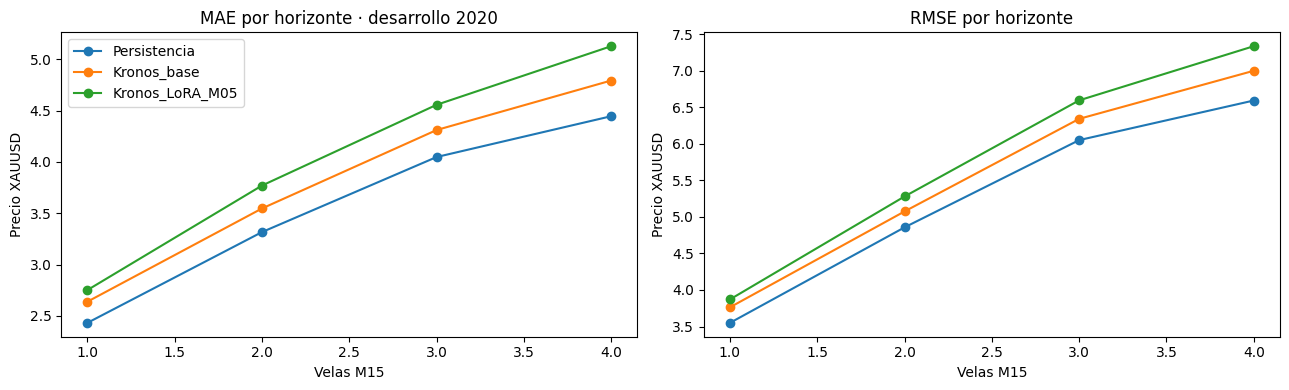

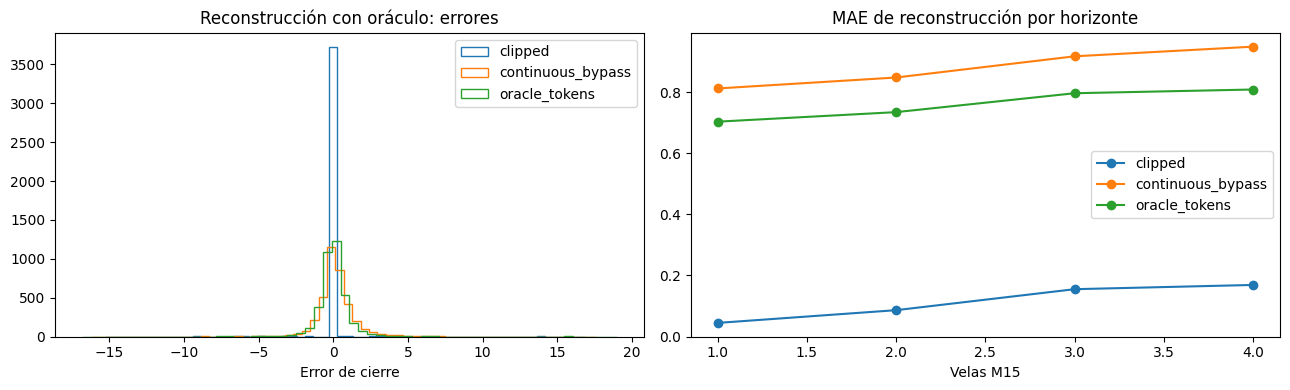

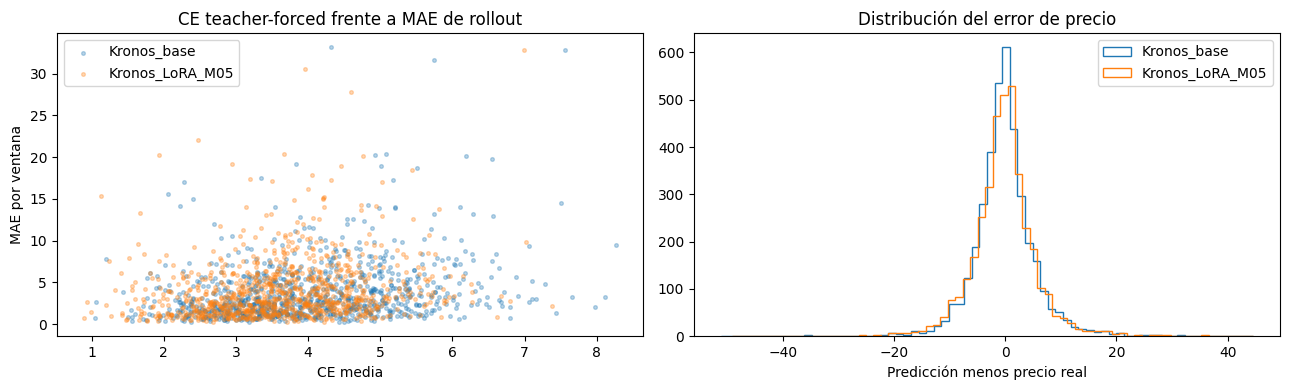

,model,MAE,RMSE,bias,direction_pct,direction_coverage_pct,actual_nonzero,magnitude_MAE,windows,seconds_per_window
0,Persistencia,3.560039,5.391019,0.086217,NaN,0.0,3796,3.560039,950,NaN
1,Kronos_base,3.821930,5.681343,-0.076112,49.552160,100.0,3796,2.807339,950,0.012464
2,Kronos_LoRA_M05,4.051262,5.919283,-0.219916,49.341412,100.0,3796,2.657946,950,0.013855


,intervention,variable,MAE,RMSE,scope
3,clipped,close,0.113709,0.998339,ORACULO_DIAGNOSTICO_NO_PREDICTOR
9,continuous_bypass,close,0.881785,1.594840,ORACULO_DIAGNOSTICO_NO_PREDICTOR
15,oracle_tokens,close,0.760945,1.509159,ORACULO_DIAGNOSTICO_NO_PREDICTOR
21,oracle_s1_only,close,0.962069,1.749196,ORACULO_DIAGNOSTICO_NO_PREDICTOR


,model,metric,E00_real_real,E10_pred_real,E01_real_pred,E11_pred_pred,interaction,shapley_s1,shapley_s2
0,Kronos_base,MAE,0.760945,2.452756,2.718505,3.821930,-0.588386,1.397618,1.663367
1,Kronos_base,MSE,2.277560,16.506169,21.555872,32.277662,-3.506819,12.475200,17.524903
2,Kronos_LoRA_M05,MAE,0.760945,2.403753,2.830919,4.051262,-0.422465,1.431576,1.858742
3,Kronos_LoRA_M05,MSE,2.277560,15.275189,22.425830,35.037917,-0.385543,12.804858,19.955499


DELTA_MSE_LORA_MENOS_BASE 2.7602541101292566
FASE_I_COMPLETA_2020 950 ventanas; intervenciones con oráculo excluidas de ranking predictivo


In [ ]:
#@title MISIÓN 06 · 3. Fase I: BSQ, clipping, intervenciones y referencias 2020
assert globals().get('M6_READY') is True
M6_LABELS=['Kronos_base','Kronos_LoRA_M05']
M6_FIELDS=['open','high','low','close','volume','amount']
M6_PRED={}; M6_CE={}; M6_TIMES={}
M6_AUDIT_PARTS=[]
audit_dir=M6_DIR/'checkpoints/fase_I'; audit_dir.mkdir(exist_ok=True)

@torch.no_grad()
def m6_decode_latent(latent, pre=False):
    z=m6_tok.post_quant_embed_pre(latent) if pre else m6_tok.post_quant_embed(latent)
    for layer in m6_tok.decoder: z=layer(z)
    return m6_tok.head(z)

for start in range(0,len(m6_dev),16):
    cache=audit_dir/f'batch_{start:04d}.npz'
    if cache.exists():
        with np.load(cache,allow_pickle=False) as cached: part={k:cached[k] for k in cached.files}
        M6_AUDIT_PARTS.append(part); continue
    batch=m6_batch(m6_dev,range(start,min(start+16,len(m6_dev))))
    with torch.no_grad():
        true_a,true_b=m6_tok.encode(batch['x'],half=True)
        context_a,context_b=m6_tok.encode(batch['x'][:,:56],half=True)
        assert torch.equal(true_a[:,:56],context_a) and torch.equal(true_b[:,:56],context_b)
        z=m6_tok.embed(batch['x'])
        for layer in m6_tok.encoder: z=layer(z)
        continuous=F.normalize(m6_tok.quant_embed(z),dim=-1)
        quantized=m6_tok.indices_to_bits([true_a,true_b],half=True)
        def to_price(norm): return norm[:,-4:]*batch['scale'][:,None]+batch['mean'][:,None]
        clip=to_price(batch['x'])
        cont=to_price(m6_decode_latent(continuous))
        oracle=to_price(m6_tok.decode([true_a,true_b],half=True))
        pre=to_price(m6_decode_latent(quantized[:,:,:10],pre=True))
        part={'truth':batch['truth'].cpu().numpy(),'last_close':batch['last_close'].cpu().numpy(),
              'clipped':clip.cpu().numpy(),'continuous_bypass':cont.cpu().numpy(),
              'oracle_tokens':oracle.cpu().numpy(),'oracle_s1_only':pre.cpu().numpy(),
              'latent_quantization_mse':(quantized-continuous).square().mean((1,2)).cpu().numpy()}
        for label in M6_LABELS:
            m6_mode(label); m6_sync(); t0=time.perf_counter()
            pred,(pa,pb)=m6_rollout(batch)
            m6_sync(); elapsed=time.perf_counter()-t0
            part[label]=pred[:,0].cpu().numpy()
            part[label+'_seconds']=np.array([elapsed])
            part[label+'_CE']=m6_ce(batch).cpu().numpy()
            aa,bb=pa[:,0].clone(),pb[:,0].clone()
            aa[:,56:]=true_a[:,56:]
            part[label+'_real_s1_pred_s2']=to_price(m6_tok.decode([aa,bb],half=True)).cpu().numpy()
            aa,bb=pa[:,0].clone(),pb[:,0].clone()
            bb[:,56:]=true_b[:,56:]
            part[label+'_pred_s1_real_s2']=to_price(m6_tok.decode([aa,bb],half=True)).cpu().numpy()
            part[label+'_token_accuracy']=np.stack([(pa[:,0,56:]==true_a[:,56:]).cpu().numpy(),(pb[:,0,56:]==true_b[:,56:]).cpu().numpy()],-1)
        assert all(np.isfinite(v).all() for v in part.values())
    np.savez_compressed(cache,**part)
    M6_AUDIT_PARTS.append(part)
    if start%160==0: print('FASE_I',start,'/',len(m6_dev),flush=True)

M6_AUDIT={k:np.concatenate([p[k] for p in M6_AUDIT_PARTS],axis=0) for k in M6_AUDIT_PARTS[0]}
M6_Y=M6_AUDIT['truth'][:,:,3].astype(np.float64)
M6_LAST=M6_AUDIT['last_close'].astype(np.float64)
M6_PRED['Persistencia']=np.repeat(M6_LAST[:,None],4,axis=1)
for label in M6_LABELS:
    M6_PRED[label]=M6_AUDIT[label][:,:,3].astype(np.float64)
    M6_CE[label]=M6_AUDIT[label+'_CE']
    M6_TIMES[label]=float(M6_AUDIT[label+'_seconds'].sum()/len(m6_dev))

def m6_metrics(pred,truth=M6_Y,last=M6_LAST):
    error=np.asarray(pred,dtype=np.float64)-truth
    change=pred-last[:,None]; actual=truth-last[:,None]
    nonflat=actual!=0; signals=change!=0
    return {'MAE':float(np.abs(error).mean()),'RMSE':float(np.sqrt(np.mean(error**2))),
            'bias':float(error.mean()),'direction_pct':float(100*np.mean(np.sign(change)[nonflat]==np.sign(actual)[nonflat])) if signals.any() and nonflat.any() else None,
            'direction_coverage_pct':float(100*signals.mean()),'actual_nonzero':int(nonflat.sum()),
            'magnitude_MAE':float(np.abs(np.abs(change)-np.abs(actual)).mean()),'windows':len(truth)}

def m6_prediction_frame(label,pred,ids=None):
    ids=np.arange(len(m6_dev)) if ids is None else np.asarray(ids)
    ix=m6_dev_ix.iloc[ids]
    return pd.DataFrame({'model':label,'window':np.repeat(ids,4),'horizon':np.tile(np.arange(1,5),len(ids)),
                         'ny_date':np.repeat(ix.ny_date.to_numpy(),4),'ny_hour':np.repeat(ix.ny_hour.to_numpy(),4),
                         'decision_utc':np.repeat(ix.decision_utc.astype(str).to_numpy(),4),
                         'truth':M6_Y[ids].ravel(),'last_close':np.repeat(M6_LAST[ids],4),'prediction':pred.ravel()})

def m6_paired_ci(pred,reference,ids=None):
    ids=np.arange(len(M6_Y)) if ids is None else np.asarray(ids)
    delta=np.abs(pred-M6_Y[ids])-np.abs(reference-M6_Y[ids])
    group=pd.DataFrame({'session':m6_dev_ix.iloc[ids].ny_date.to_numpy(),'delta_sum':delta.sum(1),'n':4}).groupby('session',sort=True).sum()
    values=group.delta_sum.to_numpy(); counts=group.n.to_numpy(); n=len(group)
    rng=np.random.default_rng(271828); draws=[]
    for _ in range(2000):
        starts=rng.integers(0,n,size=math.ceil(n/5))
        take=((starts[:,None]+np.arange(5))%n).ravel()[:n]
        draws.append(values[take].sum()/counts[take].sum())
    lo,hi=np.quantile(draws,[.025,.975])
    return {'delta_MAE':float(delta.mean()),'CI95_low':float(lo),'CI95_high':float(hi),'sessions':n,'bootstrap_replicates':2000,'block_sessions':5,'interpretation':'exploratorio; no corrige seleccion multiple'}

M6_BASELINE_TABLE=pd.DataFrame([{'model':label,**m6_metrics(p),'seconds_per_window':M6_TIMES.get(label)} for label,p in M6_PRED.items()])
M6_BASELINE_TABLE.to_csv(M6_DIR/'metricas/referencias_2020.csv',index=False)
pd.concat([m6_prediction_frame(label,p) for label,p in M6_PRED.items()]).to_parquet(M6_DIR/'metricas/referencias_predicciones_2020.parquet',index=False)
reconstruction=[]
for name in ['clipped','continuous_bypass','oracle_tokens','oracle_s1_only']:
    for j,field in enumerate(M6_FIELDS):
        e=M6_AUDIT[name][:,:,j].astype(np.float64)-M6_AUDIT['truth'][:,:,j]
        reconstruction.append({'intervention':name,'variable':field,'MAE':float(abs(e).mean()),'RMSE':float(np.sqrt((e**2).mean())),'scope':'ORACULO_DIAGNOSTICO_NO_PREDICTOR'})
M6_RECON_TABLE=pd.DataFrame(reconstruction)
M6_RECON_TABLE.to_csv(M6_DIR/'metricas/reconstruccion_OHLCV.csv',index=False)
factorial=[]; decomposition=[]
for label in M6_LABELS:
    e00=M6_AUDIT['oracle_tokens'][:,:,3]-M6_Y
    e10=M6_AUDIT[label+'_pred_s1_real_s2'][:,:,3]-M6_Y
    e01=M6_AUDIT[label+'_real_s1_pred_s2'][:,:,3]-M6_Y
    e11=M6_PRED[label]-M6_Y
    for metric,fun in [('MAE',lambda e:np.abs(e).mean()),('MSE',lambda e:np.square(e).mean())]:
        E00,E10,E01,E11=map(fun,[e00,e10,e01,e11])
        interaction=E11-E10-E01+E00
        phi1=.5*((E10-E00)+(E11-E01)); phi2=.5*((E01-E00)+(E11-E10))
        assert np.isclose(E00+phi1+phi2,E11)
        factorial.append({'model':label,'metric':metric,'E00_real_real':E00,'E10_pred_real':E10,'E01_real_pred':E01,'E11_pred_pred':E11,'interaction':interaction,'shapley_s1':phi1,'shapley_s2':phi2})
    stages={'clipping':M6_AUDIT['clipped'][:,:,3]-M6_Y,
            'decoder_continuous':M6_AUDIT['continuous_bypass'][:,:,3]-M6_AUDIT['clipped'][:,:,3],
            'quantization_intervention':M6_AUDIT['oracle_tokens'][:,:,3]-M6_AUDIT['continuous_bypass'][:,:,3],
            'token_prediction':M6_PRED[label]-M6_AUDIT['oracle_tokens'][:,:,3]}
    assert np.allclose(sum(stages.values()),e11)
    terms=[]
    for name,e in stages.items(): terms.append((name,float(np.mean(e**2))))
    names=list(stages)
    for i in range(len(names)):
        for j in range(i+1,len(names)):
            terms.append((names[i]+' x '+names[j],float(2*np.mean(stages[names[i]]*stages[names[j]]))))
    assert np.isclose(sum(v for _,v in terms),np.mean(e11**2),rtol=1e-5,atol=1e-5)
    for name,value in terms: decomposition.append({'model':label,'term':name,'MSE_contribution':value})
M6_FACTORIAL=pd.DataFrame(factorial); M6_DECOMP=pd.DataFrame(decomposition)
M6_FACTORIAL.to_csv(M6_DIR/'metricas/subcodigos_factorial.csv',index=False)
M6_DECOMP.to_csv(M6_DIR/'metricas/descomposicion_MSE_interacciones.csv',index=False)
degradation=M6_DECOMP.pivot(index='term',columns='model',values='MSE_contribution')
degradation['delta_MSE']=degradation.Kronos_LoRA_M05-degradation.Kronos_base
total_delta=float(degradation.delta_MSE.sum())
degradation['signed_percent_of_delta']=100*degradation.delta_MSE/total_delta if abs(total_delta)>1e-10 else np.nan
degradation.to_csv(M6_DIR/'metricas/atribucion_deterioro_MSE.csv')

def m6_figsave(name):
    plt.tight_layout(); plt.savefig(M6_DIR/'graficas'/name,dpi=150,bbox_inches='tight'); plt.show(); plt.close()

fig,axes=plt.subplots(1,2,figsize=(13,4))
for label,p in M6_PRED.items():
    axes[0].plot(range(1,5),np.abs(p-M6_Y).mean(0),marker='o',label=label)
    axes[1].plot(range(1,5),np.sqrt(((p-M6_Y)**2).mean(0)),marker='o',label=label)
axes[0].set(title='MAE por horizonte · desarrollo 2020',xlabel='Velas M15',ylabel='Precio XAUUSD')
axes[1].set(title='RMSE por horizonte',xlabel='Velas M15',ylabel='Precio XAUUSD'); axes[0].legend()
m6_figsave('01_referencias_por_horizonte.png')
fig,axes=plt.subplots(1,2,figsize=(13,4))
for name in ['clipped','continuous_bypass','oracle_tokens']:
    e=M6_AUDIT[name][:,:,3]-M6_Y
    axes[0].hist(e.ravel(),bins=60,histtype='step',label=name)
    axes[1].plot(range(1,5),abs(e).mean(0),marker='o',label=name)
axes[0].set(title='Reconstrucción con oráculo: errores',xlabel='Error de cierre'); axes[0].legend()
axes[1].set(title='MAE de reconstrucción por horizonte',xlabel='Velas M15'); axes[1].legend()
m6_figsave('02_auditoria_BSQ_clipping.png')
fig,axes=plt.subplots(1,2,figsize=(13,4))
for label in M6_LABELS:
    axes[0].scatter(M6_CE[label].mean((1,2)),abs(M6_PRED[label]-M6_Y).mean(1),s=7,alpha=.3,label=label)
    axes[1].hist((M6_PRED[label]-M6_Y).ravel(),bins=70,histtype='step',label=label)
axes[0].set(title='CE teacher-forced frente a MAE de rollout',xlabel='CE media',ylabel='MAE por ventana'); axes[0].legend()
axes[1].set(title='Distribución del error de precio',xlabel='Predicción menos precio real'); axes[1].legend()
m6_figsave('03_CE_error_y_sesgo.png')
display(M6_BASELINE_TABLE)
display(M6_RECON_TABLE[M6_RECON_TABLE.variable.eq('close')])
display(M6_FACTORIAL)
print('DELTA_MSE_LORA_MENOS_BASE',total_delta)
print('FASE_I_COMPLETA_2020',len(M6_Y),'ventanas; intervenciones con oráculo excluidas de ranking predictivo')
M6_PHASE_I_DONE=True


In [ ]:
#@title MISIÓN 06 · 4. Fase II: Monte Carlo, selección acotada y tres semillas
assert globals().get('M6_PHASE_I_DONE') is True, 'Recuperar M06 en este runtime antes de continuar'
M6_MC_BATCH=8
M6_CANDIDATE_META=globals().get('M6_CANDIDATE_META',{})
M6_MC_RUNS=[]
M6_MC_FULL_STATS=[]
M6_MC_PILOT_ROWS=[]
M6_MC_REPLICA_ROWS=[]

def m6_mc_cached(label,config,ids,seed,scope):
    ids=np.asarray(ids,dtype=int)
    identity={'label':label,'config':config,'ids':ids.tolist(),'seed':int(seed),'paths':32,
              'batch':M6_MC_BATCH,'base_hash':M6_BASE_HASH,'tokenizer_hash':M6_TOK_HASH,
              'adapter_checkpoint_sha256':M6_PROVENANCE[-1]['sha256'],
              'dataset_hashes':M6_SOURCE_MANIFEST,'seed_rule':'seed + first_window_id_of_batch * 1009'}
    digest=hashlib.sha256(json.dumps(identity,sort_keys=True,default=str).encode()).hexdigest()[:16]
    folder=M6_DIR/'checkpoints/fase_II'/digest; folder.mkdir(parents=True,exist_ok=True)
    m6_save_json(str(folder.relative_to(M6_DIR)/'identity.json'),identity)
    outputs=[]; seconds=0.
    m6_mode(label)
    for offset in range(0,len(ids),64):
        shard=folder/f'shard_{offset:04d}.npz'
        subset=ids[offset:offset+64]
        if shard.exists():
            with np.load(shard,allow_pickle=False) as z:
                assert np.array_equal(z['ids'],subset)
                result=z['paths']; duration=float(z['seconds'])
        else:
            parts=[]; duration=0.
            for j in range(0,len(subset),M6_MC_BATCH):
                batch_ids=subset[j:j+M6_MC_BATCH]
                batch=m6_batch(m6_dev,batch_ids)
                m6_sync(); t0=time.perf_counter()
                p,_=m6_rollout(batch,paths=32,seed=int(seed)+int(batch_ids[0])*1009,
                               temperature=config['temperature'],top_k=config['top_k'],top_p=config['top_p'])
                m6_sync(); duration+=time.perf_counter()-t0
                parts.append(p[:,:,:,3].cpu().numpy())
            result=np.concatenate(parts)
            assert np.isfinite(result).all()
            np.savez_compressed(shard,ids=subset,paths=result,seconds=duration)
        outputs.append(result); seconds+=duration
        if scope=='desarrollo_completo' and (offset==0 or offset%256==0):
            print('MC',scope,label,config['id'],'seed',seed,offset+len(subset),'/',len(ids),flush=True)
    M6_MC_RUNS.append({'model':label,'configuration':config['id'],'seed':seed,'scope':scope,'windows':len(ids),
                       'paths':32,'seconds_inference':seconds,'seconds_per_window':seconds/len(ids),'cache':digest})
    return np.concatenate(outputs),seconds

# Cinco configuraciones prefijadas, mismo subconjunto de 32 sesiones para todos.
for label in M6_LABELS:
    for cfg in M6_PLAN['mc_configs']:
        paths,seconds=m6_mc_cached(label,cfg,M6_MC_IDS,271828,'exploracion_32_sesiones')
        for count in [16,32]:
            for agg in ['mean','median']:
                pred=getattr(np,agg)(paths[:,:count],axis=1)
                row={'model':label,'configuration':cfg['id'],'paths':count,'aggregate':agg,
                     'scope':'exploracion_32_sesiones','seed':271828,
                     **m6_metrics(pred,M6_Y[M6_MC_IDS],M6_LAST[M6_MC_IDS]),
                     'trajectory_std':float(paths[:,:count].std(axis=1).mean()),
                     'seconds_per_window_32_paths':seconds/len(M6_MC_IDS)}
                M6_MC_PILOT_ROWS.append(row)
                pd.DataFrame(M6_MC_PILOT_ROWS).to_csv(M6_DIR/'metricas/MC_exploracion.csv',index=False)
        print('MC_EXPLORACION_LISTA',label,cfg['id'],flush=True)

M6_MC_PILOT=pd.DataFrame(M6_MC_PILOT_ROWS)
M6_MC_SELECTED=[]
for label in M6_LABELS:
    # Desempate determinista; no ampliar la búsqueda tras ver estos resultados.
    row=M6_MC_PILOT[M6_MC_PILOT.model.eq(label)].sort_values(['MAE','configuration','paths','aggregate']).iloc[0]
    choice={'model':label,'configuration':str(row.configuration),'paths':int(row.paths),'aggregate':str(row.aggregate),
            'selection_MAE':float(row.MAE),'selection_scope':'32 sesiones de desarrollo 2020; no evaluacion independiente'}
    M6_MC_SELECTED.append(choice)
m6_save_json('configuraciones/MC_seleccion_fijada.json',M6_MC_SELECTED)
print('MC_SELECCION_FIJADA',M6_MC_SELECTED,flush=True)

for choice in M6_MC_SELECTED:
    label=choice['model']; cfg=next(c for c in M6_PLAN['mc_configs'] if c['id']==choice['configuration'])
    for seed in M6_PLAN['replicate_seeds']:
        paths,seconds=m6_mc_cached(label,cfg,np.arange(len(m6_dev)),seed,'desarrollo_completo')
        pred=getattr(np,choice['aggregate'])(paths[:,:choice['paths']],axis=1).astype(np.float64)
        name=f"MC_{label}_{cfg['id']}_{choice['paths']}_{choice['aggregate']}_s{seed}"
        M6_PRED[name]=pred; M6_TIMES[name]=seconds/len(m6_dev)
        M6_CANDIDATE_META[name]={'family':'MC_'+label,'seed':seed,'eligible':True,'selection':'MC_seleccion_fijada.json'}
        stats={'model':name,'base_model':label,'seed':seed,**m6_metrics(pred),
               'trajectory_std':float(paths[:,:choice['paths']].std(axis=1).mean()),
               'seconds_per_window_32_paths':seconds/len(m6_dev)}
        M6_MC_REPLICA_ROWS.append(stats)
        m6_prediction_frame(name,pred).to_parquet(M6_DIR/'metricas'/f'{name}.parquet',index=False)
        for ref in ['Persistencia','Kronos_base']:
            M6_MC_FULL_STATS.append({'candidate':name,'reference':ref,**m6_paired_ci(pred,M6_PRED[ref])})
        if seed==271828:
            # Comparación de agregaciones para visualizar; no sustituye la elección fijada.
            for count in [16,32]:
                for agg in ['mean','median']:
                    p=getattr(np,agg)(paths[:,:count],axis=1).astype(np.float64)
                    diag=f'MC_DIAG_{label}_{count}_{agg}'
                    M6_PRED[diag]=p
                    M6_CANDIDATE_META[diag]={'family':'MC_diagnostic','seed':seed,'eligible':False}
        pd.DataFrame(M6_MC_REPLICA_ROWS).to_csv(M6_DIR/'metricas/MC_replicas_2020.csv',index=False)
        pd.DataFrame(M6_MC_FULL_STATS).to_csv(M6_DIR/'metricas/MC_intervalos_pareados.csv',index=False)
        pd.DataFrame(M6_MC_RUNS).to_csv(M6_DIR/'metricas/MC_tiempos.csv',index=False)
        m6_save_json('configuraciones/candidatos.json',M6_CANDIDATE_META)
        print('MC_REPLICA_FINALIZADA',name,'MAE',stats['MAE'],flush=True)

M6_MC_REPLICAS=pd.DataFrame(M6_MC_REPLICA_ROWS)
fig,axes=plt.subplots(1,2,figsize=(14,5))
for axis,label in zip(axes,M6_LABELS):
    sub=M6_MC_PILOT[M6_MC_PILOT.model.eq(label)]
    for (count,agg),g in sub.groupby(['paths','aggregate']):
        g=g.set_index('configuration').reindex([c['id'] for c in M6_PLAN['mc_configs']])
        axis.plot(g.index,g.MAE,marker='o',label=f'{count} {agg}')
    for ref in ['Persistencia','Kronos_base']:
        mae=m6_metrics(M6_PRED[ref][M6_MC_IDS],M6_Y[M6_MC_IDS],M6_LAST[M6_MC_IDS])['MAE']
        axis.axhline(mae,linestyle='--',label=ref)
    axis.set(title=label+' · 32 sesiones exploratorias',ylabel='MAE de precio'); axis.legend(fontsize=8)
m6_figsave('04_MC_busqueda_acotada.png')
fig,axes=plt.subplots(1,2,figsize=(14,5))
for axis,label in zip(axes,M6_LABELS):
    names=[label,'Persistencia']+[f'MC_DIAG_{label}_{n}_{agg}' for n in [16,32] for agg in ['mean','median']]
    for name in names: axis.plot(range(1,5),np.abs(M6_PRED[name]-M6_Y).mean(0),marker='o',label=name.replace('MC_DIAG_'+label+'_',''))
    axis.set(title=label+' · 950 ventanas 2020',xlabel='Horizonte M15',ylabel='MAE'); axis.legend(fontsize=7)
m6_figsave('05_MC_media_mediana_horizonte.png')
display(M6_MC_REPLICAS)
display(pd.DataFrame(M6_MC_FULL_STATS))
assert m6_hash(m6_model,True)==M6_BASE_HASH and m6_hash(m6_tok)==M6_TOK_HASH
M6_PHASE_II_DONE=True
print('FASE_II_COMPLETA; 2020 es desarrollo reutilizado; no promover sin evaluación posterior autorizada')


AssertionError: Recuperar M06 en este runtime antes de continuar

In [9]:
#@title MISIÓN 06 · R. Recuperación verificada del runtime y cachés M06
import sys, os, json, hashlib, platform, importlib.metadata as m6_metadata
from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display, Markdown
import torch
from google.colab import drive
M6_BASE=Path('/content/drive/MyDrive/AXXEL_CAPITAL')
M6_DIR=M6_BASE/'MISION06_ALINEACION/20261114T222455Z_32d5e571'
if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')
assert M6_DIR.is_dir(), 'Falta la ejecución M06 que se va a recuperar'
M6_DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert M6_DEVICE.type=='cuda', 'La recuperación requiere la GPU disponible para el presupuesto acordado'
def m6_sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda:f.read(1<<20),b''): h.update(chunk)
    return h.hexdigest()
M6_POLICY=json.loads((M6_DIR/'configuraciones/politica.json').read_text())
M6_PROVENANCE=json.loads((M6_DIR/'auditoria/procedencia.json').read_text())
M6_HIST=Path(M6_PROVENANCE[0]['path']).parent
M6_CHECKPOINT=Path(M6_PROVENANCE[-1]['path'])
for item in M6_PROVENANCE: assert m6_sha(item['path'])==item['sha256']
M6_PREFLIGHT_OK=True
print('RECUPERANDO',str(M6_DIR),'GPU',torch.cuda.get_device_name(0),flush=True)
#@title MISIÓN 06 · 1. Datos autorizados, índice nuevo y normalización causal
assert globals().get('M6_PREFLIGHT_OK') is True, 'Ejecutar primero M06 · 0'
import numpy as np
import pandas as pd

M6_SOURCE = M6_BASE / 'datasets/processed/kronos_ohlcv_v1'
M6_SOURCE_MANIFEST, m6_parts = [], []
# Lista cerrada; no se enumeran directorios de datos, archivos ZIP ni índices históricos.
def m6_authorized_source(year):
    if type(year) is not int or year not in range(2010, 2021):
        raise ValueError('M06 solo permite archivos fuente 2010–2020')
    return M6_SOURCE / f'XAUUSD_M15_BID_{year}.parquet'

for m6_year in range(2010, 2021):
    m6_path = m6_authorized_source(m6_year)
    m6_digest = m6_sha(m6_path)
    m6_part = pd.read_parquet(m6_path)
    m6_part['timestamp_utc'] = pd.to_datetime(m6_part.timestamp_utc, utc=True)
    assert len(m6_part) and m6_part.timestamp_utc.dt.year.eq(m6_year).all()
    assert m6_part.timestamp_utc.is_monotonic_increasing and m6_part.timestamp_utc.is_unique
    assert m6_part.m1_candles.eq(15).all()
    m6_prices = m6_part[['open', 'high', 'low', 'close', 'volume']]
    assert np.isfinite(m6_prices.to_numpy()).all()
    assert (m6_part.low > 0).all() and (m6_part.volume >= 0).all()
    assert (m6_part.low <= m6_part[['open', 'close']].min(axis=1)).all()
    assert (m6_part.high >= m6_part[['open', 'close']].max(axis=1)).all()
    assert (m6_part.low <= m6_part.high).all()
    assert m6_sha(m6_path) == m6_digest, 'Fuente cambió durante lectura'
    M6_SOURCE_MANIFEST.append({'year': m6_year, 'file': m6_path.name, 'rows': len(m6_part), 'sha256': m6_digest})
    m6_parts.append(m6_part[['timestamp_utc', 'open', 'high', 'low', 'close', 'volume']].copy())
m6_df = pd.concat(m6_parts, ignore_index=True)
del m6_parts, m6_part, m6_prices
assert m6_df.timestamp_utc.is_unique and m6_df.timestamp_utc.is_monotonic_increasing
m6_ts = m6_df.timestamp_utc.astype('int64').to_numpy()
M6_STEP = 15 * 60 * 10**9
assert np.all(m6_ts % M6_STEP == 0)
m6_df['split'] = np.where(m6_df.timestamp_utc.dt.year <= 2019, 'train', 'development')
m6_df['segment'] = (m6_df.timestamp_utc.diff().ne(pd.Timedelta(minutes=15)) |
                    m6_df.split.ne(m6_df.split.shift())).cumsum()
m6_windows = []
for m6_segment, m6_group in m6_df.groupby('segment', sort=False):
    m6_first, m6_last = int(m6_group.index[0]), int(m6_group.index[-1])
    m6_starts = np.arange(m6_first, m6_last - 59 + 1, dtype=np.int64)
    if not len(m6_starts):
        continue
    m6_decisions = m6_df.timestamp_utc.iloc[m6_starts + 56]
    m6_ny = m6_decisions.dt.tz_convert('America/New_York')
    for s, decision, ny in zip(m6_starts, m6_decisions, m6_ny):
        if ny.strftime('%H:%M') not in M6_POLICY['ny_anchors']:
            continue
        m6_windows.append({'start_row': int(s), 'split': m6_group.split.iloc[0],
                           'decision_utc': decision, 'decision_ny': ny.isoformat(),
                           'ny_date': ny.strftime('%Y-%m-%d'), 'ny_hour': ny.strftime('%H:%M'),
                           'context_start': m6_df.timestamp_utc.iloc[s],
                           'target_end': m6_df.timestamp_utc.iloc[s+59] + pd.Timedelta(minutes=15)})
m6_ix = pd.DataFrame(m6_windows).sort_values('decision_utc').reset_index(drop=True)
assert len(m6_ix) and m6_ix.decision_utc.is_unique
m6_train_ix = m6_ix[m6_ix.split.eq('train')].reset_index(drop=True)
m6_dev_ix = m6_ix[m6_ix.split.eq('development')].reset_index(drop=True)
assert len(m6_train_ix) and len(m6_dev_ix)
assert m6_dev_ix.decision_utc.dt.year.eq(2020).all()
assert m6_train_ix.target_end.max() < m6_dev_ix.context_start.min()
assert (m6_ix.decision_utc.iloc[1:].to_numpy() >= m6_ix.target_end.iloc[:-1].to_numpy()).all()
m6_starts = m6_ix.start_row.to_numpy(np.int64)
assert np.all(m6_ts[m6_starts[:, None] + np.arange(60)] == m6_ts[m6_starts, None] + np.arange(60) * M6_STEP)

def m6_normalize(raw):
    raw = np.asarray(raw, dtype=np.float32)
    if raw.shape != (60, 6):
        raise ValueError('Contrato M06: 60 filas, OHLCV + amount=0')
    mean = raw[:56].mean(axis=0)
    scale = raw[:56].std(axis=0) + np.float32(1e-5)
    return np.clip((raw - mean) / scale, -5, 5), mean, scale

class M6Dataset(torch.utils.data.Dataset):
    def __init__(self, frame, index):
        self.L, self.H = 56, 4
        self.index = index.reset_index(drop=True)
        self.starts = self.index.start_row.to_numpy(np.int64)
        self.values = np.column_stack([frame[['open','high','low','close','volume']].to_numpy(np.float32), np.zeros(len(frame), np.float32)])
        t = frame.timestamp_utc.dt
        self.stamp = np.column_stack([t.minute, t.hour, t.weekday, t.day, t.month]).astype(np.float32)
    def __len__(self):
        return len(self.starts)
    def __getitem__(self, i):
        s = int(self.starts[i])
        raw = self.values[s:s+60].copy()
        x, mean, scale = m6_normalize(raw)
        return {'x': torch.from_numpy(x), 'stamp': torch.from_numpy(self.stamp[s:s+60].copy()),
                'loss_mask': torch.from_numpy(np.arange(59) >= 55),
                'mean': torch.from_numpy(mean), 'scale': torch.from_numpy(scale),
                'truth': torch.from_numpy(raw[56:].copy()), 'last_close': torch.tensor(raw[55,3])}

m6_train = M6Dataset(m6_df, m6_train_ix)
m6_dev = M6Dataset(m6_df, m6_dev_ix)
m6_probe = m6_train.values[m6_train.starts[0]:m6_train.starts[0]+60].copy()
m6_changed = m6_probe.copy()
m6_changed[56:] += np.float32(10000)
m6_before, m6_after = m6_normalize(m6_probe), m6_normalize(m6_changed)
assert np.array_equal(m6_before[0][:56], m6_after[0][:56])
assert np.array_equal(m6_before[1], m6_after[1]) and np.array_equal(m6_before[2], m6_after[2])
M6_DATA_CHECKS = {'loaded_years': list(range(2010, 2021)), 'normalization_future_invariant': True,
                  'train_windows': len(m6_train), 'development_windows': len(m6_dev),
                  'development_ny_sessions': int(m6_dev_ix.ny_date.nunique()),
                  'causal_model_checks': 'PENDING', 'predictive_experiments': 'NOT_EXECUTED'}

assert M6_SOURCE_MANIFEST==json.loads((M6_DIR/'auditoria/datasets_autorizados.json').read_text())
pd.testing.assert_frame_equal(m6_ix,pd.read_parquet(M6_DIR/'auditoria/ventanas_m06.parquet'))
print('DATOS_RECUPERADOS_Y_HASHES_VERIFICADOS',len(m6_train),len(m6_dev),flush=True)
#@title MISIÓN 06 · 2. Modelos congelados, causalidad y protocolo experimental
assert globals().get('M6_PREFLIGHT_OK') and 'm6_dev' in globals()
import os, sys, time, math, random, copy, inspect, importlib.util
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import default_collate
from huggingface_hub import snapshot_download
import matplotlib.pyplot as plt
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
torch.use_deterministic_algorithms(True)
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.set_num_threads(min(2, os.cpu_count() or 1))

def m6_save_json(rel, obj):
    path = (M6_DIR / rel).resolve()
    assert M6_DIR.resolve() in path.parents
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str, allow_nan=False), encoding='utf-8')
    os.replace(tmp, path)

def m6_seed(seed=271828):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def m6_hash(net, base=False):
    h = hashlib.sha256()
    for name, value in sorted(net.state_dict().items()):
        if base and ('lora_A' in name or 'lora_B' in name): continue
        name = name.replace('.base.', '.') if base else name
        h.update(name.encode()); h.update(str(tuple(value.shape)).encode())
        h.update(value.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()

assert m6_sha(M6_HIST/'kronos_pipeline.py') == M6_PROVENANCE[0]['sha256']
spec = importlib.util.spec_from_file_location('m6_kp', M6_HIST/'kronos_pipeline.py')
m6_kp = importlib.util.module_from_spec(spec); spec.loader.exec_module(m6_kp)
assert m6_kp.COMMIT == '67b630e67f6a18c9e9be918d9b4337c960db1e9a'
M6_WEIGHTS = Path('/content/kronos_weights_pinned')
for repo, rev in m6_kp.REVISIONS.items():
    snapshot_download('NeoQuasar/'+repo, revision=rev, local_dir=str(M6_WEIGHTS/repo), allow_patterns=['config.json','model.safetensors'])
m6_model, m6_tok = m6_kp.load_models(M6_WEIGHTS, M6_DEVICE)
m6_model.requires_grad_(False).eval(); m6_tok.requires_grad_(False).eval()
assert len(m6_model.transformer) == 8 and m6_model.d_model == 512
assert (m6_tok.s1_bits, m6_tok.s2_bits) == (10, 10)
M6_BASE_HASH, M6_TOK_HASH = m6_hash(m6_model), m6_hash(m6_tok)
assert m6_sha(M6_CHECKPOINT) == M6_PROVENANCE[-1]['sha256']
m6_packet = torch.load(M6_CHECKPOINT, map_location='cpu', weights_only=False)
assert m6_packet['base_hash'] == M6_BASE_HASH and m6_packet['tokenizer_hash'] == M6_TOK_HASH
assert m6_packet['step'] == 1000
M6_ADAPTER_M05 = {k:v.clone() for k,v in m6_packet['adapter'].items()}
M6_M05_CONFIG = m6_packet['config']
del m6_packet

class M6LoRA(nn.Module):
    def __init__(self, base):
        super().__init__(); self.base = base.requires_grad_(False); self.enabled = True
        self.lora_A = nn.Parameter(torch.zeros(8, base.in_features, device=base.weight.device), requires_grad=False)
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, 8, device=base.weight.device), requires_grad=False)
        self.dropout = nn.Dropout(.10); self.scale = 2.
    def forward(self, x):
        y = self.base(x)
        return y + F.linear(F.linear(self.dropout(x), self.lora_A), self.lora_B)*self.scale if self.enabled else y

M6_TARGETS = []
for name, module in list(m6_model.named_modules()):
    if type(module).__name__ in ['MultiHeadAttentionWithRoPE','MultiHeadCrossAttentionWithRoPE']:
        for leaf in ['q_proj','v_proj']:
            layer = getattr(module, leaf)
            M6_TARGETS.append(name+'.'+leaf); setattr(module, leaf, M6LoRA(layer))
assert len(M6_TARGETS) == 18
M6_ADAPTER_PARAMS = {n:p for n,p in m6_model.named_parameters() if 'lora_' in n}
assert set(M6_ADAPTER_PARAMS) == set(M6_ADAPTER_M05)
assert sum(p.numel() for p in M6_ADAPTER_PARAMS.values()) == 147456
with torch.no_grad():
    for name, param in M6_ADAPTER_PARAMS.items(): param.copy_(M6_ADAPTER_M05[name].to(param.device))

def m6_mode(label):
    assert label in ['Kronos_base','Kronos_LoRA_M05']
    for name in M6_TARGETS: m6_model.get_submodule(name).enabled = label == 'Kronos_LoRA_M05'
    m6_model.eval(); m6_tok.eval()

def m6_batch(ds, ids):
    return {k:v.to(M6_DEVICE) for k,v in default_collate([ds[int(i)] for i in ids]).items()}

def m6_sync():
    if M6_DEVICE.type == 'cuda': torch.cuda.synchronize()

M6_CAUSAL = {}
for label in ['Kronos_base','Kronos_LoRA_M05']:
    m6_mode(label)
    M6_CAUSAL[label] = m6_kp.contract_tests(m6_model, m6_tok, m6_train, M6_DEVICE)
assert m6_hash(m6_model, True) == M6_BASE_HASH and m6_hash(m6_tok) == M6_TOK_HASH
assert not any(p.requires_grad for p in m6_model.parameters())

@torch.no_grad()
def m6_rollout(batch, paths=1, seed=271828, temperature=None, top_k=0, top_p=1.):
    # El predictor y sus representaciones reciben solo contexto observado.
    m6_model.eval(); m6_tok.eval()
    a,b = m6_tok.encode(batch['x'][:,:56], half=True)
    a=a.repeat_interleave(paths,0); b=b.repeat_interleave(paths,0)
    stamp=batch['stamp'].repeat_interleave(paths,0)
    generator=torch.Generator(device=M6_DEVICE).manual_seed(int(seed))
    def choose(logits):
        if temperature is None: return logits.argmax(-1, keepdim=True)
        logits=logits/float(temperature)
        if top_k:
            logits=logits.masked_fill(logits < logits.topk(top_k).values[:,-1:], -float('inf'))
        if top_p < 1:
            values,order=logits.sort(descending=True)
            remove=values.softmax(-1).cumsum(-1)>top_p
            remove[:,1:]=remove[:,:-1].clone(); remove[:,0]=False
            logits=logits.masked_fill(torch.zeros_like(remove).scatter(1,order,remove), -float('inf'))
        return torch.multinomial(logits.softmax(-1),1,generator=generator)
    for j in range(4):
        logits, hidden=m6_model.decode_s1(a,b,stamp=stamp[:,:56+j])
        na=choose(logits[:,-1])
        nb=choose(m6_model.decode_s2(hidden,torch.cat([a[:,1:],na],1))[:,-1])
        a=torch.cat([a,na],1); b=torch.cat([b,nb],1)
    prediction=m6_tok.decode([a,b],half=True)[:,-4:]
    prediction=prediction*batch['scale'].repeat_interleave(paths,0)[:,None]+batch['mean'].repeat_interleave(paths,0)[:,None]
    return prediction.reshape(len(batch['x']),paths,4,6), (a.reshape(len(batch['x']),paths,60),b.reshape(len(batch['x']),paths,60))

@torch.no_grad()
def m6_ce(batch):
    a,b=m6_tok.encode(batch['x'],half=True)
    l1,l2=m6_model(a[:,:-1],b[:,:-1],stamp=batch['stamp'][:,:-1],use_teacher_forcing=True,s1_targets=a[:,1:])
    ce1=F.cross_entropy(l1.transpose(1,2),a[:,1:],reduction='none')[:,55:]
    ce2=F.cross_entropy(l2.transpose(1,2),b[:,1:],reduction='none')[:,55:]
    return torch.stack([ce1,ce2],-1)

@torch.no_grad()
def m6_features(batch):
    a,b=m6_tok.encode(batch['x'][:,:56],half=True)
    return m6_model.decode_s1(a,b,stamp=batch['stamp'][:,:56])[1][:,-1]

m6_mode('Kronos_base'); probe=m6_batch(m6_train,[0,1])
pred,_=m6_rollout(probe)
assert torch.equal(pred[:,0],m6_kp.rollout(m6_model,m6_tok,probe,56,4))
alternate={k:v.clone() for k,v in probe.items()}; alternate['x'][:,56:]*=-1; alternate['truth'].zero_()
assert torch.equal(m6_features(probe),m6_features(alternate))
p1,_=m6_rollout(probe,paths=32,temperature=.8,seed=271828)
p2,_=m6_rollout(alternate,paths=32,temperature=.8,seed=271828)
assert torch.equal(p1,p2)
M6_PROFILE=[]
for paths in [1,32]:
    m6_sync(); start=time.perf_counter()
    _=m6_rollout(m6_batch(m6_train,range(4)),paths=paths,temperature=None if paths==1 else .8)
    m6_sync(); M6_PROFILE.append({'paths':paths,'windows':4,'seconds':time.perf_counter()-start})

M6_PLAN={'seed':271828,'replicate_seeds':[271828,271829,271830], 'L':56,'H':4,
 'train_windows':len(m6_train),'development_windows':len(m6_dev),'development_year':2020,
 'mc_configs':[{'id':'T06','temperature':.6,'top_k':0,'top_p':1.}, {'id':'T08','temperature':.8,'top_k':0,'top_p':1.}, {'id':'T10','temperature':1.,'top_k':0,'top_p':1.}, {'id':'K50_T08','temperature':.8,'top_k':50,'top_p':1.}, {'id':'P90_T08','temperature':.8,'top_k':0,'top_p':.9}],
 'mc_paths':[16,32], 'mc_aggregates':['mean','median'], 'mc_exploration_sessions':32,
 'mc_selection':'menor MAE exploratorio por modelo; una configuracion/metodo por modelo; replicar con 3 seeds en 2020 completo',
 'head_losses':['Huber','Laplace_NLL'],'head_steps':300,'head_batch':64,'head_lr':.001,'head_seeds':[271828,271829,271830],
 'head_selection':'checkpoint menor MAE 2020 cada 50 pasos; 2020 es desarrollo, no holdout independiente',
 'bootstrap':{'replicates':2000,'session_block':5,'seed':271828},
 'phase_IV':'Condicionada a resultados I–III; presupuesto y decision se documentan antes de entrenar',
 'reserved_evaluation_executed':False,'research_only':True,'orders_enabled':False}
days=np.array(sorted(m6_dev_ix.ny_date.unique()))
M6_MC_DAYS=days[np.linspace(0,len(days)-1,32,dtype=int)].tolist()
M6_MC_IDS=np.flatnonzero(m6_dev_ix.ny_date.isin(M6_MC_DAYS)).tolist()
M6_PLAN['mc_exploration_days']=M6_MC_DAYS
m6_save_json('configuraciones/protocolo_experimentos.json',M6_PLAN)
m6_save_json('auditoria/causalidad_modelos.json',M6_CAUSAL)
m6_save_json('auditoria/perfil_inferencia.json',M6_PROFILE)
m6_save_json('auditoria/modelos.json',{'base_hash':M6_BASE_HASH,'tokenizer_hash':M6_TOK_HASH,'commit':m6_kp.COMMIT,'revisions':m6_kp.REVISIONS,'checkpoint':str(M6_CHECKPOINT),'checkpoint_sha256':m6_sha(M6_CHECKPOINT),'lora_targets':M6_TARGETS,'trainable_parameters':0,'greedy_matches_M05_implementation':True,'hidden_and_sampling_future_invariant':True})
for source in ['model/kronos.py','model/module.py']:
    dest=M6_DIR/'auditoria'/Path(source).name
    dest.write_bytes((M6_HIST/'vendor'/source).read_bytes())
(M6_DIR/'auditoria/kronos_pipeline.py').write_bytes((M6_HIST/'kronos_pipeline.py').read_bytes())
M6_READY=True
print('MODELOS_Y_CAUSALIDAD_VERIFICADOS',M6_CAUSAL)
display(pd.DataFrame(M6_PROFILE))
print('PROTOCOLO_FIJADO_ANTES_DE_METRICAS_2020',len(M6_MC_IDS),'ventanas MC exploratorias')

for start in range(0,len(m6_dev),16):
    assert (M6_DIR/'checkpoints/fase_I'/f'batch_{start:04d}.npz').is_file(), 'Falta caché; no recalcular silenciosamente'
#@title MISIÓN 06 · 3. Fase I: BSQ, clipping, intervenciones y referencias 2020
assert globals().get('M6_READY') is True
M6_LABELS=['Kronos_base','Kronos_LoRA_M05']
M6_FIELDS=['open','high','low','close','volume','amount']
M6_PRED={}; M6_CE={}; M6_TIMES={}
M6_AUDIT_PARTS=[]
audit_dir=M6_DIR/'checkpoints/fase_I'; audit_dir.mkdir(exist_ok=True)

@torch.no_grad()
def m6_decode_latent(latent, pre=False):
    z=m6_tok.post_quant_embed_pre(latent) if pre else m6_tok.post_quant_embed(latent)
    for layer in m6_tok.decoder: z=layer(z)
    return m6_tok.head(z)

for start in range(0,len(m6_dev),16):
    cache=audit_dir/f'batch_{start:04d}.npz'
    if cache.exists():
        with np.load(cache,allow_pickle=False) as cached: part={k:cached[k] for k in cached.files}
        M6_AUDIT_PARTS.append(part); continue
    batch=m6_batch(m6_dev,range(start,min(start+16,len(m6_dev))))
    with torch.no_grad():
        true_a,true_b=m6_tok.encode(batch['x'],half=True)
        context_a,context_b=m6_tok.encode(batch['x'][:,:56],half=True)
        assert torch.equal(true_a[:,:56],context_a) and torch.equal(true_b[:,:56],context_b)
        z=m6_tok.embed(batch['x'])
        for layer in m6_tok.encoder: z=layer(z)
        continuous=F.normalize(m6_tok.quant_embed(z),dim=-1)
        quantized=m6_tok.indices_to_bits([true_a,true_b],half=True)
        def to_price(norm): return norm[:,-4:]*batch['scale'][:,None]+batch['mean'][:,None]
        clip=to_price(batch['x'])
        cont=to_price(m6_decode_latent(continuous))
        oracle=to_price(m6_tok.decode([true_a,true_b],half=True))
        pre=to_price(m6_decode_latent(quantized[:,:,:10],pre=True))
        part={'truth':batch['truth'].cpu().numpy(),'last_close':batch['last_close'].cpu().numpy(),
              'clipped':clip.cpu().numpy(),'continuous_bypass':cont.cpu().numpy(),
              'oracle_tokens':oracle.cpu().numpy(),'oracle_s1_only':pre.cpu().numpy(),
              'latent_quantization_mse':(quantized-continuous).square().mean((1,2)).cpu().numpy()}
        for label in M6_LABELS:
            m6_mode(label); m6_sync(); t0=time.perf_counter()
            pred,(pa,pb)=m6_rollout(batch)
            m6_sync(); elapsed=time.perf_counter()-t0
            part[label]=pred[:,0].cpu().numpy()
            part[label+'_seconds']=np.array([elapsed])
            part[label+'_CE']=m6_ce(batch).cpu().numpy()
            aa,bb=pa[:,0].clone(),pb[:,0].clone()
            aa[:,56:]=true_a[:,56:]
            part[label+'_real_s1_pred_s2']=to_price(m6_tok.decode([aa,bb],half=True)).cpu().numpy()
            aa,bb=pa[:,0].clone(),pb[:,0].clone()
            bb[:,56:]=true_b[:,56:]
            part[label+'_pred_s1_real_s2']=to_price(m6_tok.decode([aa,bb],half=True)).cpu().numpy()
            part[label+'_token_accuracy']=np.stack([(pa[:,0,56:]==true_a[:,56:]).cpu().numpy(),(pb[:,0,56:]==true_b[:,56:]).cpu().numpy()],-1)
        assert all(np.isfinite(v).all() for v in part.values())
    np.savez_compressed(cache,**part)
    M6_AUDIT_PARTS.append(part)
    if start%160==0: print('FASE_I',start,'/',len(m6_dev),flush=True)

M6_AUDIT={k:np.concatenate([p[k] for p in M6_AUDIT_PARTS],axis=0) for k in M6_AUDIT_PARTS[0]}
M6_Y=M6_AUDIT['truth'][:,:,3].astype(np.float64)
M6_LAST=M6_AUDIT['last_close'].astype(np.float64)
M6_PRED['Persistencia']=np.repeat(M6_LAST[:,None],4,axis=1)
for label in M6_LABELS:
    M6_PRED[label]=M6_AUDIT[label][:,:,3].astype(np.float64)
    M6_CE[label]=M6_AUDIT[label+'_CE']
    M6_TIMES[label]=float(M6_AUDIT[label+'_seconds'].sum()/len(m6_dev))

def m6_metrics(pred,truth=M6_Y,last=M6_LAST):
    error=np.asarray(pred,dtype=np.float64)-truth
    change=pred-last[:,None]; actual=truth-last[:,None]
    nonflat=actual!=0; signals=change!=0
    return {'MAE':float(np.abs(error).mean()),'RMSE':float(np.sqrt(np.mean(error**2))),
            'bias':float(error.mean()),'direction_pct':float(100*np.mean(np.sign(change)[nonflat]==np.sign(actual)[nonflat])) if signals.any() and nonflat.any() else None,
            'direction_coverage_pct':float(100*signals.mean()),'actual_nonzero':int(nonflat.sum()),
            'magnitude_MAE':float(np.abs(np.abs(change)-np.abs(actual)).mean()),'windows':len(truth)}

def m6_prediction_frame(label,pred,ids=None):
    ids=np.arange(len(m6_dev)) if ids is None else np.asarray(ids)
    ix=m6_dev_ix.iloc[ids]
    return pd.DataFrame({'model':label,'window':np.repeat(ids,4),'horizon':np.tile(np.arange(1,5),len(ids)),
                         'ny_date':np.repeat(ix.ny_date.to_numpy(),4),'ny_hour':np.repeat(ix.ny_hour.to_numpy(),4),
                         'decision_utc':np.repeat(ix.decision_utc.astype(str).to_numpy(),4),
                         'truth':M6_Y[ids].ravel(),'last_close':np.repeat(M6_LAST[ids],4),'prediction':pred.ravel()})

def m6_paired_ci(pred,reference,ids=None):
    ids=np.arange(len(M6_Y)) if ids is None else np.asarray(ids)
    delta=np.abs(pred-M6_Y[ids])-np.abs(reference-M6_Y[ids])
    group=pd.DataFrame({'session':m6_dev_ix.iloc[ids].ny_date.to_numpy(),'delta_sum':delta.sum(1),'n':4}).groupby('session',sort=True).sum()
    values=group.delta_sum.to_numpy(); counts=group.n.to_numpy(); n=len(group)
    rng=np.random.default_rng(271828); draws=[]
    for _ in range(2000):
        starts=rng.integers(0,n,size=math.ceil(n/5))
        take=((starts[:,None]+np.arange(5))%n).ravel()[:n]
        draws.append(values[take].sum()/counts[take].sum())
    lo,hi=np.quantile(draws,[.025,.975])
    return {'delta_MAE':float(delta.mean()),'CI95_low':float(lo),'CI95_high':float(hi),'sessions':n,'bootstrap_replicates':2000,'block_sessions':5,'interpretation':'exploratorio; no corrige seleccion multiple'}

M6_BASELINE_TABLE=pd.DataFrame([{'model':label,**m6_metrics(p),'seconds_per_window':M6_TIMES.get(label)} for label,p in M6_PRED.items()])
M6_BASELINE_TABLE.to_csv(M6_DIR/'metricas/referencias_2020.csv',index=False)
pd.concat([m6_prediction_frame(label,p) for label,p in M6_PRED.items()]).to_parquet(M6_DIR/'metricas/referencias_predicciones_2020.parquet',index=False)
reconstruction=[]
for name in ['clipped','continuous_bypass','oracle_tokens','oracle_s1_only']:
    for j,field in enumerate(M6_FIELDS):
        e=M6_AUDIT[name][:,:,j].astype(np.float64)-M6_AUDIT['truth'][:,:,j]
        reconstruction.append({'intervention':name,'variable':field,'MAE':float(abs(e).mean()),'RMSE':float(np.sqrt((e**2).mean())),'scope':'ORACULO_DIAGNOSTICO_NO_PREDICTOR'})
M6_RECON_TABLE=pd.DataFrame(reconstruction)
M6_RECON_TABLE.to_csv(M6_DIR/'metricas/reconstruccion_OHLCV.csv',index=False)
factorial=[]; decomposition=[]
for label in M6_LABELS:
    e00=M6_AUDIT['oracle_tokens'][:,:,3]-M6_Y
    e10=M6_AUDIT[label+'_pred_s1_real_s2'][:,:,3]-M6_Y
    e01=M6_AUDIT[label+'_real_s1_pred_s2'][:,:,3]-M6_Y
    e11=M6_PRED[label]-M6_Y
    for metric,fun in [('MAE',lambda e:np.abs(e).mean()),('MSE',lambda e:np.square(e).mean())]:
        E00,E10,E01,E11=map(fun,[e00,e10,e01,e11])
        interaction=E11-E10-E01+E00
        phi1=.5*((E10-E00)+(E11-E01)); phi2=.5*((E01-E00)+(E11-E10))
        assert np.isclose(E00+phi1+phi2,E11)
        factorial.append({'model':label,'metric':metric,'E00_real_real':E00,'E10_pred_real':E10,'E01_real_pred':E01,'E11_pred_pred':E11,'interaction':interaction,'shapley_s1':phi1,'shapley_s2':phi2})
    stages={'clipping':M6_AUDIT['clipped'][:,:,3]-M6_Y,
            'decoder_continuous':M6_AUDIT['continuous_bypass'][:,:,3]-M6_AUDIT['clipped'][:,:,3],
            'quantization_intervention':M6_AUDIT['oracle_tokens'][:,:,3]-M6_AUDIT['continuous_bypass'][:,:,3],
            'token_prediction':M6_PRED[label]-M6_AUDIT['oracle_tokens'][:,:,3]}
    assert np.allclose(sum(stages.values()),e11)
    terms=[]
    for name,e in stages.items(): terms.append((name,float(np.mean(e**2))))
    names=list(stages)
    for i in range(len(names)):
        for j in range(i+1,len(names)):
            terms.append((names[i]+' x '+names[j],float(2*np.mean(stages[names[i]]*stages[names[j]]))))
    assert np.isclose(sum(v for _,v in terms),np.mean(e11**2),rtol=1e-5,atol=1e-5)
    for name,value in terms: decomposition.append({'model':label,'term':name,'MSE_contribution':value})
M6_FACTORIAL=pd.DataFrame(factorial); M6_DECOMP=pd.DataFrame(decomposition)
M6_FACTORIAL.to_csv(M6_DIR/'metricas/subcodigos_factorial.csv',index=False)
M6_DECOMP.to_csv(M6_DIR/'metricas/descomposicion_MSE_interacciones.csv',index=False)
degradation=M6_DECOMP.pivot(index='term',columns='model',values='MSE_contribution')
degradation['delta_MSE']=degradation.Kronos_LoRA_M05-degradation.Kronos_base
total_delta=float(degradation.delta_MSE.sum())
degradation['signed_percent_of_delta']=100*degradation.delta_MSE/total_delta if abs(total_delta)>1e-10 else np.nan
degradation.to_csv(M6_DIR/'metricas/atribucion_deterioro_MSE.csv')

def m6_figsave(name):
    plt.tight_layout(); plt.savefig(M6_DIR/'graficas'/name,dpi=150,bbox_inches='tight'); plt.show(); plt.close()


M6_PHASE_I_DONE=True
M6_RECOVERY={'utc':datetime.now(timezone.utc).isoformat(),'device':torch.cuda.get_device_name(0),
 'cached_phase_I_windows':len(M6_Y),'original_files_verified':True,'reason':'Runtime perdió variables al reconectar; MC detenido por assert antes de cálculo',
 'recovered_baselines':M6_BASELINE_TABLE.to_dict(orient='records')}
m6_save_json('auditoria/recuperacion_runtime.json',M6_RECOVERY)
display(M6_BASELINE_TABLE)
print('RECUPERACION_COMPLETA; ejecutar únicamente M06 · 4 para continuar')


RECUPERANDO /content/drive/MyDrive/AXXEL_CAPITAL/MISION06_ALINEACION/20261114T222455Z_32d5e571 GPU Tesla T4
DATOS_RECUPERADOS_Y_HASHES_VERIFICADOS 8428 950


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights from local directory
Loading weights from local directory
MODELOS_Y_CAUSALIDAD_VERIFICADOS {'Kronos_base': {'loss_active_indices': [55, 56, 57, 58], 'normalization_future_invariant': True, 'tokenizer_future_and_prefix_invariant': True, 'predictor_causal_eval': [0.0, 0.0], 'predictor_causal_train': [0.0, 0.0], 'rollout_future_invariant': True, 'tokenizer_frozen': True}, 'Kronos_LoRA_M05': {'loss_active_indices': [55, 56, 57, 58], 'normalization_future_invariant': True, 'tokenizer_future_and_prefix_invariant': True, 'predictor_causal_eval': [0.0, 0.0], 'predictor_causal_train': [0.0, 0.0], 'rollout_future_invariant': True, 'tokenizer_frozen': True}}


,paths,windows,seconds
0,1,4,0.053479
1,32,4,0.548329


PROTOCOLO_FIJADO_ANTES_DE_METRICAS_2020 124 ventanas MC exploratorias


ValueError: Out of range float values are not JSON compliant: nan